In [2]:
# ============================================================================
# CELDA 0.1 — SETUP: INSTALACIÓN DE DEPENDENCIAS Y MONTAJE DE DRIVE
# ============================================================================
# Esta celda es idempotente: se puede re-ejecutar sin daño.
# Solo crea el pipeline_config.json maestro si NO existe. NUNCA lo modifica.
# ============================================================================

import sys

# --- Verificación de runtime limpio ---
# Si TensorFlow ya está importado, la instalación puede causar conflictos.
# Pedimos al usuario que reinicie el runtime.
if 'tensorflow' in sys.modules:
    raise SystemExit(
        "\n" + "=" * 70 + "\n"
        "⚠️  TensorFlow ya está importado en este runtime.\n"
        "    Por seguridad, haz:  Runtime → Restart runtime\n"
        "    y luego vuelve a ejecutar esta celda.\n"
        + "=" * 70
    )

print("=" * 70)
print("CELDA 0.1 — SETUP: INSTALACIÓN Y MONTAJE")
print("=" * 70)

# --- Instalación de dependencias ---
print("\n[1/4] Instalando dependencias (puede tardar 2-3 minutos)...")
%pip install -q \
    "tensorflow==2.20.0" \
    "tf-keras==2.20.1" \
    "astropy>=5.3" \
    "scikit-learn>=1.3" \
    "matplotlib>=3.7" \
    "pandas>=2.0" \
    "tqdm" \
    "vorbin==3.2.1" \
    "requests"
print("  ✓ Dependencias instaladas")

# --- Montaje de Google Drive ---
print("\n[2/4] Montando Google Drive...")
from google.colab import drive
drive.mount('/content/drive')
print("  ✓ Drive montado")

# --- Verificación de estructura de directorios ---
print("\n[3/4] Verificando estructura de directorios...")
from pathlib import Path
import json
from datetime import datetime, timezone

ROOT = Path('/content/drive/MyDrive/GalaxyAE_colab')
EXPERIMENTS_DIR = ROOT / 'experiments'
MASTER_CONFIG_PATH = ROOT / 'pipeline_config.json'

ROOT.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"  ✓ ROOT: {ROOT}")
print(f"  ✓ EXPERIMENTS_DIR: {EXPERIMENTS_DIR}")

# --- Definición del pipeline_config.json maestro (100% paper) ---
MASTER_CONFIG = {
    "pipeline_version": "2.0",
    "seed": 20261002,
    "n_target_default": 4609,

    "paths": {
        "root": "/content/drive/MyDrive/GalaxyAE_colab",
        "experiments_dir": "experiments",
        "manga_base_url": "https://data.sdss.org/sas/dr15/manga/spectro/redux/v2_4_3",
        "original_repo_url": "https://github.com/finnarchinuk/GalaxyAE.git",
        "original_repo_commit": "6dc366f224735376335cc95a47dca9fbd9d9fba8"
    },

    "sample": {
        "split_ratios": [0.70, 0.15, 0.15],
        "min_redshift": 0.0,
        "max_redshift": 0.15,
        "mngtarg1_min": 1,
        "srvymode": "MaNGA dither",
        "versdrp3": "v2_4_3",
        "drp3qual_exclude_bit": 30
    },

    "preprocessing": {
        "target_sn": 20,
        "min_baxel_sn": 5,
        "covariance_in_binning": False,
        "cvt": True,
        "wvt": True,
        "sn_window_rest": [4050, 4150],
        "min_continuum_coverage": 0.8,
        "min_spaxel_sn": 1.0,
        "bad_drp_pixel_bits": [0, 1, 2, 3, 10],
        "sky_observed": [5577, 6300, 5895],
        "sky_half_width": 10,
        "rest_limits": [3700, 10000],
        "n_wave": 4544,
        "min_spatial_coverage": 0.8,
        "continuum_rest": [4050, 4150],
        "max_interpolation_gap_A": 50,
        "min_good_rebinned": 3900
    },

    "desom1": {
        "map_size": [15, 15],
        "latent": 256,
        "gamma": 5e-4,
        "lr": 5e-5,
        "batch_size": 128,
        "iterations": 65000,
        "som_iterations": 50000,
        "Tmax": 15.0,
        "Tmin": 0.7,
        "checkpoint_interval": 500
    },

    "desom2": {
        "map_size": [10, 10],
        "latent_dims": 128,
        "gamma": 8e-6,
        "lr": 1e-4,
        "batch_size": 1024,
        "iterations": 40000,
        "som_iterations": 35000,
        "Tmax": 15.0,
        "Tmin": 0.5,
        "checkpoint_interval": 500,
        "clipping_percentile": 99.9
    },

    "monitoring": {
        "progress_every_n_galaxies": 10,
        "log_every_n_galaxies": 5
    },

    "deviations_from_paper": {
        "split_level": {
            "paper": "espectro (random)",
            "ours": "galaxia (70/15/15)",
            "reason": "Evita data leakage metodológico"
        },
        "max_interpolation_gap_A": {
            "paper": 10,
            "ours": 50,
            "reason": "Huecos de sky (~22 Å) superan el umbral original"
        },
        "min_baxel_sn": {
            "paper": 10,
            "ours": 5,
            "reason": "Paper valida en §2 que S/N < 10 no cambia resultados"
        }
    }
}

# --- Escritura atómica del maestro (solo si NO existe) ---
print("\n[4/4] Verificando pipeline_config.json maestro...")

def _atomic_write_json(path, obj):
    """Escritura atómica: .tmp + os.replace."""
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False))
    tmp.replace(path)

if MASTER_CONFIG_PATH.exists():
    print(f"  ✓ Maestro ya existe: {MASTER_CONFIG_PATH.name}")
    # Cargar y verificar que el pipeline_version coincide
    existing = json.loads(MASTER_CONFIG_PATH.read_text())
    if existing.get('pipeline_version') != MASTER_CONFIG['pipeline_version']:
        print(f"  ⚠️  AVISO: El maestro tiene pipeline_version "
              f"{existing.get('pipeline_version')}, "
              f"pero esta libreta espera {MASTER_CONFIG['pipeline_version']}.")
        print(f"  ⚠️  NO se modifica el maestro. Si quieres actualizarlo, renómbralo y vuelve a ejecutar.")
    print(f"  ✓ Tamaño: {MASTER_CONFIG_PATH.stat().st_size} bytes")
else:
    _atomic_write_json(MASTER_CONFIG_PATH, MASTER_CONFIG)
    print(f"  ✓ Maestro creado: {MASTER_CONFIG_PATH.name}")
    print(f"  ✓ n_target_default = {MASTER_CONFIG['n_target_default']} (paper)")
    print(f"  ✓ desom1.iterations = {MASTER_CONFIG['desom1']['iterations']} (paper)")
    print(f"  ✓ desom2.iterations = {MASTER_CONFIG['desom2']['iterations']} (paper)")

# --- Resumen ---
print("\n" + "=" * 70)
print("CELDA 0.1 COMPLETADA")
print("=" * 70)
print(f"  ROOT:              {ROOT}")
print(f"  EXPERIMENTS_DIR:   {EXPERIMENTS_DIR}")
print(f"  MASTER_CONFIG:     {MASTER_CONFIG_PATH}")
print(f"  Hora:              {datetime.now(timezone.utc).isoformat()}")
print("=" * 70)
print("\n→ Continúa con la Celda 0.2 (selección/creación de experimento).")

CELDA 0.1 — SETUP: INSTALACIÓN Y MONTAJE

[1/4] Instalando dependencias (puede tardar 2-3 minutos)...
  ✓ Dependencias instaladas

[2/4] Montando Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  ✓ Drive montado

[3/4] Verificando estructura de directorios...
  ✓ ROOT: /content/drive/MyDrive/GalaxyAE_colab
  ✓ EXPERIMENTS_DIR: /content/drive/MyDrive/GalaxyAE_colab/experiments

[4/4] Verificando pipeline_config.json maestro...
  ✓ Maestro ya existe: pipeline_config.json
  ✓ Tamaño: 2430 bytes

CELDA 0.1 COMPLETADA
  ROOT:              /content/drive/MyDrive/GalaxyAE_colab
  EXPERIMENTS_DIR:   /content/drive/MyDrive/GalaxyAE_colab/experiments
  MASTER_CONFIG:     /content/drive/MyDrive/GalaxyAE_colab/pipeline_config.json
  Hora:              2026-10-13T00:01:02.586269+00:00

→ Continúa con la Celda 0.2 (selección/creación de experimento).


In [3]:
# ============================================================================
# CELDA 0.2 — SELECCIÓN/CREACIÓN DE EXPERIMENTO (INTERACTIVA)
# ============================================================================
# Esta celda:
#   1. Lista experimentos existentes.
#   2. Pregunta al usuario qué hacer (continuar existente o crear nuevo).
#   3. Si es nuevo, pregunta n_target y modo de parámetros.
#   4. Genera run_id autogenerado y crea el pipeline_config_active.json.
#   5. Define RUN_ID, RUN_DIR, CFG como variables globales.
#
# Es idempotente en el sentido de que si el usuario elige continuar un
# experimento, no se pierde nada.
# ============================================================================

import json
import copy
from datetime import datetime, timezone
from pathlib import Path

print("=" * 70)
print("CELDA 0.2 — SELECCIÓN/CREACIÓN DE EXPERIMENTO")
print("=" * 70)

# --- Cargar el maestro ---
MASTER_CONFIG_PATH = ROOT / 'pipeline_config.json'
if not MASTER_CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"No existe el maestro: {MASTER_CONFIG_PATH}\n"
        f"Ejecuta primero la Celda 0.1."
    )
MASTER = json.loads(MASTER_CONFIG_PATH.read_text())
PIPELINE_VERSION = MASTER['pipeline_version']

# --- Funciones auxiliares (autocontenidas aquí por orden de ejecución) ---
def _sha256_file(path):
    import hashlib
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def _atomic_write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False))
    tmp.replace(path)

# --- Listar experimentos existentes ---
EXPERIMENTS_DIR = ROOT / 'experiments'
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
existing = sorted([d for d in EXPERIMENTS_DIR.iterdir() if d.is_dir()])

print(f"\nExperimentos existentes: {len(existing)}")
if existing:
    print("-" * 70)
    print(f"{'#':>3}  {'run_id':<40}  {'n_target':>9}  {'modo':<8}  {'última actividad':<20}")
    print("-" * 70)
    for i, exp_dir in enumerate(existing, start=1):
        run_id = exp_dir.name
        cfg_path = exp_dir / 'pipeline_config_active.json'
        state_path = exp_dir / 'pipeline_state.json'
        n_target = '?'
        modo = '?'
        last_act = '?'
        if cfg_path.exists():
            try:
                cfg = json.loads(cfg_path.read_text())
                n_target = cfg.get('n_target', '?')
                modo = cfg.get('config_mode', '?')
            except Exception:
                pass
        if state_path.exists():
            try:
                ts = state_path.stat().st_mtime
                last_act = datetime.fromtimestamp(ts, tz=timezone.utc).strftime('%Y-%m-%d %H:%M')
            except Exception:
                pass
        print(f"{i:>3}  {run_id:<40}  {str(n_target):>9}  {modo:<8}  {last_act:<20}")
    print("-" * 70)

# --- Decidir modo de operación ---
if not existing:
    # Caso 1: no hay experimentos → crear uno nuevo (no preguntar)
    mode = 'create_new'
    print("\n→ No hay experimentos. Creando uno nuevo.")
else:
    print("\n¿Qué quieres hacer?")
    print("  [A] Continuar un experimento existente")
    print("  [B] Crear uno nuevo")
    choice = input("Elección [A/B]: ").strip().upper()
    if choice == 'A':
        mode = 'continue'
        while True:
            try:
                idx = int(input(f"¿Cuál experimento? (1-{len(existing)}): ").strip())
                if 1 <= idx <= len(existing):
                    break
                print(f"  ✗ Número fuera de rango.")
            except ValueError:
                print(f"  ✗ Ingresa un número entero.")
    elif choice == 'B':
        mode = 'create_new'
    else:
        raise ValueError(f"Elección inválida: '{choice}'. Debe ser A o B.")

# ============================================================================
# MODO CONTINUE: cargar experimento existente
# ============================================================================
if mode == 'continue':
    EXP_DIR = existing[idx - 1]
    RUN_ID = EXP_DIR.name
    RUN_DIR = EXP_DIR
    cfg_path = RUN_DIR / 'pipeline_config_active.json'
    if not cfg_path.exists():
        raise FileNotFoundError(
            f"El experimento {RUN_ID} no tiene pipeline_config_active.json.\n"
            f"El directorio está corrupto. Considera borrarlo o crear uno nuevo."
        )
    CFG = json.loads(cfg_path.read_text())
    print(f"\n✓ Experimento cargado: {RUN_ID}")
    print(f"  n_target:    {CFG.get('n_target', '?')}")
    print(f"  modo:        {CFG.get('config_mode', '?')}")
    print(f"  generado:    {CFG.get('generated_at', '?')}")

# ============================================================================
# MODO CREATE_NEW: preguntas interactivas + creación
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("CREAR NUEVO EXPERIMENTO")
    print("=" * 70)

    # --- PREGUNTA 1: n_target ---
    print("\n[PREGUNTA 1] ¿Cuántas galaxias procesar?")
    print(f"  [1] Default del paper: {MASTER['n_target_default']} galaxias")
    print(f"      → Tiempo estimado Etapa 1: ~50 horas (CPU)")
    print(f"      → Espacio en Drive: ~18 GB")
    print(f"  [2] Especificar un número custom")
    print(f"      → Recomendado: 50, 100, 500, 1000, 2000")
    print(f"      → ~35 segundos por galaxia en Etapa 1")

    while True:
        c1 = input("Elección [1/2]: ").strip()
        if c1 == '1':
            n_target = MASTER['n_target_default']
            n_target_source = 'paper_default'
            break
        elif c1 == '2':
            while True:
                try:
                    n_target = int(input("  ¿Cuántas galaxias? ").strip())
                    if n_target < 10:
                        print(f"  ⚠️  Muy pocas galaxias. Se recomienda al menos 50.")
                        conf = input(f"  ¿Confirmas {n_target}? [s/n]: ").strip().lower()
                        if conf != 's':
                            continue
                    if n_target > 4609:
                        print(f"  ⚠️  Máximo recomendado: 4609 (el survey completo).")
                        conf = input(f"  ¿Confirmas {n_target}? [s/n]: ").strip().lower()
                        if conf != 's':
                            continue
                    # Estimaciones
                    horas_etapa1 = n_target * 35 / 3600
                    mb_drive = n_target * 4
                    print(f"\n  → n_target = {n_target}")
                    print(f"  → Etapa 1 (CPU): ~{horas_etapa1:.1f} horas")
                    print(f"  → Drive: ~{mb_drive / 1000:.2f} GB")
                    conf = input(f"  ¿Confirmas? [s/n]: ").strip().lower()
                    if conf == 's':
                        n_target_source = 'user_specified'
                        break
                except ValueError:
                    print(f"  ✗ Ingresa un número entero.")
            break
        else:
            print(f"  ✗ Opción inválida.")

    # --- PREGUNTA 2: modo de parámetros ---
    print("\n[PREGUNTA 2] ¿Cómo configurar los hiperparámetros de DESOM-1 y DESOM-2?")
    print(f"  [A] Fiel al paper (iterations=65000/40000, sin escalar)")
    print(f"      → Idéntico a Teimoorinia et al. 2021")
    print(f"      → Recomendado solo si usas n_target={MASTER['n_target_default']}")
    print(f"  [B] Escalado proporcional a tu muestra (n_target={n_target})")
    factor_preview = n_target / MASTER['n_target_default']
    print(f"      → factor = {factor_preview:.4f}")
    print(f"      → desom1.iterations  = ~{round(65000 * factor_preview)}")
    print(f"      → desom2.iterations  = ~{round(40000 * factor_preview)}")
    print(f"      → Recomendado para muestras pequeñas")

    while True:
        c2 = input("Elección [A/B]: ").strip().upper()
        if c2 == 'A':
            params_mode = 'paper'
            break
        elif c2 == 'B':
            params_mode = 'scaled'
            break
        else:
            print(f"  ✗ Opción inválida.")

    # --- PREGUNTA 3: sufijo custom (opcional) ---
    print("\n[PREGUNTA 3] Sufijo custom para el run_id (opcional, Enter para omitir):")
    print("  Ejemplo: 'baseline', 'test_rapido', 'debug_v1'")
    suffix = input("  Sufijo: ").strip()
    suffix = suffix.replace(' ', '_') if suffix else None

    # --- Generar run_id autogenerado ---
    base_run_id = f"exp_{n_target}_{params_mode}_v{PIPELINE_VERSION.replace('.', '')}"
    if suffix:
        run_id = f"{base_run_id}_{suffix}"
    else:
        run_id = base_run_id

    # --- Verificar que no existe ---
    RUN_DIR = EXPERIMENTS_DIR / run_id
    if RUN_DIR.exists():
        print(f"\n  ⚠️  Ya existe un experimento con run_id '{run_id}'.")
        overwrite = input(f"  ¿Añadir timestamp para evitar conflicto? [s/n]: ").strip().lower()
        if overwrite == 's':
            ts = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
            run_id = f"{run_id}_{ts}"
            RUN_DIR = EXPERIMENTS_DIR / run_id
        else:
            raise SystemExit(f"Abortado: el usuario no quiso resolver el conflicto.")

    RUN_ID = run_id
    RUN_DIR.mkdir(parents=True, exist_ok=False)

    print(f"\n✓ Directorio creado: {RUN_DIR}")

    # --- Generar pipeline_config_active.json ---
    CFG = copy.deepcopy(MASTER)
    CFG['n_target'] = n_target
    CFG['config_mode'] = params_mode
    CFG['run_id'] = RUN_ID
    CFG['generated_at'] = datetime.now(timezone.utc).isoformat()
    CFG['master_config_sha256'] = _sha256_file(MASTER_CONFIG_PATH)
    CFG['user_choices'] = {
        'n_target': n_target,
        'n_target_source': n_target_source,
        'params_mode': params_mode,
        'suffix': suffix,
    }

    # --- Aplicar escalado si es necesario ---
    if params_mode == 'scaled':
        factor = n_target / MASTER['n_target_default']
        scaling_details = {
            'factor': factor,
            'n_target_paper': MASTER['n_target_default'],
            'n_target_actual': n_target,
            'parameters_scaled': [],
            'parameters_auto': [],
        }
        # Escalar iteraciones
        for stage in ['desom1', 'desom2']:
            for p in ['iterations', 'som_iterations']:
                paper_val = MASTER[stage][p]
                scaled_val = round(paper_val * factor)
                CFG[stage][p] = scaled_val
                scaling_details['parameters_scaled'].append(f'{stage}.{p}')
        # Batch size se resuelve en runtime
        for stage in ['desom1', 'desom2']:
            CFG[stage]['batch_size'] = 'auto'
            scaling_details['parameters_auto'].append(f'{stage}.batch_size')
        CFG['scaling_details'] = scaling_details
    else:
        CFG['scaling_details'] = None

    # --- Guardar ---
    _atomic_write_json(RUN_DIR / 'pipeline_config_active.json', CFG)

    print(f"\n✓ pipeline_config_active.json creado:")
    print(f"  n_target:    {n_target}")
    print(f"  modo:        {params_mode}")
    print(f"  desom1.iterations:  {CFG['desom1']['iterations']}")
    print(f"  desom2.iterations:  {CFG['desom2']['iterations']}")

# ============================================================================
# RESUMEN FINAL
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 0.2 COMPLETADA")
print("=" * 70)
print(f"  RUN_ID:   {RUN_ID}")
print(f"  RUN_DIR:  {RUN_DIR}")
print(f"  n_target: {CFG['n_target']}")
print(f"  modo:     {CFG['config_mode']}")
print(f"  desom1.iterations:  {CFG['desom1']['iterations']}")
print(f"  desom2.iterations:  {CFG['desom2']['iterations']}")
print("=" * 70)
print("\n→ Continúa con la Celda 0.3 (utilidades globales).")

CELDA 0.2 — SELECCIÓN/CREACIÓN DE EXPERIMENTO

Experimentos existentes: 1
----------------------------------------------------------------------
  #  run_id                                     n_target  modo      última actividad    
----------------------------------------------------------------------
  1  exp_50_scaled_v20_prueba_1                       50  scaled    2026-10-12 23:51    
----------------------------------------------------------------------

¿Qué quieres hacer?
  [A] Continuar un experimento existente
  [B] Crear uno nuevo
Elección [A/B]: A
¿Cuál experimento? (1-1): 1

✓ Experimento cargado: exp_50_scaled_v20_prueba_1
  n_target:    50
  modo:        scaled
  generado:    2026-10-12T21:12:39.066319+00:00

CELDA 0.2 COMPLETADA
  RUN_ID:   exp_50_scaled_v20_prueba_1
  RUN_DIR:  /content/drive/MyDrive/GalaxyAE_colab/experiments/exp_50_scaled_v20_prueba_1
  n_target: 50
  modo:     scaled
  desom1.iterations:  705
  desom2.iterations:  434

→ Continúa con la Celda 0.3 (

In [4]:
# ============================================================================
# CELDA 0.3 — UTILIDADES GLOBALES
# ============================================================================
# Define:
#   - ExperimentContext: agrupa RUN_ID, RUN_DIR, CFG, STATE y utilidades.
#   - Funciones de hashing, I/O atómico y manejo de estado.
#   - Instancia global CTX que todas las celdas siguientes usarán.
# ============================================================================

import hashlib
import json
import os
import time
from datetime import datetime, timezone, timedelta
from pathlib import Path
from typing import Any, Dict, Optional

import numpy as np

print("=" * 70)
print("CELDA 0.3 — UTILIDADES GLOBALES")
print("=" * 70)


# ============================================================================
# Funciones de hashing
# ============================================================================
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    """Calcula SHA-256 de un archivo por bloques (para archivos grandes)."""
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(chunk_size), b''):
            h.update(block)
    return h.hexdigest()


def sha256_dict(d: Dict[str, Any]) -> str:
    """Calcula SHA-256 de un diccionario (JSON canónico ordenado)."""
    canonical = json.dumps(d, sort_keys=True, ensure_ascii=False, default=str)
    return hashlib.sha256(canonical.encode('utf-8')).hexdigest()


def sha256_string(s: str) -> str:
    """Calcula SHA-256 de un string."""
    return hashlib.sha256(s.encode('utf-8')).hexdigest()


# ============================================================================
# Escritura atómica
# ============================================================================
def atomic_write_json(path: Path, obj: Any) -> None:
    """Escribe un JSON de forma atómica: .tmp + os.replace."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(
        json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False, default=str),
        encoding='utf-8'
    )
    os.replace(tmp, path)


def atomic_write_bytes(path: Path, data: bytes) -> None:
    """Escribe bytes de forma atómica: .tmp + os.replace."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_bytes(data)
    os.replace(tmp, path)


def load_json(path: Path, default: Optional[Any] = None) -> Any:
    """Carga un JSON con manejo de errores."""
    path = Path(path)
    if not path.exists():
        if default is not None:
            return default
        raise FileNotFoundError(f"No existe: {path}")
    try:
        return json.loads(path.read_text(encoding='utf-8'))
    except json.JSONDecodeError as e:
        raise ValueError(f"JSON corrupto en {path}: {e}")


# ============================================================================
# Utilidades de formato
# ============================================================================
def format_duration(seconds: float) -> str:
    """Formatea segundos como 'Xh Ym' o 'Ym Zs' o 'Zs'."""
    h = int(seconds // 3600)
    m = int((seconds % 3600) // 60)
    s = int(seconds % 60)
    if h > 0:
        return f"{h}h {m:02d}m"
    elif m > 0:
        return f"{m}m {s:02d}s"
    else:
        return f"{s}s"


def now_utc_iso() -> str:
    """Timestamp ISO-8601 en UTC."""
    return datetime.now(timezone.utc).isoformat()


def compute_eta(times_seconds, total: int, done: int) -> str:
    """ETA basado en mediana móvil de tiempos por unidad."""
    if len(times_seconds) < 3 or done == 0:
        return "calculando..."
    recent = np.median(times_seconds[-20:])
    remaining = total - done
    eta_sec = remaining * recent
    return format_duration(eta_sec)


def require(ok: bool, message: str) -> None:
    """Aserción con mensaje claro."""
    if not bool(ok):
        raise ValueError(message)


# ============================================================================
# Clase ExperimentContext
# ============================================================================
class ExperimentContext:
    """
    Encapsula el contexto del experimento activo.

    Atributos:
        run_id (str): Identificador del experimento.
        run_dir (Path): Directorio raíz del experimento.
        cfg (dict): Configuración activa (cargada de pipeline_config_active.json).
        state_path (Path): Ruta al pipeline_state.json.
        state (dict): Estado del pipeline en memoria.
    """

    def __init__(self, run_id: str, run_dir: Path, cfg: dict):
        self.run_id = run_id
        self.run_dir = Path(run_dir)
        self.cfg = cfg
        self.state_path = self.run_dir / 'pipeline_state.json'
        self.state = None  # se carga en load_state()

        # Subdirectorios por etapa (se crean bajo demanda)
        self.processed_dir = self.run_dir / 'processed'
        self.desom1_dir = self.run_dir / 'desom1'
        self.desom2_dir = self.run_dir / 'desom2'
        self.fingerprints_dir = self.run_dir / 'fingerprints'
        self.runtime_dir = self.run_dir / 'runtime'
        self.original_dir = self.run_dir / 'original'
        self.figures_dir = self.run_dir / 'figures'
        self.audit_dir = self.run_dir / 'audit'
        self.logs_dir = self.run_dir / 'logs'

    # -------------------------------------------------------------------
    # Directorios: crear bajo demanda
    # -------------------------------------------------------------------
    def ensure_dirs(self):
        """Crea la estructura de directorios del experimento."""
        for d in [
            self.run_dir, self.processed_dir, self.desom1_dir, self.desom2_dir,
            self.fingerprints_dir, self.runtime_dir, self.original_dir,
            self.figures_dir, self.audit_dir, self.logs_dir,
        ]:
            d.mkdir(parents=True, exist_ok=True)

    # -------------------------------------------------------------------
    # Estado del pipeline
    # -------------------------------------------------------------------
    def load_state(self) -> dict:
        """Carga pipeline_state.json. Si no existe, lo inicializa."""
        if self.state_path.exists():
            self.state = load_json(self.state_path)
            # Verificar consistencia: config activa vinculada
            expected_sha = sha256_file(self.run_dir / 'pipeline_config_active.json')
            if self.state.get('config_active_sha256') != expected_sha:
                raise ValueError(
                    f"Inconsistencia: pipeline_state.json está vinculado a una "
                    f"config activa distinta a la presente.\n"
                    f"  En state: {self.state.get('config_active_sha256')[:16]}...\n"
                    f"  Actual:   {expected_sha[:16]}...\n"
                    f"Si cambiaste la config activa, borra pipeline_state.json "
                    f"para reiniciar el estado."
                )
        else:
            # Inicializar estado limpio
            self.state = {
                'pipeline_version': self.cfg.get('pipeline_version', '2.0'),
                'run_id': self.run_id,
                'created_at': now_utc_iso(),
                'config_active_sha256': sha256_file(
                    self.run_dir / 'pipeline_config_active.json'
                ),
                'stages': {
                    'stage_01': {
                        'name': 'Etapa 1 - Extracción y preprocesamiento',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                    'stage_02': {
                        'name': 'Etapa 2 - Consolidación y split',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                    'stage_03': {
                        'name': 'Etapa 3 - DESOM-1',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                    'stage_04': {
                        'name': 'Etapa 4 - DESOM-2',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                },
            }
            atomic_write_json(self.state_path, self.state)
        return self.state

    def save_state(self) -> None:
        """Guarda el estado en disco (atómico)."""
        if self.state is None:
            raise RuntimeError("No hay estado cargado. Llama a load_state() primero.")
        atomic_write_json(self.state_path, self.state)

    def update_stage(self, stage_name: str, **kwargs) -> None:
        """
        Actualiza campos de una etapa en el estado.

        Uso:
            CTX.update_stage('stage_01', status='complete', output_hash='abc...')
        """
        if self.state is None:
            self.load_state()
        if stage_name not in self.state['stages']:
            raise KeyError(f"Etapa desconocida: {stage_name}")
        for k, v in kwargs.items():
            self.state['stages'][stage_name][k] = v
        self.save_state()

    def get_stage(self, stage_name: str) -> dict:
        """Retorna el dict de una etapa del estado."""
        if self.state is None:
            self.load_state()
        if stage_name not in self.state['stages']:
            raise KeyError(f"Etapa desconocida: {stage_name}")
        return self.state['stages'][stage_name]

    # -------------------------------------------------------------------
    # Hashes de config por etapa
    # -------------------------------------------------------------------
    def config_hash(self, stage_name: str) -> str:
        """
        Hash de la subsección de config relevante a una etapa.

        - stage_01: CFG['preprocessing'] + CFG['sample'] (filtros)
        - stage_02: CFG['sample'] (split_ratios, seed)
        - stage_03: CFG['desom1']
        - stage_04: CFG['desom2']
        """
        if stage_name == 'stage_01':
            subset = {
                'preprocessing': self.cfg['preprocessing'],
                'sample': self.cfg['sample'],
            }
        elif stage_name == 'stage_02':
            subset = {'sample': self.cfg['sample'], 'seed': self.cfg['seed']}
        elif stage_name == 'stage_03':
            subset = {'desom1': self.cfg['desom1'], 'seed': self.cfg['seed']}
        elif stage_name == 'stage_04':
            subset = {'desom2': self.cfg['desom2'], 'seed': self.cfg['seed']}
        else:
            raise KeyError(f"Etapa desconocida: {stage_name}")
        return sha256_dict(subset)

    # -------------------------------------------------------------------
    # Resumen visual del estado
    # -------------------------------------------------------------------
    def print_state_summary(self) -> None:
        """Imprime un resumen del estado de las etapas."""
        if self.state is None:
            self.load_state()
        print()
        print("┌" + "─" * 68 + "┐")
        print(f"│  ESTADO DEL EXPERIMENTO: {self.run_id:<42}│")
        print("├" + "─" * 68 + "┤")
        for stage_name in ['stage_01', 'stage_02', 'stage_03', 'stage_04']:
            s = self.state['stages'][stage_name]
            status_icon = {
                'pending': '⏸️  PENDIENTE',
                'in_progress': '🔄 EN PROGRESO',
                'complete': '✅ COMPLETA',
                'failed': '❌ FALLIDA',
            }.get(s['status'], '❓ DESCONOCIDO')

            print(f"│  {s['name']:<55} {status_icon:<11}│")
            if s['status'] == 'complete':
                summ = s.get('summary', {})
                bits = []
                if 'n_galaxies' in summ:
                    bits.append(f"{summ['n_galaxies']} gal")
                if 'n_spectra' in summ:
                    bits.append(f"{summ['n_spectra']} esp")
                if 'training_seconds' in summ:
                    bits.append(format_duration(summ['training_seconds']))
                if bits:
                    print(f"│    {' · '.join(bits):<63}│")
            if s['status'] == 'in_progress' and s.get('started_at'):
                print(f"│    iniciada: {s['started_at']:<52}│")
        print("└" + "─" * 68 + "┘")
        print()


# ============================================================================
# Instanciar el contexto global
# ============================================================================
# RUN_ID, RUN_DIR, CFG vienen de la Celda 0.2.

CTX = ExperimentContext(run_id=RUN_ID, run_dir=RUN_DIR, cfg=CFG)
CTX.ensure_dirs()
CTX.load_state()

print(f"\n✓ Contexto del experimento inicializado:")
print(f"  RUN_ID:      {CTX.run_id}")
print(f"  RUN_DIR:     {CTX.run_dir}")
print(f"  state_path:  {CTX.state_path}")
print(f"  n_target:    {CTX.cfg['n_target']}")
print(f"  modo:        {CTX.cfg['config_mode']}")
print(f"  state existe: {CTX.state_path.exists()}")

print("\n" + "=" * 70)
print("CELDA 0.3 COMPLETADA")
print("=" * 70)
print("→ Continúa con la Celda 0.4 (verificación y auto-resume).")

CELDA 0.3 — UTILIDADES GLOBALES

✓ Contexto del experimento inicializado:
  RUN_ID:      exp_50_scaled_v20_prueba_1
  RUN_DIR:     /content/drive/MyDrive/GalaxyAE_colab/experiments/exp_50_scaled_v20_prueba_1
  state_path:  /content/drive/MyDrive/GalaxyAE_colab/experiments/exp_50_scaled_v20_prueba_1/pipeline_state.json
  n_target:    50
  modo:        scaled
  state existe: True

CELDA 0.3 COMPLETADA
→ Continúa con la Celda 0.4 (verificación y auto-resume).


In [5]:
# ============================================================================
# CELDA 0.4 — VERIFICACIÓN DE ESTADO Y AUTO-RESUME
# ============================================================================
# Esta celda:
#   1. Verifica integridad del estado y archivos clave.
#   2. Determina la próxima etapa a ejecutar.
#   3. Imprime resumen visual y escribe status_report.txt.
#   4. NO ejecuta ninguna etapa. Solo diagnostica.
# ============================================================================

import json
from pathlib import Path
from datetime import datetime, timezone

print("=" * 70)
print("CELDA 0.4 — VERIFICACIÓN DE ESTADO Y AUTO-RESUME")
print("=" * 70)


# ============================================================================
# Definición de outputs esperados por etapa
# ============================================================================
# Cada etapa tiene:
#   - config_hash: qué subsección de CFG importa (via CTX.config_hash)
#   - output_path: ruta al archivo principal que produce
#   - next_stage: cuál es la siguiente etapa
#   - section_hint: qué sección de la libreta hay que ejecutar

STAGE_SPECS = {
    'stage_01': {
        'config_hash': lambda: CTX.config_hash('stage_01'),
        'output_path': CTX.run_dir / f'manga_{CTX.cfg["n_target"]}_spectra.npz',
        'input_hash': None,   # La Etapa 1 usa el catálogo DRPall (se computa si está descargado)
        'section_hint': 'SECCIÓN 1 (Celdas 1.1 → 1.5)',
    },
    'stage_02': {
        'config_hash': lambda: CTX.config_hash('stage_02'),
        'output_path': CTX.run_dir / 'desom1_dataset_ready.npz',
        'input_hash_path': None,  # se resolverá como hash de manga_N_spectra.npz
        'section_hint': 'SECCIÓN 2 (Celdas 2.1 → 2.3)',
    },
    'stage_03': {
        'config_hash': lambda: CTX.config_hash('stage_03'),
        'output_path': CTX.desom1_dir / 'DESOM_model_final.h5',
        'input_hash_path': CTX.run_dir / 'desom1_dataset_ready.npz',
        'section_hint': 'SECCIÓN 3 (Celdas 3.1 → 3.7)',
    },
    'stage_04': {
        'config_hash': lambda: CTX.config_hash('stage_04'),
        'output_path': CTX.desom2_dir / 'DESOM2_model_final.h5',
        'input_hash_path': CTX.fingerprints_dir / 'fingerprints.npz',
        'section_hint': 'SECCIÓN 4 (Celdas 4.1 → 4.5)',
    },
}

STAGE_ORDER = ['stage_01', 'stage_02', 'stage_03', 'stage_04']


# ============================================================================
# Verificación de integridad de cada etapa
# ============================================================================
def diagnose_stage(stage_name: str) -> dict:
    """
    Diagnostica una etapa: ¿está completa, parcial, o pendiente?

    Retorna dict con:
        - status: 'complete' | 'in_progress' | 'pending' | 'failed' | 'inconsistent'
        - reason: explicación legible
        - expected_output: ruta del output esperado
        - exists: bool (si el output existe)
    """
    spec = STAGE_SPECS[stage_name]
    stage_data = CTX.get_stage(stage_name)

    info = {
        'stage': stage_name,
        'recorded_status': stage_data['status'],
        'expected_output': str(spec['output_path']),
        'exists': spec['output_path'].exists(),
        'reason': '',
        'status': stage_data['status'],
    }

    # Caso: no está registrada como completa → respetar el estado registrado
    if stage_data['status'] != 'complete':
        if stage_data['status'] == 'in_progress':
            info['reason'] = 'Reanudable si hay checkpoint'
        elif stage_data['status'] == 'failed':
            info['reason'] = 'Falló en ejecución previa'
        else:
            info['reason'] = 'Aún no ejecutada'
        return info

    # Caso: registrada como completa → verificar consistencia
    if not spec['output_path'].exists():
        info['status'] = 'inconsistent'
        info['reason'] = f"Registrada como completa pero falta el output."
        return info

    # Verificar hash de config
    expected_config = spec['config_hash']()
    if stage_data.get('config_hash') != expected_config:
        info['status'] = 'inconsistent'
        info['reason'] = 'Config cambió desde la última ejecución'
        return info

    # Verificar hash de input (si aplica)
    input_path = spec.get('input_hash_path')
    if input_path and Path(input_path).exists():
        actual_input_sha = sha256_file(input_path)
        if stage_data.get('input_hash') != actual_input_sha:
            info['status'] = 'inconsistent'
            info['reason'] = 'Input cambió desde la última ejecución'
            return info

    # Verificar hash del output
    actual_output_sha = sha256_file(spec['output_path'])
    if stage_data.get('output_hash') != actual_output_sha:
        info['status'] = 'inconsistent'
        info['reason'] = 'Output modificado (hash no coincide)'
        return info

    info['status'] = 'complete'
    info['reason'] = 'OK'
    return info


# ============================================================================
# Diagnóstico de todas las etapas
# ============================================================================
print("\nVerificando integridad de cada etapa...\n")

diagnoses = {}
for stage_name in STAGE_ORDER:
    d = diagnose_stage(stage_name)
    diagnoses[stage_name] = d
    icon = {
        'complete': '✅',
        'in_progress': '🔄',
        'pending': '⏸️',
        'failed': '❌',
        'inconsistent': '⚠️',
    }.get(d['status'], '❓')
    exists_icon = '✓' if d['exists'] else '✗'
    print(f"  {icon} {stage_name}: status={d['status']:<13} "
          f"output[{exists_icon}]  {d['reason']}")


# ============================================================================
# Determinar próxima etapa a ejecutar
# ============================================================================
# Regla: la primera etapa cuyo status NO sea 'complete'.
next_stage = None
for stage_name in STAGE_ORDER:
    if diagnoses[stage_name]['status'] != 'complete':
        next_stage = stage_name
        break

# ============================================================================
# Reporte final
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN DE ESTADO")
print("=" * 70)

# Actualizar timestamp en el estado (trazabilidad)
CTX.state['last_check_at'] = now_utc_iso()
CTX.save_state()

# Resumen visual
CTX.print_state_summary()

# Recomendación
if next_stage is None:
    print("🎉 ¡PIPELINE COMPLETO!")
    print("   Todas las etapas están completas y verificadas.")
    print("   Puedes consultar las figuras en figures/.")
else:
    spec = STAGE_SPECS[next_stage]
    d = diagnoses[next_stage]
    print(f"ⓘ Próxima etapa a ejecutar: {next_stage}")
    print(f"  Motivo: {d['reason']}")
    print(f"  Sección: {spec['section_hint']}")

    if d['status'] == 'in_progress':
        print(f"\n  ⚠️  Esta etapa está marcada como 'in_progress'.")
        print(f"      Las celdas de la sección detectarán el checkpoint y reanudarán.")
    elif d['status'] == 'inconsistent':
        print(f"\n  ⚠️  Esta etapa tiene inconsistencias: {d['reason']}")
        print(f"      Las celdas de la sección forzarán una re-ejecución.")

    # Detectar si hay etapas completas posteriores (esto sería raro pero posible)
    later_complete = []
    idx = STAGE_ORDER.index(next_stage)
    for sn in STAGE_ORDER[idx + 1:]:
        if diagnoses[sn]['status'] == 'complete':
            later_complete.append(sn)
    if later_complete:
        print(f"\n  ⚠️  AVISO: Hay etapas posteriores marcadas como completas: {later_complete}")
        print(f"      Esto es inusual. Sus outputs serán invalidados al re-ejecutar {next_stage}.")


# ============================================================================
# Escribir status_report.txt (accesible desde el móvil)
# ============================================================================
report_path = CTX.logs_dir / 'status_report.txt'
report_lines = [
    f"GalaxyAE Pipeline - Status Report",
    f"=" * 60,
    f"Run ID:      {CTX.run_id}",
    f"n_target:    {CTX.cfg['n_target']}",
    f"modo:        {CTX.cfg['config_mode']}",
    f"Generado:    {now_utc_iso()}",
    f"",
    f"Estado de etapas:",
]
for stage_name in STAGE_ORDER:
    d = diagnoses[stage_name]
    s = CTX.get_stage(stage_name)
    icon = {
        'complete': '[OK]',
        'in_progress': '[..]',
        'pending': '[ ]',
        'failed': '[XX]',
        'inconsistent': '[!!]',
    }.get(d['status'], '[??]')
    report_lines.append(f"  {icon} {s['name']}")
    if s['status'] == 'complete' and s.get('summary'):
        for k, v in s['summary'].items():
            report_lines.append(f"        {k}: {v}")
    if s['status'] == 'in_progress' and s.get('started_at'):
        report_lines.append(f"        started_at: {s['started_at']}")
    report_lines.append(f"        reason: {d['reason']}")

report_lines.append("")
if next_stage is None:
    report_lines.append("Proxima accion: PIPELINE COMPLETO")
else:
    report_lines.append(f"Proxima accion: ejecutar {STAGE_SPECS[next_stage]['section_hint']}")

report_path.write_text("\n".join(report_lines), encoding='utf-8')
print(f"\n✓ Reporte escrito: {report_path.relative_to(CTX.run_dir)}")

print("\n" + "=" * 70)
print("CELDA 0.4 COMPLETADA")
print("=" * 70)
if next_stage is None:
    print("→ El pipeline está completo. No hay nada más que ejecutar.")
else:
    print(f"→ Continúa con la {STAGE_SPECS[next_stage]['section_hint']}.")

CELDA 0.4 — VERIFICACIÓN DE ESTADO Y AUTO-RESUME

Verificando integridad de cada etapa...

  ✅ stage_01: status=complete      output[✓]  OK
  ✅ stage_02: status=complete      output[✓]  OK
  ⏸️ stage_03: status=pending       output[✗]  Aún no ejecutada
  ⏸️ stage_04: status=pending       output[✗]  Aún no ejecutada

RESUMEN DE ESTADO

┌────────────────────────────────────────────────────────────────────┐
│  ESTADO DEL EXPERIMENTO: exp_50_scaled_v20_prueba_1                │
├────────────────────────────────────────────────────────────────────┤
│  Etapa 1 - Extracción y preprocesamiento                 ✅ COMPLETA │
│    25 gal · 4168 esp                                              │
│  Etapa 2 - Consolidación y split                         ✅ COMPLETA │
│    25 gal · 4168 esp                                              │
│  Etapa 3 - DESOM-1                                       ⏸️  PENDIENTE│
│  Etapa 4 - DESOM-2                                       ⏸️  PENDIENTE│
└─────────────────

In [6]:
# ============================================================================
# CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1
# ============================================================================
# Esta celda:
#   1. Verifica si la Etapa 1 ya está completa y consistente.
#   2. Si lo está → setea STAGE_01_COMPLETE = True y avisa saltar a Celda 1.5.
#   3. Si no → marca la etapa como in_progress y prepara el entorno.
#   4. Descarga el catálogo DRPall si no existe (necesario para Celda 1.2).
# ============================================================================

import subprocess
import json
from pathlib import Path

print("=" * 70)
print("CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1")
print("=" * 70)

STAGE_01 = 'stage_01'
STAGE_01_COMPLETE = False

# --- Diagnóstico de la etapa (misma lógica que la Celda 0.4) ---
def diagnose_stage_simple(stage_name: str) -> dict:
    """
    Diagnóstico simplificado: verifica estado registrado + existencia del output.
    Retorna dict con 'status' y 'reason'.
    """
    s = CTX.get_stage(stage_name)

    # Output esperado de la Etapa 1
    output_path = CTX.run_dir / f'manga_{CTX.cfg["n_target"]}_spectra.npz'

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not output_path.exists():
        return {'status': 'inconsistent', 'reason': f'Falta output {output_path.name}'}

    # Verificar config_hash
    expected_config = CTX.config_hash(stage_name)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # Verificar output_hash
    actual_sha = sha256_file(output_path)
    if s.get('output_hash') != actual_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado (hash mismatch)'}

    return {'status': 'complete', 'reason': 'OK'}


# --- Diagnóstico ---
diag = diagnose_stage_simple(STAGE_01)
print(f"\nEstado actual de Etapa 1: {diag['status']}")
print(f"Razón: {diag['reason']}")


# ============================================================================
# CASO A: etapa ya completa y consistente
# ============================================================================
if diag['status'] == 'complete':
    STAGE_01_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 1 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_01).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ SALTA directamente a la CELDA 1.5 (consolidación ya hecha).")
    print("   O pasa a la SECCIÓN 2 (Etapa 2).")

# ============================================================================
# CASO B: etapa no completa → preparar para ejecutar
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 1")
    print("=" * 70)

    # Si el estado estaba como 'inconsistent', lo marcamos explícitamente
    if diag['status'] == 'inconsistent':
        print(f"\n  ⚠️  Inconsistencia detectada: {diag['reason']}")
        print(f"     Se forzará una re-ejecución completa.")
        # Marcar como pending para forzar reprocesamiento
        CTX.update_stage(STAGE_01, status='pending')

    # Marcar como in_progress
    CTX.update_stage(
        STAGE_01,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"\n  ✓ Estado actualizado: status='in_progress', started_at={now_utc_iso()}")


# ============================================================================
# Verificar/descargar catálogo DRPall (necesario en Celda 1.2)
# ============================================================================
print("\n" + "-" * 70)
print("Verificando catálogo DRPall...")

CATALOGS_DIR = CTX.run_dir / 'catalogs'
CATALOGS_DIR.mkdir(exist_ok=True)
CATALOG_PATH = CATALOGS_DIR / 'drpall-v2_4_3.fits'

BASE_URL = CTX.cfg['paths']['manga_base_url']

if CATALOG_PATH.exists():
    size_mb = CATALOG_PATH.stat().st_size / 1e6
    print(f"  ✓ Catálogo ya existe: {CATALOG_PATH.name} ({size_mb:.1f} MB)")
else:
    print(f"  ⬇ Descargando catálogo DRPall (~60 MB)...")
    url = f"{BASE_URL}/{CATALOG_PATH.name}"
    part = CATALOG_PATH.with_suffix(CATALOG_PATH.suffix + '.part')

    # Descarga con wget (más robusto que requests para archivos grandes)
    subprocess.run(
        ['wget', '-c', '--tries=3', '--timeout=60', '-q', '-O',
         str(part), url],
        check=True
    )

    # Verificar que es un FITS válido
    from astropy.io import fits
    with fits.open(part, memmap=False) as h:
        h.verify('exception')
        require(len(h) > 1, 'FITS incompleto o corrupto')

    # Mover atómicamente
    part.replace(CATALOG_PATH)
    size_mb = CATALOG_PATH.stat().st_size / 1e6
    print(f"  ✓ Catálogo descargado: {size_mb:.1f} MB")

# Guardar el hash del catálogo para uso posterior
CATALOG_SHA256 = sha256_file(CATALOG_PATH)
print(f"  SHA-256: {CATALOG_SHA256[:16]}...")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 1 completa:    {STAGE_01_COMPLETE}")
print(f"  Catálogo DRPall:     {CATALOG_PATH.relative_to(CTX.run_dir)}")
print(f"  Catálogo SHA-256:    {CATALOG_SHA256[:16]}...")
print("=" * 70)

if STAGE_01_COMPLETE:
    print("\n→ SALTA a la CELDA 1.5 (o pasa a la SECCIÓN 2).")
else:
    print("\n→ Continúa con la CELDA 1.2 (selección de galaxias).")

CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1

Estado actual de Etapa 1: complete
Razón: OK

✅ ETAPA 1 YA ESTÁ COMPLETA
  n_galaxies: 25
  n_spectra: 4168
  n_spectra_sn20: 1195
  n_galaxies_with_candidates: 25
  n_galaxies_processed: 50
  output_path: manga_50_spectra.npz
  output_sha256: 82e98d539168687681a52d4ea97ef3740b0f53c6c819494d2c6b83dae68a7f68
  size_mb: 64.225851

→ SALTA directamente a la CELDA 1.5 (consolidación ya hecha).
   O pasa a la SECCIÓN 2 (Etapa 2).

----------------------------------------------------------------------
Verificando catálogo DRPall...
  ✓ Catálogo ya existe: drpall-v2_4_3.fits (15.4 MB)
  SHA-256: 27ccffdd0bfceb8f...

CELDA 1.1 COMPLETADA
  Etapa 1 completa:    True
  Catálogo DRPall:     catalogs/drpall-v2_4_3.fits
  Catálogo SHA-256:    27ccffdd0bfceb8f...

→ SALTA a la CELDA 1.5 (o pasa a la SECCIÓN 2).


In [7]:
# ============================================================================
# CELDA 1.2 — DESCARGA DEL CATÁLOGO DRPALL Y SELECCIÓN DE GALAXIAS
# ============================================================================
# Esta celda:
#   1. Carga el catálogo DRPall (ya descargado en Celda 1.1).
#   2. Aplica filtros de elegibilidad del paper.
#   3. Selecciona n_target galaxias aleatoriamente con SEED.
#   4. Split 70/15/15 a nivel de galaxia.
#   5. Guarda selection.csv en RUN_DIR/.
# ============================================================================

import numpy as np
import pandas as pd
from astropy.table import Table
from IPython.display import display

print("=" * 70)
print("CELDA 1.2 — SELECCIÓN DE GALAXIAS")
print("=" * 70)

SEED = CTX.cfg['seed']
N_TARGET = CTX.cfg['n_target']
SELECTION_PATH = CTX.run_dir / 'selection.csv'


# ============================================================================
# CASO A: selection.csv ya existe → cargarlo y saltar
# ============================================================================
if SELECTION_PATH.exists():
    selection = pd.read_csv(SELECTION_PATH)
    print(f"\n✓ Selección existente cargada: {SELECTION_PATH.name}")
    print(f"  Galaxias: {len(selection)}")
    print(f"  Splits:")
    for s in ['train', 'validation', 'test']:
        n = (selection['split'] == s).sum()
        print(f"    {s:12s}: {n:4d}")

    # Verificar consistencia con n_target
    if len(selection) != N_TARGET:
        print(f"\n  ⚠️  AVISO: selection.csv tiene {len(selection)} galaxias "
              f"pero n_target={N_TARGET}.")
        print(f"     La config activa cambió desde que se generó este selection.csv.")
        print(f"     Opciones:")
        print(f"       - Borra {SELECTION_PATH.name} y vuelve a ejecutar esta celda.")
        print(f"       - O crea un nuevo experimento con el n_target correcto.")
        raise SystemExit(
            f"Inconsistencia: selection.csv (n={len(selection)}) "
            f"≠ n_target ({N_TARGET})."
        )


# ============================================================================
# CASO B: selection.csv no existe → generar
# ============================================================================
else:
    print(f"\n→ No existe selección. Generando con SEED={SEED}, n_target={N_TARGET}")

    # --- Cargar catálogo DRPall ---
    CATALOG_PATH = CTX.run_dir / 'catalogs' / 'drpall-v2_4_3.fits'
    require(CATALOG_PATH.exists(), f'Falta catálogo: {CATALOG_PATH}')

    print(f"\n  Cargando {CATALOG_PATH.name}...")
    catalog = Table.read(CATALOG_PATH, hdu=1)
    print(f"  Total de entradas en catálogo: {len(catalog):,}")

    # --- Normalizar nombres de columnas a minúsculas ---
    cols = {c.lower(): c for c in catalog.colnames}

    def col(name):
        return np.asarray(catalog[cols[name]])

    def strings(name):
        return np.char.strip(col(name).astype(str))

    # --- Aplicar filtros del paper ---
    sample_cfg = CTX.cfg['sample']

    mngtarg1 = col('mngtarg1').astype(np.int64)
    z = col('nsa_z').astype(float)
    srvymode = strings('srvymode')
    versdrp3 = strings('versdrp3')
    quality = col('drp3qual').astype(np.int64)

    eligible = (
        (mngtarg1 >= sample_cfg['mngtarg1_min']) &
        (srvymode == sample_cfg['srvymode']) &
        (versdrp3 == sample_cfg['versdrp3']) &
        ((quality & (1 << sample_cfg['drp3qual_exclude_bit'])) == 0) &
        np.isfinite(z) &
        (z > sample_cfg['min_redshift']) &
        (z < sample_cfg['max_redshift'])
    )

    n_eligible = int(eligible.sum())
    print(f"\n  Galaxias elegibles tras filtros: {n_eligible:,}")

    if n_eligible < N_TARGET:
        raise ValueError(
            f"No hay suficientes galaxias elegibles. "
            f"Se necesitan {N_TARGET}, hay {n_eligible}."
        )

    # --- Construir pool elegible ---
    pool = pd.DataFrame({
        'plateifu': strings('plateifu')[eligible],
        'mangaID': strings('mangaid')[eligible],
        'z': z[eligible],
    })
    pool = pool.sort_values('plateifu').drop_duplicates('mangaID').reset_index(drop=True)
    print(f"  Pool final (únicos por mangaID): {len(pool):,}")

    # --- Selección aleatoria con SEED ---
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(len(pool), N_TARGET, replace=False)
    selection = pool.iloc[chosen].copy().reset_index(drop=True)

    # --- Split 70/15/15 ---
    split_ratios = sample_cfg['split_ratios']  # [0.70, 0.15, 0.15]
    n_train = int(N_TARGET * split_ratios[0])
    n_val = int(N_TARGET * split_ratios[1])
    n_test = N_TARGET - n_train - n_val

    splits = ['train'] * n_train + ['validation'] * n_val + ['test'] * n_test
    rng.shuffle(splits)
    selection['split'] = splits

    # --- Guardar ---
    selection.to_csv(SELECTION_PATH, index=False)
    print(f"\n  ✓ Selección guardada: {SELECTION_PATH.name}")

    # --- Mostrar resumen ---
    print(f"\n  Split:")
    for s in ['train', 'validation', 'test']:
        n = (selection['split'] == s).sum()
        print(f"    {s:12s}: {n:4d} galaxias ({n / N_TARGET * 100:.1f}%)")


# ============================================================================
# Mostrar tabla resumen de la selección
# ============================================================================
print("\n" + "=" * 70)
print("SELECCIÓN DE GALAXIAS")
print("=" * 70)

# Estadísticas básicas
z_mean = selection['z'].mean()
z_min = selection['z'].min()
z_max = selection['z'].max()

print(f"\n  Total: {len(selection)} galaxias")
print(f"  Redshift: min={z_min:.4f}, max={z_max:.4f}, mean={z_mean:.4f}")

# Distribución por split
split_summary = selection.groupby('split').size().rename('galaxias').reset_index()
display(split_summary)

# Primeras 5 filas como muestra
print("\n  Primeras 5 galaxias de la selección:")
display(selection.head())

# Guardar resumen en el state (para diagnóstico posterior)
CTX.update_stage(
    'stage_01',
    summary={
        'n_target': N_TARGET,
        'n_train': int((selection['split'] == 'train').sum()),
        'n_validation': int((selection['split'] == 'validation').sum()),
        'n_test': int((selection['split'] == 'test').sum()),
        'z_min': float(z_min),
        'z_max': float(z_max),
        'z_mean': float(z_mean),
        'selection_path': str(SELECTION_PATH.relative_to(CTX.run_dir)),
    }
)


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.2 COMPLETADA")
print("=" * 70)
print(f"  Selección:  {SELECTION_PATH.relative_to(CTX.run_dir)}")
print(f"  Galaxias:   {len(selection)}")
print(f"  Splits:     train={int((selection['split']=='train').sum())}, "
      f"val={int((selection['split']=='validation').sum())}, "
      f"test={int((selection['split']=='test').sum())}")
print("=" * 70)
print("\n→ Continúa con la CELDA 1.3 (definición del procesador núcleo).")

CELDA 1.2 — SELECCIÓN DE GALAXIAS

✓ Selección existente cargada: selection.csv
  Galaxias: 50
  Splits:
    train       :   35
    validation  :    7
    test        :    8

SELECCIÓN DE GALAXIAS

  Total: 50 galaxias
  Redshift: min=0.0157, max=0.1309, mean=0.0476


,split,galaxias
0,test,8
1,train,35
2,validation,7



  Primeras 5 galaxias de la selección:


,plateifu,mangaID,z,split
0,9196-12705,1-24519,0.119993,train
1,7975-3702,1-114171,0.088140,train
2,8244-9101,1-47890,0.058364,train
3,8949-3703,1-624035,0.021386,train
4,9182-6101,1-72087,0.069298,train



CELDA 1.2 COMPLETADA
  Selección:  selection.csv
  Galaxias:   50
  Splits:     train=35, val=7, test=8

→ Continúa con la CELDA 1.3 (definición del procesador núcleo).


In [8]:
# ============================================================================
# CELDA 1.3 — DEFINICIÓN DEL PROCESADOR NÚCLEO (VORONOI BINNING)
# ============================================================================
# Esta celda:
#   1. Define el código del procesador (como string) que procesa UNA galaxia.
#   2. Calcula el hash del código (PROCESSOR_SHA) para trazabilidad.
#   3. Guarda el código en runtime/processor_core.py.
#   4. NO ejecuta el procesador (eso lo hace la Celda 1.4).
#
# El procesador es esencialmente el PROCESSOR_CORE de la Libreta 1 original,
# con pequeños ajustes para encajar con ExperimentContext.
# ============================================================================

import hashlib
from pathlib import Path

print("=" * 70)
print("CELDA 1.3 — DEFINICIÓN DEL PROCESADOR NÚCLEO")
print("=" * 70)


# ============================================================================
# String con el código del procesador
# ============================================================================
# Este código se ejecutará con exec() en la Celda 1.4, con las siguientes
# variables predefinidas en el entorno:
#   - CFG (dict):        parámetros de config (subconjunto de CTX.cfg)
#   - PLATEIFU (str):    identificador de la galaxia a procesar
#   - OUT (Path):        directorio de salida para esta galaxia
#   - cube_path (Path):  ruta al cubo LOGCUBE descargado
#   - catalog_path (Path): ruta al catálogo DRPall
#   - catalog_sha (str): hash del catálogo
#   - PROCESSOR_SHA (str): hash del procesador (para el manifest)
#   - SEED, VERSIONS, BASE (varios)
#
# Al terminar, debe definir en el entorno:
#   - meta (astropy.Table): tabla con metadatos de los baxels
#   - manga_id (str), z (float), selected (bool array), etc.
# ============================================================================

PROCESSOR_CORE = '''
# ==========================================================================
# Procesamiento de UNA galaxia: Voronoi binning + rebinning + normalización.
# ==========================================================================
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from scipy import sparse, ndimage
from vorbin.voronoi_2d_binning import voronoi_2d_binning
import warnings
warnings.filterwarnings("ignore", category=UserWarning, message=".*VorBin.*")

# --------------------------------------------------------------------------
# 1. Localizar la galaxia en el catálogo DRPall
# --------------------------------------------------------------------------
catalog = Table.read(catalog_path, hdu=1)
cols = {c.lower(): c for c in catalog.colnames}
plateifus = np.char.strip(np.asarray(catalog[cols["plateifu"]]).astype(str))
row = catalog[plateifus == PLATEIFU]
assert len(row) == 1, "Observación no encontrada de forma única en DRPall."

z = float(row[cols["nsa_z"]][0])
manga_id = str(row[cols["mangaid"]][0]).strip()
assert np.isfinite(z) and 0 < z < 0.15, f"Redshift inválido: {z}"

# --------------------------------------------------------------------------
# 2. Cargar el cubo LOGCUBE
# --------------------------------------------------------------------------
with fits.open(cube_path, memmap=False) as h:
    flux = np.array(h["FLUX"].data, dtype=np.float32)
    ivar = np.array(h["IVAR"].data, dtype=np.float32)
    flags = np.array(h["MASK"].data, dtype=np.int64)
    wave_obs = np.array(h["WAVE"].data, dtype=np.float64)
    flux_header = h["FLUX"].header.copy()
    primary_header = h[0].header.copy()

assert flux.shape == ivar.shape == flags.shape
assert flux.shape[0] == wave_obs.size and np.all(np.diff(wave_obs) > 0)
assert not (int(primary_header.get("DRP3QUAL", 0)) & (1 << 30)), "Cubo con flag CRITICAL."

wave_rest_native = wave_obs / (1 + z)
ny, nx = flux.shape[1:]

# --------------------------------------------------------------------------
# 3. Funciones auxiliares
# --------------------------------------------------------------------------
def noise_factor(n):
    n = np.asarray(n, dtype=float)
    return np.where(n < 100, 1 + 1.62 * np.log10(np.maximum(n, 1)), 4.2)

def corrected_sn(indices, signal, noise):
    indices = np.atleast_1d(indices).astype(int)
    factor = noise_factor(len(indices)) if CFG["covariance_in_binning"] else 1.0
    return float(signal[indices].sum() / (np.sqrt(np.square(noise[indices]).sum()) * factor))

def log_edges(centers):
    logw = np.log(np.asarray(centers))
    return np.exp(np.r_[logw[0] - (logw[1] - logw[0]) / 2,
                        (logw[:-1] + logw[1:]) / 2,
                        logw[-1] + (logw[-1] - logw[-2]) / 2])

def overlap_operator(input_edges, output_edges):
    rows, cols, data = [], [], []
    for j, (left, right) in enumerate(zip(output_edges[:-1], output_edges[1:])):
        i = max(0, np.searchsorted(input_edges, left, side="right") - 1)
        while i < len(input_edges) - 1 and input_edges[i] < right:
            overlap = min(right, input_edges[i + 1]) - max(left, input_edges[i])
            if overlap > 0:
                rows.append(j); cols.append(i); data.append(overlap / (right - left))
            i += 1
    return sparse.csr_matrix((data, (rows, cols)),
                             shape=(len(output_edges) - 1, len(input_edges) - 1))

def fill_short_gaps(wave, spectrum, max_width):
    out = np.array(spectrum, dtype=float, copy=True)
    filled = np.zeros(len(out), dtype=bool)
    missing = np.flatnonzero(~np.isfinite(out))
    if len(missing) == 0:
        return out, filled
    groups = np.split(missing, np.flatnonzero(np.diff(missing) > 1) + 1)
    for group in groups:
        lo, hi = int(group[0]) - 1, int(group[-1]) + 1
        if lo < 0 or hi >= len(out):
            continue
        if wave[hi] - wave[lo] <= max_width and np.isfinite(out[[lo, hi]]).all():
            out[group] = np.interp(wave[group], wave[[lo, hi]], out[[lo, hi]])
            filled[group] = True
    return out, filled

# --------------------------------------------------------------------------
# 4. Enmascarar pixels malos + sky
# --------------------------------------------------------------------------
bad_bits = sum(1 << b for b in CFG["bad_drp_pixel_bits"])
valid = (np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0) & ((flags & bad_bits) == 0))
foreground = np.any((flags & (1 << 3)) != 0, axis=0)
for line in CFG["sky_observed"]:
    valid[np.abs(wave_obs - line) <= CFG["sky_half_width"]] = False

variance = np.full(flux.shape, np.nan, dtype=np.float32)
np.divide(1.0, ivar, out=variance, where=valid)

# --------------------------------------------------------------------------
# 5. Calcular S/N por spaxel en la ventana del continuo
# --------------------------------------------------------------------------
cont_native = ((wave_rest_native > CFG["sn_window_rest"][0]) &
               (wave_rest_native < CFG["sn_window_rest"][1]))
vcont = valid[cont_native]
ncont = vcont.sum(axis=0)
signal_map = np.divide(np.where(vcont, flux[cont_native], 0).sum(axis=0), ncont,
                       out=np.full((ny, nx), np.nan), where=ncont > 0)
mean_var_map = np.divide(np.where(vcont, variance[cont_native], 0).sum(axis=0), ncont,
                         out=np.full((ny, nx), np.nan), where=ncont > 0)
noise_map = np.sqrt(mean_var_map)
sn_map = signal_map / noise_map
selected = ((ncont >= CFG["min_continuum_coverage"] * cont_native.sum())
            & np.isfinite(sn_map) & (sn_map >= CFG["min_spaxel_sn"]) & ~foreground)

# --------------------------------------------------------------------------
# 6. Voronoi binning por componente conexa
# --------------------------------------------------------------------------
components, n_components = ndimage.label(selected)
bin_map = np.full((ny, nx), -1, dtype=np.int32)
bin_modes = []
next_bin = 0
for component in range(1, n_components + 1):
    yy, xx = np.where(components == component)
    signal = signal_map[yy, xx]
    noise = noise_map[yy, xx]
    indices = np.arange(len(xx))
    if np.all(signal / noise >= CFG["target_sn"]):
        labels = np.arange(len(xx)); mode = "already_above_target"
    elif len(xx) < 2 or corrected_sn(indices, signal, noise) < CFG["target_sn"]:
        labels = np.zeros(len(xx), dtype=int); mode = "component_below_target"
    else:
        result = voronoi_2d_binning(
            xx.astype(float), yy.astype(float), signal, noise,
            CFG["target_sn"], pixelsize=1, plot=False, quiet=True,
            cvt=CFG["cvt"], wvt=CFG["wvt"], sn_func=corrected_sn,
        )
        labels = result[0]; mode = "vorbin"
    _, labels = np.unique(labels, return_inverse=True)
    n_new = len(np.unique(labels))
    bin_map[yy, xx] = labels + next_bin
    bin_modes.extend([mode] * n_new)
    next_bin += n_new
n_bins = next_bin

# --------------------------------------------------------------------------
# 7. Rebinning logarítmico a n_wave canales en [rest_min, rest_max]
# --------------------------------------------------------------------------
output_edges = np.geomspace(*CFG["rest_limits"], CFG["n_wave"] + 1)
wave_rest = np.sqrt(output_edges[:-1] * output_edges[1:])
input_edges = log_edges(wave_rest_native)
A = overlap_operator(input_edges, output_edges)
A2 = A.multiply(A)

raw_rebinned = np.full((n_bins, CFG["n_wave"]), np.nan, dtype=np.float32)
var_rebinned = np.full_like(raw_rebinned, np.nan)
spatial_coverage_rebinned = np.zeros_like(raw_rebinned)
observed_good = np.zeros(raw_rebinned.shape, dtype=bool)
counts, centers_x, centers_y, sn_bins = [], [], [], []

for k in range(n_bins):
    yy, xx = np.where(bin_map == k)
    n = len(xx)
    f, v, good = flux[:, yy, xx], variance[:, yy, xx], valid[:, yy, xx]
    nvalid = good.sum(axis=1)
    fmean = np.divide(np.where(good, f, 0).sum(axis=1, dtype=float), nvalid,
                      out=np.full(len(wave_obs), np.nan), where=nvalid > 0)
    vmean = np.divide(np.where(good, v, 0).sum(axis=1, dtype=float), nvalid ** 2,
                      out=np.full(len(wave_obs), np.nan), where=nvalid > 0)
    vmean *= noise_factor(nvalid) ** 2
    good_native = ((nvalid >= CFG["min_spatial_coverage"] * n) &
                   np.isfinite(fmean) & np.isfinite(vmean))
    frest, vrest = fmean * (1 + z), vmean * (1 + z) ** 2
    coverage = np.asarray(A @ good_native.astype(float)).ravel()
    measured = coverage >= 1 - 1e-8
    reb = A @ np.where(good_native, frest, 0)
    rv = A2 @ np.where(good_native, vrest, 0)
    raw_rebinned[k, measured] = reb[measured]
    var_rebinned[k, measured] = rv[measured]
    observed_good[k] = measured
    spatial_coverage_rebinned[k] = A @ (nvalid / n)
    counts.append(n)
    centers_x.append(xx.mean())
    centers_y.append(yy.mean())
    sig, noi = signal_map[yy, xx], noise_map[yy, xx]
    sn_bins.append(sig.sum() / (np.sqrt(np.square(noi).sum()) * noise_factor(n)))

# --------------------------------------------------------------------------
# 8. Normalización por región del continuo + interpolación de huecos
# --------------------------------------------------------------------------
normal_window = ((wave_rest > CFG["continuum_rest"][0]) &
                 (wave_rest < CFG["continuum_rest"][1]))
normalized = np.full_like(raw_rebinned, np.nan)
normalized_var = np.full_like(raw_rebinned, np.nan)
interpolated = np.zeros_like(observed_good)
continuum = np.full(n_bins, np.nan)
accepted = np.zeros(n_bins, dtype=bool)
reasons = []

for k in range(n_bins):
    observed = observed_good[k]
    filled, interp = fill_short_gaps(wave_rest, raw_rebinned[k], CFG["max_interpolation_gap_A"])
    interpolated[k] = interp
    reason = []
    if observed.sum() < CFG["min_good_rebinned"]:
        reason.append("few_good_bins")
    if observed[normal_window].mean() < CFG["min_continuum_coverage"]:
        reason.append("continuum_coverage")
    if not np.isfinite(filled).all():
        reason.append("unfilled_gaps")
    if np.isfinite(filled[normal_window]).all():
        continuum[k] = np.mean(filled[normal_window])
    if not np.isfinite(continuum[k]) or continuum[k] <= 0:
        reason.append("invalid_continuum")
    else:
        normalized[k] = filled / continuum[k]
        normalized_var[k] = var_rebinned[k] / continuum[k] ** 2
    if sn_bins[k] < CFG["min_baxel_sn"]:
        reason.append("low_baxel_sn")
    accepted[k] = not reason
    reasons.append(";".join(reason) if reason else "candidate")

candidate_ids = np.flatnonzero(accepted)
X = normalized[accepted]

# --------------------------------------------------------------------------
# 9. Construir tabla de metadatos
# --------------------------------------------------------------------------
meta = Table()
meta["mangaID"] = [manga_id] * n_bins
meta["plateifu"] = [PLATEIFU] * n_bins
meta["baxel_id"] = np.arange(n_bins, dtype=np.int32)
meta["redshift"] = np.full(n_bins, z)
meta["n_spaxels"] = np.asarray(counts)
meta["x_center_pix"] = centers_x
meta["y_center_pix"] = centers_y
meta["sn_cont_corrected"] = sn_bins
meta["ngood_rebinned"] = observed_good.sum(axis=1)
meta["n_interpolated"] = interpolated.sum(axis=1)
meta["continuum"] = continuum
meta["accepted_candidate"] = accepted
meta["reason"] = reasons
meta["binning_mode"] = bin_modes
meta["candidate_row"] = np.full(n_bins, -1, dtype=np.int32)
meta["candidate_row"][candidate_ids] = np.arange(len(candidate_ids))
meta["radius_from_cube_center_pix"] = np.hypot(
    np.array(centers_x) - (nx - 1) / 2,
    np.array(centers_y) - (ny - 1) / 2,
)
meta["sn20_candidate"] = accepted & (np.asarray(sn_bins) >= 20)
meta.write(OUT / "all_baxels.ecsv", overwrite=True)

# --------------------------------------------------------------------------
# 10. Guardar productos
# --------------------------------------------------------------------------
np.savez_compressed(OUT / "candidate_spectra.npz",
    X=X.astype("float32"),
    wave_rest=wave_rest,
    wave_edges_rest=output_edges,
    sn_cont_corrected=np.asarray(sn_bins)[accepted],
    selected_sn20=np.asarray(sn_bins)[accepted] >= 20,
    baxel_id=candidate_ids,
    mangaID=np.array(manga_id),
    plateifu=np.array(PLATEIFU),
    observed_good=observed_good[accepted],
    interpolated=interpolated[accepted],
    variance_normalized=normalized_var[accepted],
    spatial_coverage=spatial_coverage_rebinned[accepted],
)

np.savez_compressed(OUT / "all_baxels_qa.npz",
    flux_rebinned=raw_rebinned,
    observed_good=observed_good,
    interpolated=interpolated,
    accepted=accepted,
    variance_rebinned=var_rebinned,
)

# --------------------------------------------------------------------------
# 11. Guardar mapa de bins como FITS
# --------------------------------------------------------------------------
map_header = WCS(flux_header).celestial.to_header()
map_header["MANGAID"] = manga_id
map_header["PLATEIFU"] = PLATEIFU
map_header["BUNIT"] = "baxel_id"
fits.PrimaryHDU(bin_map, header=map_header).writeto(OUT / "bin_map.fits", overwrite=True)
'''


# ============================================================================
# Hashear y guardar el procesador
# ============================================================================
PROCESSOR_SHA = hashlib.sha256(PROCESSOR_CORE.encode('utf-8')).hexdigest()

processor_path = CTX.runtime_dir / 'processor_core.py'
processor_path.write_text(PROCESSOR_CORE, encoding='utf-8')

print(f"\n✓ Procesador definido: {len(PROCESSOR_CORE):,} caracteres")
print(f"  SHA-256: {PROCESSOR_SHA[:32]}...")
print(f"  Guardado en: {processor_path.relative_to(CTX.run_dir)}")


# ============================================================================
# Verificar que el procesador es sintácticamente válido
# ============================================================================
import ast
try:
    ast.parse(PROCESSOR_CORE)
    print(f"  ✓ AST válido (sintaxis correcta)")
except SyntaxError as e:
    raise RuntimeError(f"Sintaxis inválida en PROCESSOR_CORE: {e}")


# ============================================================================
# Guardar variables para uso posterior (CORREGIDO: con ['stages'])
# ============================================================================
CTX.update_stage('stage_01', processor_sha256=PROCESSOR_SHA)
print(f"  ✓ PROCESSOR_SHA guardado en el state")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.3 COMPLETADA")
print("=" * 70)
print(f"  Procesador: {len(PROCESSOR_CORE):,} chars")
print(f"  SHA-256:    {PROCESSOR_SHA[:32]}...")
print("=" * 70)
print("\n→ Continúa con la CELDA 1.4 (bucle de procesamiento por galaxia).")

CELDA 1.3 — DEFINICIÓN DEL PROCESADOR NÚCLEO

✓ Procesador definido: 13,047 caracteres
  SHA-256: 1d469c58309917f58003d90e873707ab...
  Guardado en: runtime/processor_core.py
  ✓ AST válido (sintaxis correcta)
  ✓ PROCESSOR_SHA guardado en el state

CELDA 1.3 COMPLETADA
  Procesador: 13,047 chars
  SHA-256:    1d469c58309917f58003d90e873707ab...

→ Continúa con la CELDA 1.4 (bucle de procesamiento por galaxia).


In [9]:
# ============================================================================
# CELDA 1.4 — BUCLE DE PROCESAMIENTO POR GALAXIA (CON REANUDACIÓN)
# ============================================================================
# Esta celda:
#   1. Define process_galaxy() que procesa UNA galaxia con reanudación.
#   2. Ejecuta el bucle principal sobre selection.csv.
#   3. Monitorea progreso y escribe progress.log.
#   4. Guarda CSV de estado por galaxia (robustez ante desconexión).
# ============================================================================

import subprocess
import gc
import io
import contextlib
import time as _time
from datetime import datetime, timezone
from importlib.metadata import version as _pkg_version

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

print("=" * 70)
print("CELDA 1.4 — BUCLE DE PROCESAMIENTO POR GALAXIA")
print("=" * 70)


# ============================================================================
# Configuración del bucle
# ============================================================================
N_TARGET = CTX.cfg['n_target']
CATALOG_PATH = CTX.run_dir / 'catalogs' / 'drpall-v2_4_3.fits'
SELECTION_PATH = CTX.run_dir / 'selection.csv'
BASE_URL = CTX.cfg['paths']['manga_base_url']
CUBES_DIR = CTX.run_dir / 'cubes'
CUBES_DIR.mkdir(exist_ok=True)

CFG_BASE = CTX.cfg['preprocessing']
VERSIONS = {
    name: _pkg_version(name)
    for name in ['numpy', 'scipy', 'astropy', 'matplotlib', 'vorbin']
}

# Monitoreo
PROGRESS_EVERY = CTX.cfg['monitoring']['progress_every_n_galaxies']
LOG_EVERY = CTX.cfg['monitoring']['log_every_n_galaxies']

# Archivos de log
PROGRESS_CSV = CTX.logs_dir / 'expansion_report.csv'
PROGRESS_LOG = CTX.logs_dir / 'progress.log'

# Cargar selección
require(SELECTION_PATH.exists(), f'Falta selection.csv: {SELECTION_PATH}')
selection = pd.read_csv(SELECTION_PATH)
require(len(selection) == N_TARGET, f'selection.csv tiene {len(selection)} != {N_TARGET}')

print(f"\nGalaxias a procesar: {len(selection)}")
print(f"Splits: train={sum(selection['split']=='train')}, "
      f"val={sum(selection['split']=='validation')}, "
      f"test={sum(selection['split']=='test')}")


# ============================================================================
# Funciones auxiliares de descarga
# ============================================================================
def download_fits(url, destination):
    """Descarga un FITS si no existe. Verifica validez."""
    destination = Path(destination)
    if not destination.exists():
        part = destination.with_name(destination.name + '.part')
        subprocess.run(
            ['wget', '-c', '--tries=3', '--timeout=120', '-q',
             '-O', str(part), url],
            check=True,
        )
        # Verificar que es un FITS válido
        from astropy.io import fits
        with fits.open(part, memmap=False) as h:
            h.verify('exception')
            require(len(h) > 1, 'FITS incompleto.')
        part.replace(destination)


# ============================================================================
# process_galaxy: procesa una galaxia completa
# ============================================================================
def process_galaxy(plateifu: str) -> dict:
    """
    Procesa una galaxia. Reutiliza si el manifest existe y coincide.

    Retorna dict con:
        - status: 'complete' | 'reused'
        - summary: dict con n_baxels, n_candidates, etc.
        - output_dir: str
        - reused: bool
        - manifest_path: str
    """
    cfg = {**CFG_BASE, 'plateifu': str(plateifu)}
    keydata = {
        'config': cfg,
        'processor_sha': PROCESSOR_SHA,
        'versions': VERSIONS,
        'catalog_sha': CATALOG_SHA256,
    }
    key = hashlib.sha256(json.dumps(keydata, sort_keys=True).encode()).hexdigest()[:16]

    out = CTX.processed_dir / str(plateifu) / key
    out.mkdir(parents=True, exist_ok=True)

    cube_path = CUBES_DIR / f'manga-{plateifu}-LOGCUBE.fits.gz'
    plate = str(plateifu).split('-')[0]
    url = f"{BASE_URL}/{plate}/stack/{cube_path.name}"

    # Descargar cubo si no existe
    download_fits(url, cube_path)
    cube_sha = sha256_file(cube_path)

    mp = out / 'manifest.json'

    # Verificar reutilización
    if mp.exists():
        try:
            m = json.loads(mp.read_text())
            if (m.get('status') == 'complete'
                    and m.get('request_key') == key
                    and m.get('cube_sha256') == cube_sha):
                return {
                    **m['summary'],
                    'status': 'complete',
                    'output_dir': str(out),
                    'manifest_path': str(mp),
                    'reused': True,
                }
        except (json.JSONDecodeError, KeyError):
            # Manifest corrupto → re-procesar
            pass

    # Procesar
    env = dict(globals())
    env.update(
        CFG=cfg,
        PLATEIFU=str(plateifu),
        OUT=out,
        cube_path=cube_path,
        catalog_path=CATALOG_PATH,
        catalog_sha=CATALOG_SHA256,
        PROCESSOR_SHA=PROCESSOR_SHA,
        SEED=CTX.cfg['seed'],
        VERSIONS=VERSIONS,
        BASE=BASE_URL,
    )

    started = _time.time()
    transcript = io.StringIO()
    try:
        with contextlib.redirect_stdout(transcript):
            exec(compile(PROCESSOR_CORE, 'processor_core.py', 'exec'), env)
    finally:
        (out / 'processing.log').write_text(transcript.getvalue())

    tab = env['meta']
    accepted = np.asarray(tab['accepted_candidate'], bool)
    sn = np.asarray(tab['sn_cont_corrected'], float)

    summary = {
        'plateifu': str(plateifu),
        'mangaID': str(env['manga_id']),
        'z': float(env['z']),
        'status': 'complete',
        'n_spaxels': int(env['selected'].sum()),
        'n_baxels': int(len(tab)),
        'n_candidates': int(accepted.sum()),
        'n_sn20': int((accepted & (sn >= 20)).sum()),
        'n_sn5_20': int((accepted & (sn >= 5) & (sn < 20)).sum()),
        'processing_seconds': float(_time.time() - started),
    }

    # Hashes de outputs
    products = [
        'candidate_spectra.npz',
        'all_baxels.ecsv',
        'all_baxels_qa.npz',
        'bin_map.fits',
    ]
    output_sha = {name: sha256_file(out / name) for name in products}

    manifest = {
        'status': 'complete',
        'request_key': key,
        'config': cfg,
        'processor_sha': PROCESSOR_SHA,
        'versions': VERSIONS,
        'catalog_sha': CATALOG_SHA256,
        'cube_sha256': cube_sha,
        'summary': summary,
        'output_sha': output_sha,
        'completed_at': now_utc_iso(),
    }
    atomic_write_json(mp, manifest)

    result = {**summary, 'output_dir': str(out), 'manifest_path': str(mp), 'reused': False}
    del env
    gc.collect()
    return result


# ============================================================================
# Funciones de monitoreo
# ============================================================================
def print_progress_block(done, total, n_ok, n_fail, n_reused, times, start_time):
    """Imprime bloque de progreso detallado."""
    elapsed = _time.time() - start_time
    avg_time = float(np.median(times)) if times else 0.0
    eta = compute_eta(times, total, done)
    pct = 100 * done / total if total else 0

    print()
    print("=" * 70)
    print(f"[{done}/{total}] PROGRESO ({pct:.1f}%)")
    print("-" * 70)
    print(f"  ✓ Nuevas procesadas:  {n_ok - n_reused}")
    print(f"  ♻ Reutilizadas:       {n_reused}")
    print(f"  ⚠ Fallidas:           {n_fail}")
    print("-" * 70)
    print(f"  ⏱ Tiempo total:      {format_duration(elapsed)}")
    print(f"  ⏱ Tiempo medio:      {avg_time:.1f} s/galaxia (mediana últimas 20)")
    print(f"  ⏱ ETA:               {eta}")
    print("=" * 70)
    print()


def write_progress_log(done, total, n_ok, n_fail, n_reused, times, start_time):
    """Escribe una línea al log acumulativo."""
    elapsed = _time.time() - start_time
    avg_time = float(np.median(times)) if times else 0.0
    eta = compute_eta(times, total, done)
    line = (
        f"{datetime.now().strftime('%Y-%m-%d %H:%M:%S')} | "
        f"{done:4d}/{total} | OK={n_ok:4d} | REUSE={n_reused:3d} | "
        f"FAIL={n_fail:3d} | avg={avg_time:5.1f}s | "
        f"elapsed={format_duration(elapsed):>7s} | ETA={eta:>7s}\n"
    )
    with PROGRESS_LOG.open('a') as f:
        f.write(line)


# ============================================================================
# Bucle principal
# ============================================================================
# Cargar estado previo si existe (reanudación)
existing = pd.read_csv(PROGRESS_CSV).to_dict('records') if PROGRESS_CSV.exists() else []
by_plate = {str(r['plateifu']): r for r in existing}

# Tracking
times_per_galaxy = []
n_ok = 0
n_fail = 0
n_reused = 0
session_start = _time.time()
total = len(selection)

# Contar completadas previas
for r in by_plate.values():
    if r.get('status') == 'complete':
        n_ok += 1
        if r.get('reused', False):
            n_reused += 1
    elif r.get('status') == 'failed':
        n_fail += 1

print()
print("=" * 70)
print("INICIANDO PROCESAMIENTO")
print("=" * 70)
print(f"  Total seleccionadas:    {total}")
print(f"  Completadas previas:    {n_ok}")
print(f"  Fallidas previas:       {n_fail}")
print(f"  Monitoreo cada:         {PROGRESS_EVERY} galaxias nuevas")
print(f"  Log acumulativo cada:   {LOG_EVERY} galaxias nuevas")
print(f"  Log:                    {PROGRESS_LOG.relative_to(CTX.run_dir)}")
print("=" * 70)
print()

new_done = 0
for item in tqdm(selection.itertuples(index=False), total=total, desc='Procesando'):
    plateifu = str(item.plateifu)

    # Saltar si ya está completa en el estado persistente
    prior = by_plate.get(plateifu, {})
    if prior.get('status') == 'complete':
        # Pero verificar que el manifest aún es válido (por si cambió algo)
        # En cuyo caso, process_galaxy lo detectará y re-procesará.
        pass

    gal_start = _time.time()
    try:
        result = process_galaxy(plateifu)
        by_plate[plateifu] = {
            **result,
            'split': item.split,
            'error': '',
        }

        if result['reused']:
            n_reused += 1
        n_ok += 1
        new_done += 1
        gal_time = _time.time() - gal_start
        times_per_galaxy.append(gal_time)

        tag = '♻' if result['reused'] else '✓'
        print(f"  [{n_ok:4d}/{total}] {tag} {plateifu} | "
              f"{gal_time:6.1f}s | "
              f"cand={result.get('n_candidates', 0):3d} | "
              f"sn20={result.get('n_sn20', 0):3d}")

    except Exception as exc:
        by_plate[plateifu] = {
            'plateifu': plateifu,
            'mangaID': getattr(item, 'mangaID', ''),
            'split': item.split,
            'status': 'failed',
            'error': f'{type(exc).__name__}: {exc}',
        }
        n_fail += 1
        gal_time = _time.time() - gal_start
        times_per_galaxy.append(gal_time)
        print(f"  [{n_ok:4d}/{total}] ✗ {plateifu} FALLÓ: {type(exc).__name__}: {exc}")

    finally:
        # Guardar CSV tras cada galaxia (robustez)
        pd.DataFrame(list(by_plate.values())).to_csv(PROGRESS_CSV, index=False)

        # Bloque de progreso cada PROGRESS_EVERY galaxias nuevas
        if new_done > 0 and new_done % PROGRESS_EVERY == 0:
            print_progress_block(
                done=n_ok, total=total,
                n_ok=n_ok, n_fail=n_fail, n_reused=n_reused,
                times=times_per_galaxy, start_time=session_start,
            )

        # Log cada LOG_EVERY galaxias nuevas
        if new_done > 0 and new_done % LOG_EVERY == 0:
            write_progress_log(
                done=n_ok, total=total,
                n_ok=n_ok, n_fail=n_fail, n_reused=n_reused,
                times=times_per_galaxy, start_time=session_start,
            )

        gc.collect()


# --- Bloque final ---
print_progress_block(
    done=n_ok, total=total,
    n_ok=n_ok, n_fail=n_fail, n_reused=n_reused,
    times=times_per_galaxy, start_time=session_start,
)


# ============================================================================
# Resumen final de la sesión
# ============================================================================
print("\n" + "=" * 70)
print("BUCLE DE PROCESAMIENTO COMPLETADO")
print("=" * 70)
print(f"  Nuevas procesadas:    {n_ok - n_reused}")
print(f"  Reutilizadas:         {n_reused}")
print(f"  Fallidas:             {n_fail}")
print(f"  Total OK:             {n_ok}/{total}")

# Actualizar state
CTX.update_stage(
    'stage_01',
    summary={
        **CTX.get_stage('stage_01').get('summary', {}),
        'n_processed_ok': n_ok,
        'n_processed_failed': n_fail,
        'n_reused': n_reused,
    }
)

if n_ok == total:
    print("\n✓ Todas las galaxias procesadas.")
    print("→ Continúa con la CELDA 1.5 (consolidación de espectros candidatos).")
else:
    print(f"\n⚠️  Faltan {total - n_ok} galaxias por procesar.")
    print("   Re-ejecuta la CELDA 1.4 (reanudará automáticamente).")

CELDA 1.4 — BUCLE DE PROCESAMIENTO POR GALAXIA

Galaxias a procesar: 50
Splits: train=35, val=7, test=8

INICIANDO PROCESAMIENTO
  Total seleccionadas:    50
  Completadas previas:    50
  Fallidas previas:       0
  Monitoreo cada:         10 galaxias nuevas
  Log acumulativo cada:   5 galaxias nuevas
  Log:                    logs/progress.log



Procesando:   0%|          | 0/50 [00:00<?, ?it/s]

  [  51/50] ♻ 9196-12705 |    4.6s | cand=  0 | sn20=  0
  [  52/50] ♻ 7975-3702 |    1.2s | cand=  0 | sn20=  0
  [  53/50] ♻ 8244-9101 |    2.0s | cand=  0 | sn20=  0
  [  54/50] ♻ 8949-3703 |    1.2s | cand= 29 | sn20=  0
  [  55/50] ♻ 9182-6101 |    1.8s | cand=  0 | sn20=  0
  [  56/50] ♻ 8444-1902 |    1.6s | cand= 34 | sn20=  0
  [  57/50] ♻ 8145-12703 |    3.6s | cand= 38 | sn20=  0
  [  58/50] ♻ 8601-6103 |    1.5s | cand=228 | sn20= 52
  [  59/50] ♻ 8309-6101 |    1.6s | cand=  0 | sn20=  0
  [  60/50] ♻ 9506-12704 |    1.9s | cand=  0 | sn20=  0

[60/50] PROGRESO (120.0%)
----------------------------------------------------------------------
  ✓ Nuevas procesadas:  18
  ♻ Reutilizadas:       42
  ⚠ Fallidas:           0
----------------------------------------------------------------------
  ⏱ Tiempo total:      22s
  ⏱ Tiempo medio:      1.7 s/galaxia (mediana últimas 20)
  ⏱ ETA:               59m 43s

  [  61/50] ♻ 8720-3701 |    2.4s | cand=  0 | sn20=  0
  [  62/50] ♻ 8

In [10]:
import json
from pathlib import Path

selection_path = CTX.run_dir / 'selection.csv'
import pandas as pd
selection = pd.read_csv(selection_path)

processed = []
missing = []
for plateifu in selection['plateifu']:
    plate_dir = CTX.processed_dir / str(plateifu)
    if plate_dir.exists() and any(plate_dir.iterdir()):
        # Verificar que al menos un subdirectorio tiene manifest.json
        has_manifest = any(
            (d / 'manifest.json').exists()
            for d in plate_dir.iterdir() if d.is_dir()
        )
        if has_manifest:
            processed.append(plateifu)
        else:
            missing.append(plateifu)
    else:
        missing.append(plateifu)

print(f"Procesadas: {len(processed)}/50")
print(f"Faltantes:  {len(missing)}")
if missing:
    print(f"Faltan: {missing}")
else:
    print("✓ Las 50 galaxias están procesadas con manifest válido.")

Procesadas: 50/50
Faltantes:  0
✓ Las 50 galaxias están procesadas con manifest válido.


In [11]:
# ============================================================================
# CELDA 1.5 — CONSOLIDACIÓN DE ESPECTROS CANDIDATOS
# ============================================================================
# Esta celda:
#   1. Recorre processed/<plateifu>/<config_key>/candidate_spectra.npz
#   2. Concatena todos en un único manga_50_spectra.npz
#   3. Calcula hash del output
#   4. Marca stage_01 como 'complete' en el state
#   5. Imprime resumen final de la Etapa 1
# ============================================================================

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

print("=" * 70)
print("CELDA 1.5 — CONSOLIDACIÓN DE ESPECTROS CANDIDATOS")
print("=" * 70)

N_TARGET = CTX.cfg['n_target']
SELECTION_PATH = CTX.run_dir / 'selection.csv'
CONSOLIDATED_PATH = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'

# --- Cargar selección para mapear mangaID -> split ---
selection = pd.read_csv(SELECTION_PATH)
split_by_manga = dict(zip(selection['mangaID'].astype(str), selection['split']))
print(f"\nSelección: {len(selection)} galaxias")

# --- Recolectar candidate_spectra.npz ---
# Cada galaxia está en processed/<plateifu>/<config_key>/
# Puede haber múltiples config_keys si el PROCESSOR_SHA cambió;
# tomamos el más reciente (por mtime del manifest.json).

all_X = []
all_wave = None  # compartido (todos tienen el mismo eje rest-frame)
all_manga = []
all_plateifu = []
all_baxel = []
all_sn = []
all_sn20 = []
all_splits = []

galaxies_processed = 0
galaxies_skipped = 0
galaxies_with_candidates = 0

for plateifu_dir in tqdm(sorted(CTX.processed_dir.iterdir()), desc='Consolidando'):
    if not plateifu_dir.is_dir():
        continue

    # Buscar subdirectorios con manifest.json
    key_dirs = [d for d in plateifu_dir.iterdir() if d.is_dir()]
    if not key_dirs:
        galaxies_skipped += 1
        continue

    # Elegir el key_dir más reciente (por mtime del manifest.json)
    def manifest_mtime(d):
        mp = d / 'manifest.json'
        return mp.stat().st_mtime if mp.exists() else 0

    key_dir = max(key_dirs, key=manifest_mtime)
    mp = key_dir / 'manifest.json'
    npz_path = key_dir / 'candidate_spectra.npz'

    if not mp.exists() or not npz_path.exists():
        galaxies_skipped += 1
        continue

    # Cargar y verificar
    try:
        manifest = json.loads(mp.read_text())
        if manifest.get('status') != 'complete':
            galaxies_skipped += 1
            continue
    except (json.JSONDecodeError, KeyError):
        galaxies_skipped += 1
        continue

    with np.load(npz_path, allow_pickle=False) as z:
        X = z['X']
        if X.shape[0] == 0:
            # Galaxia sin candidatos (todas sus bins fueron rechazadas)
            galaxies_processed += 1
            continue

        wave_rest = z['wave_rest']
        manga_id = str(z['mangaID'])
        plateifu = str(z['plateifu'])
        baxel = z['baxel_id']
        sn = z['sn_cont_corrected']
        sn20 = z['selected_sn20']

        # Verificar que wave_rest es consistente (todos deben ser iguales)
        if all_wave is None:
            all_wave = wave_rest
        else:
            if not np.allclose(all_wave, wave_rest, rtol=0, atol=1e-6):
                raise ValueError(
                    f"wave_rest inconsistente en {plateifu}.\n"
                    f"Esto indicaría un problema en el procesador."
                )

        # Split (desde selection.csv)
        split = split_by_manga.get(manga_id)
        if split is None:
            raise ValueError(f"mangaID {manga_id} no está en selection.csv")

        all_X.append(X.astype(np.float32))
        all_manga.extend([manga_id] * len(X))
        all_plateifu.extend([plateifu] * len(X))
        all_baxel.extend(baxel)
        all_sn.extend(sn)
        all_sn20.extend(sn20)
        all_splits.extend([split] * len(X))

        galaxies_processed += 1
        galaxies_with_candidates += 1

# --- Consolidar ---
print(f"\nGalaxias con candidatos: {galaxies_with_candidates}")
print(f"Galaxias sin candidatos: {galaxies_processed - galaxies_with_candidates}")
print(f"Galaxias saltadas (sin manifest válido): {galaxies_skipped}")

if not all_X:
    raise RuntimeError(
        "No se encontraron espectros candidatos. "
        "¿Procesaste correctamente la Etapa 1?"
    )

X_consolidated = np.vstack(all_X).astype(np.float32)
manga_consolidated = np.array(all_manga)
plateifu_consolidated = np.array(all_plateifu)
baxel_consolidated = np.array(all_baxel, dtype=np.int32)
sn_consolidated = np.array(all_sn, dtype=np.float32)
sn20_consolidated = np.array(all_sn20, dtype=bool)
split_consolidated = np.array(all_splits)

print(f"\nConsolidado:")
print(f"  X:          {X_consolidated.shape} ({X_consolidated.nbytes / 1e6:.1f} MB)")
print(f"  wave_rest:  {all_wave.shape}")
print(f"  Galaxias:   {len(np.unique(manga_consolidated))}")
print(f"  Espectros:  {len(X_consolidated):,}")
print(f"  S/N≥20:     {sn20_consolidated.sum():,}")

# --- Guardar consolidado ---
np.savez_compressed(
    CONSOLIDATED_PATH,
    X=X_consolidated,
    wave_rest=all_wave,
    mangaID=manga_consolidated,
    plateifu=plateifu_consolidated,
    baxel_id=baxel_consolidated,
    sn_cont_corrected=sn_consolidated,
    selected_sn20=sn20_consolidated,
    split=split_consolidated,
)

output_sha = sha256_file(CONSOLIDATED_PATH)
size_mb = CONSOLIDATED_PATH.stat().st_size / 1e6
print(f"\n✓ Guardado: {CONSOLIDATED_PATH.name} ({size_mb:.1f} MB)")
print(f"  SHA-256: {output_sha[:32]}...")


# ============================================================================
# Actualizar state: stage_01 = complete
# ============================================================================
CTX.update_stage(
    'stage_01',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_01'),
    input_hash=CATALOG_SHA256,  # hash del catálogo DRPall
    output_hash=output_sha,
    summary={
        'n_galaxies': int(len(np.unique(manga_consolidated))),
        'n_spectra': int(len(X_consolidated)),
        'n_spectra_sn20': int(sn20_consolidated.sum()),
        'n_galaxies_with_candidates': galaxies_with_candidates,
        'n_galaxies_processed': galaxies_processed,
        'output_path': str(CONSOLIDATED_PATH.relative_to(CTX.run_dir)),
        'output_sha256': output_sha,
        'size_mb': size_mb,
    }
)

print(f"\n✓ State actualizado: stage_01 = complete")


# ============================================================================
# Resumen final de la Etapa 1
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN ETAPA 1 — EXTRACCIÓN Y PREPROCESAMIENTO")
print("=" * 70)
print(f"  Galaxias en selección:     {N_TARGET}")
print(f"  Galaxias procesadas:       {galaxies_processed}")
print(f"  Galaxias con candidatos:   {galaxies_with_candidates}")
print(f"  Galaxias sin candidatos:   {galaxies_processed - galaxies_with_candidates}")
print(f"  Espectros candidatos:      {len(X_consolidated):,}")
print(f"  Espectros S/N ≥ 20:        {int(sn20_consolidated.sum()):,}")

# Distribución por split
print(f"\n  Por split:")
for s in ['train', 'validation', 'test']:
    mask = split_consolidated == s
    n_gal = len(np.unique(manga_consolidated[mask]))
    n_spec = int(mask.sum())
    n_sn20 = int(sn20_consolidated[mask].sum())
    print(f"    {s:12s}: {n_gal:3d} galaxias, {n_spec:5d} espectros, {n_sn20:4d} S/N≥20")

print("=" * 70)
print("CELDA 1.5 COMPLETADA")
print("=" * 70)
print(f"\n→ ETAPA 1 COMPLETA.")
print(f"→ Continúa con la SECCIÓN 2 (Celdas 2.1 → 2.3).")

CELDA 1.5 — CONSOLIDACIÓN DE ESPECTROS CANDIDATOS

Selección: 50 galaxias


Consolidando:   0%|          | 0/50 [00:00<?, ?it/s]


Galaxias con candidatos: 25
Galaxias sin candidatos: 25
Galaxias saltadas (sin manifest válido): 0

Consolidado:
  X:          (4168, 4544) (75.8 MB)
  wave_rest:  (4544,)
  Galaxias:   25
  Espectros:  4,168
  S/N≥20:     1,195

✓ Guardado: manga_50_spectra.npz (64.2 MB)
  SHA-256: 82e98d539168687681a52d4ea97ef374...

✓ State actualizado: stage_01 = complete

RESUMEN ETAPA 1 — EXTRACCIÓN Y PREPROCESAMIENTO
  Galaxias en selección:     50
  Galaxias procesadas:       50
  Galaxias con candidatos:   25
  Galaxias sin candidatos:   25
  Espectros candidatos:      4,168
  Espectros S/N ≥ 20:        1,195

  Por split:
    train       :  17 galaxias,  2723 espectros,  807 S/N≥20
    validation  :   3 galaxias,   428 espectros,  154 S/N≥20
    test        :   5 galaxias,  1017 espectros,  234 S/N≥20
CELDA 1.5 COMPLETADA

→ ETAPA 1 COMPLETA.
→ Continúa con la SECCIÓN 2 (Celdas 2.1 → 2.3).


In [12]:
# ============================================================================
# CELDA 2.1 — VERIFICACIÓN DE ESTADO DE ETAPA 2
# ============================================================================
# Esta celda:
#   1. Verifica si la Etapa 2 ya está completa y consistente.
#   2. Si no → marca stage_02 como 'in_progress' y prepara el entorno.
#   3. Verifica que el input (manga_50_spectra.npz) está disponible.
# ============================================================================

from pathlib import Path

print("=" * 70)
print("CELDA 2.1 — VERIFICACIÓN DE ESTADO DE ETAPA 2")
print("=" * 70)

STAGE_02 = 'stage_02'
STAGE_02_COMPLETE = False

N_TARGET = CTX.cfg['n_target']
INPUT_NPZ = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'
OUTPUT_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'


# ============================================================================
# Diagnóstico de la etapa
# ============================================================================
def diagnose_stage_02() -> dict:
    """Diagnóstico simplificado para Etapa 2."""
    s = CTX.get_stage(STAGE_02)

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not OUTPUT_NPZ.exists():
        return {'status': 'inconsistent', 'reason': f'Falta output {OUTPUT_NPZ.name}'}

    # Verificar config_hash
    expected_config = CTX.config_hash(STAGE_02)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # Verificar input_hash
    if not INPUT_NPZ.exists():
        return {'status': 'inconsistent', 'reason': 'Input ya no existe'}

    actual_input_sha = sha256_file(INPUT_NPZ)
    if s.get('input_hash') != actual_input_sha:
        return {'status': 'inconsistent', 'reason': 'Input cambió'}

    # Verificar output_hash
    actual_output_sha = sha256_file(OUTPUT_NPZ)
    if s.get('output_hash') != actual_output_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado'}

    return {'status': 'complete', 'reason': 'OK'}


diag = diagnose_stage_02()
print(f"\nEstado actual de Etapa 2: {diag['status']}")
print(f"Razón: {diag['reason']}")


# ============================================================================
# CASO A: etapa completa y consistente
# ============================================================================
if diag['status'] == 'complete':
    STAGE_02_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 2 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_02).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ SALTA directamente a la SECCIÓN 3 (Etapa 3).")


# ============================================================================
# CASO B: etapa no completa → preparar para ejecutar
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 2")
    print("=" * 70)

    # Verificar input
    require(INPUT_NPZ.exists(), f'Falta el input de Etapa 1: {INPUT_NPZ}')
    input_size_mb = INPUT_NPZ.stat().st_size / 1e6
    print(f"\n  ✓ Input disponible: {INPUT_NPZ.name} ({input_size_mb:.1f} MB)")

    # Si estaba marcada como inconsistente, forzar pending
    if diag['status'] == 'inconsistent':
        print(f"\n  ⚠️  Inconsistencia detectada: {diag['reason']}")
        print(f"     Se forzará una re-ejecución.")
        CTX.update_stage(STAGE_02, status='pending')

    # Marcar como in_progress
    CTX.update_stage(
        STAGE_02,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 2.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 2 completa:    {STAGE_02_COMPLETE}")
print(f"  Input:               {INPUT_NPZ.name}")
print(f"  Output esperado:     {OUTPUT_NPZ.name}")
print("=" * 70)

if STAGE_02_COMPLETE:
    print("\n→ SALTA a la SECCIÓN 3 (Etapa 3).")
else:
    print("\n→ Continúa con la CELDA 2.2 (carga, auditoría y split).")

CELDA 2.1 — VERIFICACIÓN DE ESTADO DE ETAPA 2

Estado actual de Etapa 2: complete
Razón: OK

✅ ETAPA 2 YA ESTÁ COMPLETA
  n_galaxies: 25
  n_spectra: 4168
  n_channels: 4544
  n_train: 2723
  n_validation: 428
  n_test: 1017
  n_train_galaxies: 17
  n_validation_galaxies: 3
  n_test_galaxies: 5
  output_path: desom1_dataset_ready.npz
  output_sha256: ef3c66b0515c943220e32a76c493c45a945a1cc50140e8ffce10de06f77ee08d

→ SALTA directamente a la SECCIÓN 3 (Etapa 3).

CELDA 2.1 COMPLETADA
  Etapa 2 completa:    True
  Input:               manga_50_spectra.npz
  Output esperado:     desom1_dataset_ready.npz

→ SALTA a la SECCIÓN 3 (Etapa 3).


In [13]:
# ============================================================================
# CELDA 2.2 — CARGA, AUDITORÍA Y SPLIT
# ============================================================================
# Esta celda:
#   1. Carga manga_50_spectra.npz
#   2. Auditoría: dimensiones, NaN, data leakage, normalización
#   3. Calcula índices de train/val/test
#   4. Guarda desom1_dataset_ready.npz
#   5. Calcula hash del output
# ============================================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("CELDA 2.2 — CARGA, AUDITORÍA Y SPLIT")
print("=" * 70)


# ============================================================================
# 1. Cargar el consolidado de Etapa 1
# ============================================================================
N_TARGET = CTX.cfg['n_target']
INPUT_NPZ = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'
OUTPUT_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'

require(INPUT_NPZ.exists(), f'Falta input: {INPUT_NPZ}')
input_sha = sha256_file(INPUT_NPZ)
print(f"\nInput SHA-256: {input_sha[:32]}...")

print(f"Cargando {INPUT_NPZ.name}...")
with np.load(INPUT_NPZ, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    wave_rest = np.array(z['wave_rest'], dtype=np.float64)
    mangaID = np.array(z['mangaID'], dtype=str)
    plateifu = np.array(z['plateifu'], dtype=str)
    baxel_id = np.array(z['baxel_id'], dtype=np.int32)
    sn_cont = np.array(z['sn_cont_corrected'], dtype=np.float32)
    sn20 = np.array(z['selected_sn20'], dtype=bool)
    split = np.array(z['split'], dtype=str)

print(f"  X:          {X.shape}")
print(f"  Galaxias:   {len(np.unique(mangaID))}")
print(f"  Espectros:  {len(X):,}")


# ============================================================================
# 2. Auditoría
# ============================================================================
print("\n" + "=" * 70)
print("AUDITORÍA")
print("=" * 70)

# --- Dimensiones ---
require(X.ndim == 2, f'X debe ser 2D, es {X.ndim}D')
n_wave_expected = CTX.cfg['preprocessing']['n_wave']
require(
    X.shape[1] == n_wave_expected,
    f'X debe tener {n_wave_expected} canales, tiene {X.shape[1]}'
)
print(f"✓ Dimensión X: {X.shape}")

# --- NaN / Inf ---
n_nan = int(np.isnan(X).sum())
n_inf = int(np.isinf(X).sum())
require(n_nan == 0, f'X contiene {n_nan} NaN')
require(n_inf == 0, f'X contiene {n_inf} Inf')
print(f"✓ Sin NaN/Inf")

# --- Data leakage (ninguna galaxia en dos splits) ---
gal_to_split = {}
leakage = []
for g, s in zip(mangaID, split):
    prev = gal_to_split.get(g)
    if prev is None:
        gal_to_split[g] = s
    elif prev != s:
        leakage.append(g)
require(len(leakage) == 0, f'Data leakage en {len(set(leakage))} galaxias')
print(f"✓ Sin data leakage ({len(gal_to_split)} galaxias únicas)")

# --- Normalización (media en ventana del continuo ≈ 1.0) ---
cont_window = CTX.cfg['preprocessing']['continuum_rest']
w_mask = (wave_rest > cont_window[0]) & (wave_rest < cont_window[1])
mean_cont = X[:, w_mask].mean(axis=1)
print(f"✓ Normalización: media={mean_cont.mean():.4f} "
      f"± {mean_cont.std():.4f} (esperado: 1.0000)")
require(abs(mean_cont.mean() - 1.0) < 0.01,
        f'Normalización incorrecta: media={mean_cont.mean():.4f}')

# --- Distribución por split ---
print(f"\nDistribución por split:")
for s in ['train', 'validation', 'test']:
    mask = split == s
    n_spec = int(mask.sum())
    n_gal = len(np.unique(mangaID[mask])) if n_spec > 0 else 0
    n_sn20 = int(sn20[mask].sum()) if n_spec > 0 else 0
    print(f"  {s:12s}: {n_gal:3d} galaxias, {n_spec:5d} espectros, {n_sn20:4d} S/N≥20")


# ============================================================================
# 3. Calcular índices de split
# ============================================================================
train_idx = np.flatnonzero(split == 'train').astype(np.int64)
val_idx = np.flatnonzero(split == 'validation').astype(np.int64)
test_idx = np.flatnonzero(split == 'test').astype(np.int64)

print(f"\nÍndices calculados:")
print(f"  train_idx:      {len(train_idx):5d} espectros")
print(f"  validation_idx: {len(val_idx):5d} espectros")
print(f"  test_idx:       {len(test_idx):5d} espectros")
print(f"  Total:          {len(train_idx)+len(val_idx)+len(test_idx):5d}")


# ============================================================================
# 4. Guardar dataset listo para DESOM-1
# ============================================================================
print(f"\nGuardando {OUTPUT_NPZ.name}...")

# Guardar con los mismos arrays + índices de split
# Los arrays de índices son redundantes con 'split', pero son convenientes
# para el entrenamiento (evita tener que recalcularlos cada vez).

np.savez_compressed(
    OUTPUT_NPZ,
    X=X,
    wave_rest=wave_rest,
    mangaID=mangaID,
    plateifu=plateifu,
    baxel_id=baxel_id,
    sn_cont_corrected=sn_cont,
    selected_sn20=sn20,
    split=split,
    train_idx=train_idx,
    validation_idx=val_idx,
    test_idx=test_idx,
    seed=CTX.cfg['seed'],
)

output_sha = sha256_file(OUTPUT_NPZ)
output_size_mb = OUTPUT_NPZ.stat().st_size / 1e6

print(f"  ✓ Guardado: {OUTPUT_NPZ.name} ({output_size_mb:.1f} MB)")
print(f"  SHA-256: {output_sha[:32]}...")


# ============================================================================
# 5. Actualizar state: stage_02 = complete
# ============================================================================
CTX.update_stage(
    'stage_02',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_02'),
    input_hash=input_sha,
    output_hash=output_sha,
    summary={
        'n_galaxies': int(len(np.unique(mangaID))),
        'n_spectra': int(len(X)),
        'n_channels': int(X.shape[1]),
        'n_train': int(len(train_idx)),
        'n_validation': int(len(val_idx)),
        'n_test': int(len(test_idx)),
        'n_train_galaxies': int(len(np.unique(mangaID[train_idx]))),
        'n_validation_galaxies': int(len(np.unique(mangaID[val_idx]))),
        'n_test_galaxies': int(len(np.unique(mangaID[test_idx]))),
        'output_path': str(OUTPUT_NPZ.relative_to(CTX.run_dir)),
        'output_sha256': output_sha,
    }
)

print(f"\n✓ State actualizado: stage_02 = complete")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN ETAPA 2 — CONSOLIDACIÓN Y SPLIT")
print("=" * 70)
print(f"  Espectros totales:      {len(X):,}")
print(f"  Galaxias totales:       {len(np.unique(mangaID))}")
print(f"  Canales por espectro:   {X.shape[1]}")
print()
print(f"  Split:")
print(f"    train:      {len(train_idx):5d} espectros ({len(np.unique(mangaID[train_idx]))} galaxias)")
print(f"    validation: {len(val_idx):5d} espectros ({len(np.unique(mangaID[val_idx]))} galaxias)")
print(f"    test:       {len(test_idx):5d} espectros ({len(np.unique(mangaID[test_idx]))} galaxias)")
print("=" * 70)
print("CELDA 2.2 COMPLETADA")
print("=" * 70)
print(f"\n→ ETAPA 2 COMPLETA.")
print(f"→ Continúa con la CELDA 2.3 (guardado de estado final).")

CELDA 2.2 — CARGA, AUDITORÍA Y SPLIT

Input SHA-256: 82e98d539168687681a52d4ea97ef374...
Cargando manga_50_spectra.npz...
  X:          (4168, 4544)
  Galaxias:   25
  Espectros:  4,168

AUDITORÍA
✓ Dimensión X: (4168, 4544)
✓ Sin NaN/Inf
✓ Sin data leakage (25 galaxias únicas)
✓ Normalización: media=1.0000 ± 0.0000 (esperado: 1.0000)

Distribución por split:
  train       :  17 galaxias,  2723 espectros,  807 S/N≥20
  validation  :   3 galaxias,   428 espectros,  154 S/N≥20
  test        :   5 galaxias,  1017 espectros,  234 S/N≥20

Índices calculados:
  train_idx:       2723 espectros
  validation_idx:   428 espectros
  test_idx:        1017 espectros
  Total:           4168

Guardando desom1_dataset_ready.npz...
  ✓ Guardado: desom1_dataset_ready.npz (64.2 MB)
  SHA-256: ef3c66b0515c943220e32a76c493c45a...

✓ State actualizado: stage_02 = complete

RESUMEN ETAPA 2 — CONSOLIDACIÓN Y SPLIT
  Espectros totales:      4,168
  Galaxias totales:       25
  Canales por espectro:   4544

  S

In [14]:
# ============================================================================
# CELDA 3.1 — VERIFICACIÓN DE ESTADO DE ETAPA 3 + AJUSTE DE HIPERPARÁMETROS
# ============================================================================
# Esta celda:
#   1. Verifica que hay GPU disponible.
#   2. Diagnostica el estado de Etapa 3.
#   3. Chequea si los hiperparámetros son razonables para el tamaño de muestra.
#   4. Si son muy bajos, pregunta interactivamente si actualizarlos.
#   5. Marca stage_03 como in_progress.
# ============================================================================

import copy
import json
from pathlib import Path

print("=" * 70)
print("CELDA 3.1 — VERIFICACIÓN DE ESTADO DE ETAPA 3")
print("=" * 70)


# ============================================================================
# 1. Verificar GPU
# ============================================================================
# NOTA: TensorFlow aún no está importado. Solo comprobamos que la GPU existe
# a nivel de sistema (sin importar TF todavía, para no consumirla antes de tiempo).
print("\n[1/4] Verificando GPU...")

import subprocess
try:
    gpu_info = subprocess.run(
        ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
        capture_output=True, text=True, timeout=10, check=True,
    )
    gpu_lines = gpu_info.stdout.strip().split('\n')
    print(f"  GPUs disponibles: {len(gpu_lines)}")
    for i, line in enumerate(gpu_lines):
        print(f"    GPU {i}: {line}")
except (FileNotFoundError, subprocess.CalledProcessError) as e:
    raise RuntimeError(
        f"\n⚠️ NO HAY GPU DISPONIBLE.\n"
        f"En Colab: Runtime → Change runtime type → Hardware accelerator → T4 GPU\n"
        f"Luego: Runtime → Restart runtime\n"
        f"Error técnico: {e}"
    )


# ============================================================================
# 2. Diagnóstico de Etapa 3
# ============================================================================
STAGE_03 = 'stage_03'
STAGE_03_COMPLETE = False

# Outputs esperados de Etapa 3
DESOM1_MODEL = CTX.desom1_dir / 'DESOM_model_final.h5'
FINGERPRINTS_NPZ = CTX.fingerprints_dir / 'fingerprints.npz'

def diagnose_stage_03() -> dict:
    """Diagnóstico de Etapa 3."""
    s = CTX.get_stage(STAGE_03)

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not DESOM1_MODEL.exists():
        return {'status': 'inconsistent', 'reason': f'Falta output {DESOM1_MODEL.name}'}
    if not FINGERPRINTS_NPZ.exists():
        return {'status': 'inconsistent', 'reason': f'Falta {FINGERPRINTS_NPZ.name}'}

    # config_hash
    expected_config = CTX.config_hash(STAGE_03)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # input_hash (dataset)
    input_npz = CTX.run_dir / 'desom1_dataset_ready.npz'
    if not input_npz.exists():
        return {'status': 'inconsistent', 'reason': 'Input ya no existe'}
    actual_input_sha = sha256_file(input_npz)
    if s.get('input_hash') != actual_input_sha:
        return {'status': 'inconsistent', 'reason': 'Input cambió'}

    # output_hash
    actual_output_sha = sha256_file(DESOM1_MODEL)
    if s.get('output_hash') != actual_output_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado'}

    return {'status': 'complete', 'reason': 'OK'}


print("\n[2/4] Diagnosticando Etapa 3...")
diag = diagnose_stage_03()
print(f"  Estado: {diag['status']}")
print(f"  Razón:  {diag['reason']}")


# ============================================================================
# 3. CASO A: etapa completa → saltar
# ============================================================================
if diag['status'] == 'complete':
    STAGE_03_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 3 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_03).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ SALTA a la CELDA 3.5 (BMU y fingerprints ya calculados).")


# ============================================================================
# 4. CASO B: etapa no completa → verificar hiperparámetros
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 3")
    print("=" * 70)

    # --- Verificar input ---
    input_npz = CTX.run_dir / 'desom1_dataset_ready.npz'
    require(input_npz.exists(), f'Falta input de Etapa 2: {input_npz}')

    with np.load(input_npz, allow_pickle=False) as z:
        n_spectra_train = len(z['train_idx'])
    print(f"\n  Input: {input_npz.name}")
    print(f"  Espectros de train: {n_spectra_train:,}")

    # --- Chequear hiperparámetros razonables ---
    MIN_RECOMMENDED_ITER = 20000
    MIN_RECOMMENDED_SOM_ITER = 15000

    d1 = CTX.cfg['desom1']
    iterations_current = d1['iterations']
    som_iterations_current = d1['som_iterations']

    need_update = (
        iterations_current < MIN_RECOMMENDED_ITER or
        som_iterations_current < MIN_RECOMMENDED_SOM_ITER
    )

    if need_update:
        print("\n" + "─" * 70)
        print("⚠️  HIPERPARÁMETROS MUY BAJOS PARA ESTA MUESTRA")
        print("─" * 70)
        print(f"  Espectros de train:        {n_spectra_train:,}")
        print(f"  Actual desom1.iterations:       {iterations_current}  (recomendado ≥ {MIN_RECOMMENDED_ITER})")
        print(f"  Actual desom1.som_iterations:   {som_iterations_current}  (recomendado ≥ {MIN_RECOMMENDED_SOM_ITER})")
        print()
        print(f"  Los valores actuales son bajos porque el escalado proporcional")
        print(f"  por número de galaxias subestima cuántas iteraciones necesita")
        print(f"  el modelo para converger con datos reales.")
        print()
        print(f"  Referencia: en Libreta_3 (n=500) se usaron 20000/15000 con buenos")
        print(f"  resultados. El paper usa 65000/50000 para 1.17M espectros.")
        print()
        print("  Opciones:")
        print(f"    [1] Subir a {MIN_RECOMMENDED_ITER}/{MIN_RECOMMENDED_SOM_ITER} (recomendado para esta muestra)")
        print(f"    [2] Mantener los valores actuales ({iterations_current}/{som_iterations_current})")
        print(f"    [3] Valores del paper (65000/50000) — requiere más tiempo de GPU")

        choice = input("\n  Elección [1/2/3]: ").strip()

        if choice == '1':
            new_iter = MIN_RECOMMENDED_ITER
            new_som = MIN_RECOMMENDED_SOM_ITER
            override_reason = "Subido desde valores escalados por debajo del mínimo recomendado"
        elif choice == '2':
            new_iter = iterations_current
            new_som = som_iterations_current
            override_reason = None
        elif choice == '3':
            new_iter = 65000
            new_som = 50000
            override_reason = "Restaurado a valores del paper"
        else:
            raise ValueError(f"Opción inválida: {choice}")

        # --- Aplicar cambio si es necesario ---
        if override_reason is not None:
            print(f"\n  → Actualizando hiperparámetros...")
            print(f"    desom1.iterations:     {iterations_current} → {new_iter}")
            print(f"    desom1.som_iterations: {som_iterations_current} → {new_som}")

            # Modificar la config activa (persistente en Drive)
            cfg_path = CTX.run_dir / 'pipeline_config_active.json'
            cfg_on_disk = json.loads(cfg_path.read_text())
            cfg_on_disk['desom1']['iterations'] = new_iter
            cfg_on_disk['desom1']['som_iterations'] = new_som
            cfg_on_disk['manual_overrides'] = cfg_on_disk.get('manual_overrides', [])
            cfg_on_disk['manual_overrides'].append({
                'at': now_utc_iso(),
                'parameter': 'desom1.iterations / desom1.som_iterations',
                'old': [iterations_current, som_iterations_current],
                'new': [new_iter, new_som],
                'reason': override_reason,
            })
            atomic_write_json(cfg_path, cfg_on_disk)
            print(f"    ✓ pipeline_config_active.json actualizado")

            # Actualizar la config en memoria también
            CTX.cfg['desom1']['iterations'] = new_iter
            CTX.cfg['desom1']['som_iterations'] = new_som
            print(f"    ✓ CTX.cfg actualizado en memoria")
    else:
        print(f"\n  ✓ Hiperparámetros OK: desom1.iterations={iterations_current}, "
              f"som_iterations={som_iterations_current}")

    # --- Marcar stage_03 como in_progress ---
    CTX.update_stage(
        STAGE_03,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"\n  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 3 completa:    {STAGE_03_COMPLETE}")
print(f"  desom1.iterations:   {CTX.cfg['desom1']['iterations']}")
print(f"  desom1.som_iterations: {CTX.cfg['desom1']['som_iterations']}")
print(f"  desom2.iterations:   {CTX.cfg['desom2']['iterations']}")
print("=" * 70)

if STAGE_03_COMPLETE:
    print("\n→ SALTA a la CELDA 3.5.")
else:
    print("\n→ Continúa con la CELDA 3.2 (clonado del repo).")

CELDA 3.1 — VERIFICACIÓN DE ESTADO DE ETAPA 3

[1/4] Verificando GPU...
  GPUs disponibles: 1
    GPU 0: NVIDIA A100-SXM4-40GB, 40960 MiB

[2/4] Diagnosticando Etapa 3...
  Estado: pending
  Razón:  No completada previamente

→ Preparando ejecución de Etapa 3

  Input: desom1_dataset_ready.npz
  Espectros de train: 2,723

──────────────────────────────────────────────────────────────────────
⚠️  HIPERPARÁMETROS MUY BAJOS PARA ESTA MUESTRA
──────────────────────────────────────────────────────────────────────
  Espectros de train:        2,723
  Actual desom1.iterations:       705  (recomendado ≥ 20000)
  Actual desom1.som_iterations:   542  (recomendado ≥ 15000)

  Los valores actuales son bajos porque el escalado proporcional
  por número de galaxias subestima cuántas iteraciones necesita
  el modelo para converger con datos reales.

  Referencia: en Libreta_3 (n=500) se usaron 20000/15000 con buenos
  resultados. El paper usa 65000/50000 para 1.17M espectros.

  Opciones:
    [1] Sub

In [15]:
import json
cfg_path = CTX.run_dir / 'pipeline_config_active.json'
cfg_on_disk = json.loads(cfg_path.read_text())
print("En disco:")
print(f"  desom1.iterations:     {cfg_on_disk['desom1']['iterations']}")
print(f"  desom1.som_iterations: {cfg_on_disk['desom1']['som_iterations']}")
if 'manual_overrides' in cfg_on_disk:
    for ov in cfg_on_disk['manual_overrides']:
        print(f"  override: {ov['parameter']}: {ov['old']} → {ov['new']}")

En disco:
  desom1.iterations:     20000
  desom1.som_iterations: 15000
  override: desom1.iterations / desom1.som_iterations: [705, 542] → [20000, 15000]


In [16]:
# ============================================================================
# CELDA 3.2 — CLONADO DEL REPO ORIGINAL + PARCHEO DE IMPORTS
# ============================================================================
# Esta celda:
#   1. Clona finnarchinuk/GalaxyAE en RUN_DIR/original/ (si no existe).
#   2. Checkout al commit 6dc366f.
#   3. Aplica parcheos de imports (keras → tf_keras).
#   4. Guarda archivos parcheados en RUN_DIR/runtime/.
#   5. Verifica que todos los archivos necesarios existen y son válidos.
# ============================================================================

import subprocess
import ast
from pathlib import Path

print("=" * 70)
print("CELDA 3.2 — CLONADO DEL REPO + PARCHEO DE IMPORTS")
print("=" * 70)


# ============================================================================
# 1. Clonar el repositorio original
# ============================================================================
REPO_URL = CTX.cfg['paths']['original_repo_url']
REPO_COMMIT = CTX.cfg['paths']['original_repo_commit']
ORIGINAL_DIR = CTX.original_dir

print(f"\n[1/3] Clonando repositorio...")
print(f"  URL:    {REPO_URL}")
print(f"  Commit: {REPO_COMMIT[:12]}...")

if (ORIGINAL_DIR / '.git').exists():
    print(f"  ✓ Repo ya existe: {ORIGINAL_DIR.name}")
    # Verificar que está en el commit correcto
    result = subprocess.run(
        ['git', '-C', str(ORIGINAL_DIR), 'rev-parse', 'HEAD'],
        capture_output=True, text=True, check=True,
    )
    current_commit = result.stdout.strip()
    if current_commit != REPO_COMMIT:
        print(f"  ⚠️  Commit actual: {current_commit[:12]}..., esperado: {REPO_COMMIT[:12]}...")
        print(f"  → Haciendo checkout al commit correcto...")
        subprocess.run(
            ['git', '-C', str(ORIGINAL_DIR), 'checkout', '-q', '--detach', REPO_COMMIT],
            check=True,
        )
        print(f"  ✓ Checkout completado")
    else:
        print(f"  ✓ Commit correcto")
else:
    ORIGINAL_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.check_call(
        ['git', 'clone', '-q', REPO_URL, str(ORIGINAL_DIR)],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )
    print(f"  ✓ Clonado")
    print(f"  → Checkout al commit {REPO_COMMIT[:12]}...")
    subprocess.check_call(
        ['git', '-C', str(ORIGINAL_DIR), 'checkout', '-q', '--detach', REPO_COMMIT],
        stdout=subprocess.DEVNULL,
    )
    print(f"  ✓ Commit aplicado")


# ============================================================================
# 2. Parchear imports de Keras
# ============================================================================
print(f"\n[2/3] Parcheando imports (keras → tf_keras)...")

FILES_TO_PATCH = [
    'DESOM.py',
    'CNN_1DAE.py',
    'SOM.py',
    'DESOM2_architectures.py',
    'generate_fingerprints.py',
    'Utils.py',
]

# Reemplazos ordenados: los más específicos primero, para evitar
# parchear parcialmente algo que ya cambió.
REPLACEMENTS = [
    # SomLayer.py (SOM.py) usa esta ruta antigua
    ('from keras.engine.topology import Layer, InputSpec',
     'from tf_keras.layers import Layer, InputSpec'),
    ('from keras.engine.topology import',
     'from tf_keras.layers import'),

    # Imports varios
    ('from tensorflow import keras', 'import tf_keras as keras'),
    ('from keras import Model', 'from tf_keras import Model'),
    ('from keras.layers import', 'from tf_keras.layers import'),
    ('from keras.models import', 'from tf_keras.models import'),
    ('from keras import backend as K', 'from tf_keras import backend as K'),
    ('from keras import optimizers', 'from tf_keras import optimizers'),
    ('from keras.utils import', 'from tf_keras.utils import'),
    ('from keras.optimizers import', 'from tf_keras.optimizers import'),
]

RUNTIME_DIR = CTX.runtime_dir
RUNTIME_DIR.mkdir(exist_ok=True)

patched_count = 0
skipped_count = 0

for name in FILES_TO_PATCH:
    src = ORIGINAL_DIR / name
    if not src.exists():
        print(f"  ⚠️  {name}: no existe en el repo (saltando)")
        skipped_count += 1
        continue

    original_code = src.read_text(encoding='utf-8')
    adapted_code = original_code
    n_replacements = 0

    for old, new in REPLACEMENTS:
        if old in adapted_code:
            adapted_code = adapted_code.replace(old, new)
            n_replacements += 1

    # Guardar archivo parcheado
    dst = RUNTIME_DIR / name
    dst.write_text(adapted_code, encoding='utf-8')

    # Verificar sintaxis
    try:
        ast.parse(adapted_code)
        status = '✓'
    except SyntaxError as e:
        status = f'✗ ERROR: {e}'
        raise RuntimeError(f"Sintaxis inválida tras parchear {name}: {e}")

    print(f"  {status} {name}: {n_replacements} reemplazos")
    patched_count += 1


# ============================================================================
# 3. Verificar que los archivos clave están presentes
# ============================================================================
print(f"\n[3/3] Verificando archivos del runtime...")

CRITICAL_FILES = ['DESOM.py', 'CNN_1DAE.py', 'SOM.py', 'DESOM2_architectures.py']
missing = []
for name in CRITICAL_FILES:
    path = RUNTIME_DIR / name
    if not path.exists():
        missing.append(name)

if missing:
    raise RuntimeError(f"Faltan archivos críticos: {missing}")

# Listar contenido del runtime
runtime_files = sorted([f.name for f in RUNTIME_DIR.iterdir() if f.is_file()])
print(f"  Archivos en runtime/: {len(runtime_files)}")
for fname in runtime_files:
    size_kb = (RUNTIME_DIR / fname).stat().st_size / 1024
    print(f"    - {fname} ({size_kb:.1f} KB)")

# Añadir RUNTIME_DIR al sys.path (para que los imports funcionen)
import sys
if str(RUNTIME_DIR) not in sys.path:
    sys.path.insert(0, str(RUNTIME_DIR))
    print(f"  ✓ {RUNTIME_DIR.relative_to(CTX.run_dir)} añadido a sys.path")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.2 COMPLETADA")
print("=" * 70)
print(f"  Repo:     {ORIGINAL_DIR.relative_to(CTX.run_dir)}")
print(f"  Runtime:  {RUNTIME_DIR.relative_to(CTX.run_dir)}")
print(f"  Parcheados: {patched_count} archivos")
print(f"  Saltados:   {skipped_count} archivos (no presentes en el repo)")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.3 (smoke test de los modelos).")

CELDA 3.2 — CLONADO DEL REPO + PARCHEO DE IMPORTS

[1/3] Clonando repositorio...
  URL:    https://github.com/finnarchinuk/GalaxyAE.git
  Commit: 6dc366f22473...
  ✓ Clonado
  → Checkout al commit 6dc366f22473...
  ✓ Commit aplicado

[2/3] Parcheando imports (keras → tf_keras)...
  ✓ DESOM.py: 2 reemplazos
  ✓ CNN_1DAE.py: 3 reemplazos
  ✓ SOM.py: 2 reemplazos
  ✓ DESOM2_architectures.py: 3 reemplazos
  ✓ generate_fingerprints.py: 0 reemplazos
  ✓ Utils.py: 0 reemplazos

[3/3] Verificando archivos del runtime...
  Archivos en runtime/: 7
    - CNN_1DAE.py (4.1 KB)
    - DESOM.py (9.1 KB)
    - DESOM2_architectures.py (6.2 KB)
    - SOM.py (2.6 KB)
    - Utils.py (1.2 KB)
    - generate_fingerprints.py (2.0 KB)
    - processor_core.py (12.8 KB)
  ✓ runtime añadido a sys.path

CELDA 3.2 COMPLETADA
  Repo:     original
  Runtime:  runtime
  Parcheados: 6 archivos
  Saltados:   0 archivos (no presentes en el repo)

→ Continúa con la CELDA 3.3 (smoke test de los modelos).


In [17]:
# ============================================================================
# CELDA 3.3 — SMOKE TEST DE LOS MODELOS
# ============================================================================
# Esta celda:
#   1. Importa TensorFlow + tf_keras (y configura memoria GPU).
#   2. Importa DESOM-1 y DESOM-2 desde runtime/.
#   3. Construye modelos con datos dummy y verifica:
#      - Forward pass sin NaN.
#      - Backward (train_on_batch) sin NaN.
#      - Save/load de pesos consistente.
#   4. Guarda resultados en audit/smoke_test.json.
# ============================================================================

import os

# Configurar variables de entorno ANTES de importar TF
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['KERAS_BACKEND'] = 'tensorflow'

print("=" * 70)
print("CELDA 3.3 — SMOKE TEST DE LOS MODELOS")
print("=" * 70)

# ============================================================================
# 1. Importar TensorFlow + tf_keras
# ============================================================================
print("\n[1/4] Importando TensorFlow...")

import tensorflow as tf

# Configurar memory growth ANTES de cualquier otro uso de GPU
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"  ⚠️  {gpu.name}: {e}")
print(f"  ✓ GPUs: {[g.name for g in gpus]}")

import tf_keras as keras

print(f"  TensorFlow:  {tf.__version__}")
print(f"  tf-keras:    {keras.__version__}")

# Semillas globales
SEED = CTX.cfg['seed']
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# (Opcional) Silenciar warnings de deprecación
import warnings
warnings.filterwarnings('ignore', message='.*FITSFixedWarning.*')


# ============================================================================
# 2. Importar modelos DESOM
# ============================================================================
print("\n[2/4] Importando modelos DESOM...")

# Asegurar que runtime/ está en sys.path
import sys
if str(CTX.runtime_dir) not in sys.path:
    sys.path.insert(0, str(CTX.runtime_dir))

try:
    from DESOM import DESOM as DESOM1
    print(f"  ✓ DESOM-1 (CNN 1D) importado")
except ImportError as e:
    raise ImportError(
        f"Fallo importando DESOM-1.\n"
        f"Verifica que runtime/DESOM.py existe y es válido.\n"
        f"Error: {e}"
    )

try:
    from DESOM2_architectures import DESOM as DESOM2
    print(f"  ✓ DESOM-2 (CNN 2D) importado")
except ImportError as e:
    raise ImportError(
        f"Fallo importando DESOM-2.\n"
        f"Verifica que runtime/DESOM2_architectures.py existe y es válido.\n"
        f"Error: {e}"
    )


# ============================================================================
# 3. Smoke test para cada modelo
# ============================================================================
print("\n[3/4] Ejecutando smoke tests...")

SMOKE_DIR = CTX.audit_dir
SMOKE_DIR.mkdir(exist_ok=True)


def smoke_test_desom1():
    """Smoke test específico para DESOM-1 (input 1D de 4544 canales)."""
    print("\n  --- DESOM-1 ---")
    input_dims = CTX.cfg['preprocessing']['n_wave']  # 4544
    map_size = tuple(CTX.cfg['desom1']['map_size'])
    latent = CTX.cfg['desom1']['latent']
    gamma = CTX.cfg['desom1']['gamma']
    lr = CTX.cfg['desom1']['lr']

    print(f"    input_dims={input_dims}, map_size={map_size}, latent={latent}")

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model = DESOM1(input_dims=input_dims, map_size=map_size, latent=latent)
    model.initialize()
    model.compile(gamma, keras.optimizers.Adam(learning_rate=lr))

    n_params = model.model.count_params()
    print(f"    Parámetros: {n_params:,}")

    # Forward pass con datos dummy
    batch = np.random.randn(2, input_dims).astype(np.float32)
    rec, dist = model.model.predict(batch, verbose=0)
    require(np.isfinite(rec).all(), 'DESOM-1: NaN en reconstrucción')
    require(np.isfinite(dist).all(), 'DESOM-1: NaN en distancias')
    print(f"    ✓ Forward: rec={rec.shape}, dist={dist.shape}")

    # Backward pass
    y_pred = dist.argmin(axis=1)
    weights = model.neighborhood_function(model.map_dist(y_pred), 15.0)
    loss = model.model.train_on_batch(batch, [batch, weights])
    loss_arr = np.asarray(loss)
    require(np.isfinite(loss_arr).all(), 'DESOM-1: NaN en loss')
    print(f"    ✓ Train: loss={loss_arr.tolist()}")

    # Save/load
    ref = model.model.predict(batch, verbose=0)[0]
    wp = SMOKE_DIR / 'desom1_smoke.weights.h5'
    model.model.save_weights(str(wp))
    model.model.load_weights(str(wp))
    restored = model.model.predict(batch, verbose=0)[0]
    require(
        np.allclose(ref, restored, rtol=1e-5, atol=1e-6),
        'DESOM-1: save/load divergente'
    )
    print(f"    ✓ Save/Load OK ({wp.name})")

    return {
        'stage': 'desom1',
        'input_dims': input_dims,
        'map_size': list(map_size),
        'latent': latent,
        'n_parameters': int(n_params),
        'forward_ok': True,
        'backward_ok': True,
        'save_load_ok': True,
    }


def smoke_test_desom2():
    """Smoke test específico para DESOM-2 (input 2D 15x15x1)."""
    print("\n  --- DESOM-2 ---")
    input_dims = (15, 15, 1)
    map_size = tuple(CTX.cfg['desom2']['map_size'])
    latent_dims = CTX.cfg['desom2']['latent_dims']
    gamma = CTX.cfg['desom2']['gamma']
    lr = CTX.cfg['desom2']['lr']

    print(f"    input_dims={input_dims}, map_size={map_size}, latent_dims={latent_dims}")

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model = DESOM2(input_dims=input_dims, map_size=map_size, latent_dims=latent_dims)
    model.initialize()
    model.compile(gamma, keras.optimizers.Adam(learning_rate=lr))

    n_params = model.model.count_params()
    print(f"    Parámetros: {n_params:,}")

    # Forward pass
    batch = np.random.rand(2, 15, 15, 1).astype(np.float32)
    rec, dist = model.model.predict(batch, verbose=0)
    require(np.isfinite(rec).all(), 'DESOM-2: NaN en reconstrucción')
    require(np.isfinite(dist).all(), 'DESOM-2: NaN en distancias')
    print(f"    ✓ Forward: rec={rec.shape}, dist={dist.shape}")

    # Backward pass
    y_pred = dist.argmin(axis=1)
    weights = model.neighborhood_function(model.map_dist(y_pred), 15.0)
    loss = model.model.train_on_batch(batch, [batch, weights])
    loss_arr = np.asarray(loss)
    require(np.isfinite(loss_arr).all(), 'DESOM-2: NaN en loss')
    print(f"    ✓ Train: loss={loss_arr.tolist()}")

    # Save/load
    ref = model.model.predict(batch, verbose=0)[0]
    wp = SMOKE_DIR / 'desom2_smoke.weights.h5'
    model.model.save_weights(str(wp))
    model.model.load_weights(str(wp))
    restored = model.model.predict(batch, verbose=0)[0]
    require(
        np.allclose(ref, restored, rtol=1e-5, atol=1e-6),
        'DESOM-2: save/load divergente'
    )
    print(f"    ✓ Save/Load OK ({wp.name})")

    return {
        'stage': 'desom2',
        'input_dims': list(input_dims),
        'map_size': list(map_size),
        'latent_dims': latent_dims,
        'n_parameters': int(n_params),
        'forward_ok': True,
        'backward_ok': True,
        'save_load_ok': True,
    }


smoke_results = []
try:
    r1 = smoke_test_desom1()
    smoke_results.append(r1)
except Exception as e:
    print(f"    ✗ DESOM-1 FALLÓ: {type(e).__name__}: {e}")
    raise

try:
    r2 = smoke_test_desom2()
    smoke_results.append(r2)
except Exception as e:
    print(f"    ✗ DESOM-2 FALLÓ: {type(e).__name__}: {e}")
    raise

# Limpiar sesión para liberar memoria
keras.backend.clear_session()


# ============================================================================
# 4. Guardar resultados
# ============================================================================
print("\n[4/4] Guardando resultados del smoke test...")

smoke_report = {
    'at': now_utc_iso(),
    'tf_version': tf.__version__,
    'tf_keras_version': keras.__version__,
    'gpus': [g.name for g in gpus],
    'seed': SEED,
    'results': smoke_results,
}

smoke_path = SMOKE_DIR / 'smoke_test.json'
atomic_write_json(smoke_path, smoke_report)
print(f"  ✓ {smoke_path.relative_to(CTX.run_dir)}")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.3 COMPLETADA")
print("=" * 70)
print(f"  DESOM-1:  {smoke_results[0]['n_parameters']:,} parámetros — OK")
print(f"  DESOM-2:  {smoke_results[1]['n_parameters']:,} parámetros — OK")
print(f"  Reporte:  {smoke_path.relative_to(CTX.run_dir)}")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.4 (entrenamiento DESOM-1).")

CELDA 3.3 — SMOKE TEST DE LOS MODELOS

[1/4] Importando TensorFlow...
  ✓ GPUs: ['/physical_device:GPU:0']
  TensorFlow:  2.20.0
  tf-keras:    2.20.1

[2/4] Importando modelos DESOM...
  ✓ DESOM-1 (CNN 1D) importado
  ✓ DESOM-2 (CNN 2D) importado

[3/4] Ejecutando smoke tests...

  --- DESOM-1 ---
    input_dims=4544, map_size=(15, 15), latent=256
Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 4544)]            0         
                                                                 
 reshape (Reshape)           (None, 4544, 1)           0         
                                                                 
 conv1d (Conv1D)             (None, 4544, 64)          448       
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 4544, 64)          0         
                                  

In [19]:
# ============================================================================
# CELDA FIX: RESOLVER 'auto' EN batch_size
# ============================================================================
# Los batch_size quedaron como "auto" en la config activa.
# Los resolvemos a valores concretos antes del entrenamiento.
# ============================================================================

import json
from pathlib import Path
import numpy as np

print("Resolviendo batch_size 'auto'...")

# --- Cargar dataset para saber cuántos espectros de train hay ---
with np.load(CTX.run_dir / 'desom1_dataset_ready.npz', allow_pickle=False) as z:
    n_train_spectra = len(z['train_idx'])
    n_val_spectra = len(z['validation_idx'])
    n_test_spectra = len(z['test_idx'])
    n_total_galaxies = len(np.unique(z['mangaID']))

print(f"  Espectros de train: {n_train_spectra}")
print(f"  Galaxias totales:   {n_total_galaxies}")


# --- Regla pragmática para batch_size ---
def resolve_batch_size(n_samples, stage='desom1'):
    """
    Resuelve batch_size según el número de muestras.
    Regla: mantener ~50-100 batches por epoch en DESOM-1,
    y ~20-40 batches por epoch en DESOM-2 (porque hay menos galaxias).
    """
    if stage == 'desom1':
        # Espectros: queremos entre 32 y 128
        if n_samples < 500:
            return 16
        elif n_samples < 2000:
            return 32
        elif n_samples < 10000:
            return 64
        else:
            return 128
    else:
        # Galaxias: DESOM-2 usa batch más grande porque hay menos
        if n_samples < 50:
            return 16
        elif n_samples < 200:
            return 32
        elif n_samples < 500:
            return 64
        else:
            return 128


# --- Aplicar a desom1 ---
d1 = CTX.cfg['desom1']
if d1.get('batch_size') == 'auto':
    bs = resolve_batch_size(n_train_spectra, stage='desom1')
    d1['batch_size'] = bs
    print(f"  ✓ desom1.batch_size: 'auto' → {bs}")

# --- Aplicar a desom2 (usando número de galaxias de train ~70% del total) ---
d2 = CTX.cfg['desom2']
if d2.get('batch_size') == 'auto':
    n_train_gal = int(n_total_galaxies * 0.7)
    bs = resolve_batch_size(n_train_gal, stage='desom2')
    d2['batch_size'] = bs
    print(f"  ✓ desom2.batch_size: 'auto' → {bs}")

# --- Actualizar el JSON en Drive ---
cfg_path = CTX.run_dir / 'pipeline_config_active.json'
cfg_on_disk = json.loads(cfg_path.read_text())
cfg_on_disk['desom1']['batch_size'] = d1['batch_size']
cfg_on_disk['desom2']['batch_size'] = d2['batch_size']

# Registrar el override para trazabilidad
cfg_on_disk.setdefault('manual_overrides', []).append({
    'at': now_utc_iso(),
    'parameter': 'desom1.batch_size / desom2.batch_size',
    'old': ['auto', 'auto'],
    'new': [d1['batch_size'], d2['batch_size']],
    'reason': 'Resuelto "auto" a valor concreto basado en tamaño de muestra',
})

atomic_write_json(cfg_path, cfg_on_disk)
print(f"  ✓ pipeline_config_active.json actualizado")

# --- Resumen ---
print()
print("=" * 70)
print("BATCH_SIZE RESUELTO")
print("=" * 70)
print(f"  desom1.batch_size: {d1['batch_size']}")
print(f"  desom2.batch_size: {d2['batch_size']}")
print("=" * 70)
print("\n→ Ahora puedes re-ejecutar la CELDA 3.4.")

Resolviendo batch_size 'auto'...
  Espectros de train: 2723
  Galaxias totales:   25
  ✓ desom1.batch_size: 'auto' → 64
  ✓ desom2.batch_size: 'auto' → 16
  ✓ pipeline_config_active.json actualizado

BATCH_SIZE RESUELTO
  desom1.batch_size: 64
  desom2.batch_size: 16

→ Ahora puedes re-ejecutar la CELDA 3.4.


In [20]:
# ============================================================================
# CELDA 3.4 — ENTRENAMIENTO DESOM-1 CON CHECKPOINTS
# ============================================================================
# Esta celda:
#   1. Carga desom1_dataset_ready.npz.
#   2. Detecta checkpoints previos y reanuda.
#   3. Construye modelo, inicializa SOM, entrena con guardado periódico.
#   4. Guarda checkpoints cada checkpoint_interval iteraciones.
#   5. Registra iteraciones en desom_log.csv.
#   6. Al terminar: marca stage_03 como complete (o parcial si se interrumpió).
# ============================================================================

import csv
import time as _time
from pathlib import Path

print("=" * 70)
print("CELDA 3.4 — ENTRENAMIENTO DESOM-1")
print("=" * 70)


# ============================================================================
# 1. Cargar dataset
# ============================================================================
DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
require(DATASET_NPZ.exists(), f'Falta dataset: {DATASET_NPZ}')

print(f"\n[1/3] Cargando dataset...")
with np.load(DATASET_NPZ, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)

X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

print(f"  X_train: {X_train.shape}")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")


# ============================================================================
# 2. Preparar config y checkpointing
# ============================================================================
CFG_D1 = CTX.cfg['desom1']
CKPT_DIR = CTX.desom1_dir / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_INTERVAL = CFG_D1['checkpoint_interval']

print(f"\n[2/3] Configuración de entrenamiento:")
print(f"  iterations:           {CFG_D1['iterations']}")
print(f"  som_iterations:       {CFG_D1['som_iterations']}")
print(f"  batch_size:           {CFG_D1['batch_size']}")
print(f"  gamma:                {CFG_D1['gamma']}")
print(f"  lr:                   {CFG_D1['lr']}")
print(f"  Tmax / Tmin:          {CFG_D1['Tmax']} / {CFG_D1['Tmin']}")
print(f"  checkpoint_interval:  {CKPT_INTERVAL}")
print(f"  Checkpoints en:       {CKPT_DIR.relative_to(CTX.run_dir)}")


# ============================================================================
# Helper: buscar el último checkpoint
# ============================================================================
def find_latest_checkpoint(ckpt_dir: Path):
    """Retorna (iteration, path) del último checkpoint, o (0, None)."""
    ckpts = sorted(ckpt_dir.glob('checkpoint_*.weights.h5'))
    if not ckpts:
        # También buscamos el estado de iteración guardado
        state_path = ckpt_dir / 'training_state.json'
        if state_path.exists():
            state = json.loads(state_path.read_text())
            return state.get('iteration', 0), None
        return 0, None

    # El formato es checkpoint_00500.weights.h5 → iteración 500
    latest = ckpts[-1]
    try:
        iter_str = latest.stem.replace('checkpoint_', '').replace('.weights', '')
        iteration = int(iter_str)
    except ValueError:
        iteration = 0
    return iteration, latest


# ============================================================================
# 3. Construir modelo (con reanudación si hay checkpoint)
# ============================================================================
print(f"\n[3/3] Construyendo/recuperando modelo...")

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_d1 = DESOM1(
    input_dims=CFG_D1['input_dims'] if 'input_dims' in CFG_D1 else X_train.shape[1],
    map_size=tuple(CFG_D1['map_size']),
    latent=CFG_D1['latent'],
)
model_d1.initialize()
model_d1.compile(CFG_D1['gamma'], keras.optimizers.Adam(learning_rate=CFG_D1['lr']))

start_iteration, ckpt_path = find_latest_checkpoint(CKPT_DIR)

if ckpt_path is not None and start_iteration > 0:
    # Reanudar desde checkpoint
    print(f"  ✓ Checkpoint detectado: iteración {start_iteration}")
    model_d1.model.load_weights(str(ckpt_path))
    print(f"  → Modelo restaurado")
    resume = True
else:
    # Empezar desde cero
    print(f"  → Sin checkpoint previo. Empezando desde cero.")
    print(f"  Inicializando SOM con muestras del training set...")
    np.random.seed(SEED)
    model_d1.init_som_weights(X_train)
    start_iteration = 0
    resume = False

n_params = model_d1.model.count_params()
print(f"  Parámetros: {n_params:,}")
print(f"  Iteración inicial: {start_iteration}")


# ============================================================================
# 4. Bucle de entrenamiento con checkpoints
# ============================================================================
print(f"\n{'='*70}")
print(f"ENTRENANDO DESOM-1")
print(f"  Desde iteración: {start_iteration}")
print(f"  Hasta iteración: {CFG_D1['iterations']}")
print(f"  Checkpoints cada: {CKPT_INTERVAL}")
print(f"{'='*70}\n")

LOG_PATH = CTX.desom1_dir / 'desom_log.csv'
STATE_PATH = CKPT_DIR / 'training_state.json'

# Si reanudamos, abrimos el log en modo append; si no, creamos nuevo
if resume and LOG_PATH.exists():
    log_mode = 'a'
    log_exists = True
else:
    log_mode = 'w'
    log_exists = False

# Estado de entrenamiento (para reanudar)
training_state = {
    'iteration': start_iteration,
    'last_update': now_utc_iso(),
}

batch_size = CFG_D1['batch_size']
iterations = CFG_D1['iterations']
som_iterations = CFG_D1['som_iterations']
Tmax, Tmin = CFG_D1['Tmax'], CFG_D1['Tmin']

# Buffer de shuffle: al inicio de cada epoch
index = 0
order = np.arange(len(X_train))
rng = np.random.default_rng(SEED + start_iteration)

started = _time.time()
last_ckpt_iter = start_iteration
last_ckpt_time = started

try:
    with LOG_PATH.open(log_mode) as logfile:
        writer = csv.DictWriter(
            logfile,
            fieldnames=['iter', 'T', 'loss', 'recon_loss', 'som_loss', 'elapsed'],
        )
        if not log_exists:
            writer.writeheader()

        for ite in range(start_iteration, iterations):
            # --- Siguiente batch ---
            if index + 1 > len(X_train) // batch_size:
                # Shuffle al inicio de cada "epoch"
                rng.shuffle(order)
                index = 0
            batch_idx = order[index * batch_size:(index + 1) * batch_size]
            X_batch = X_train[batch_idx]
            index += 1

            # --- Calcular T ---
            if ite < som_iterations:
                T = Tmax * (Tmin / Tmax) ** (ite / max(som_iterations - 1, 1))
            else:
                T = Tmin

            # --- Asignaciones SOM (para neighborhood weights) ---
            _, d = model_d1.model.predict(X_batch, verbose=0)
            y_pred = d.argmin(axis=1)

            # --- Neighborhood weights ---
            w_batch = model_d1.neighborhood_function(model_d1.map_dist(y_pred), T)

            # --- Train step ---
            loss = model_d1.model.train_on_batch(X_batch, [X_batch, w_batch])
            loss = np.asarray(loss)

            # --- Log cada 100 iteraciones ---
            if ite % 100 == 0:
                elapsed = _time.time() - started
                writer.writerow({
                    'iter': ite,
                    'T': float(T),
                    'loss': float(loss[0]),
                    'recon_loss': float(loss[1]),
                    'som_loss': float(loss[2]),
                    'elapsed': float(elapsed),
                })
                logfile.flush()

                print(f"  iter {ite:6d} | T={T:5.2f} | "
                      f"loss={loss[0]:.5f} | recon={loss[1]:.5f} | "
                      f"som={loss[2]:.2f} | {format_duration(elapsed)}")

            # --- Checkpoint cada CKPT_INTERVAL ---
            if (ite + 1) % CKPT_INTERVAL == 0 and ite + 1 > last_ckpt_iter:
                ckpt_file = CKPT_DIR / f'checkpoint_{ite+1:06d}.weights.h5'
                model_d1.model.save_weights(str(ckpt_file))
                training_state = {
                    'iteration': ite + 1,
                    'last_update': now_utc_iso(),
                    'elapsed_seconds': float(_time.time() - started),
                }
                atomic_write_json(STATE_PATH, training_state)
                print(f"    💾 Checkpoint guardado: iteración {ite+1} "
                      f"({format_duration(_time.time() - started)})")
                last_ckpt_iter = ite + 1
                last_ckpt_time = _time.time()

except KeyboardInterrupt:
    print(f"\n⚠️  Entrenamiento interrumpido por el usuario en iteración {ite}.")
    # Guardar checkpoint de emergencia
    emergency_ckpt = CKPT_DIR / f'checkpoint_{ite:06d}.weights.h5'
    model_d1.model.save_weights(str(emergency_ckpt))
    atomic_write_json(STATE_PATH, {
        'iteration': ite,
        'last_update': now_utc_iso(),
        'elapsed_seconds': float(_time.time() - started),
        'interrupted': True,
    })
    print(f"    💾 Checkpoint de emergencia: {emergency_ckpt.name}")
    raise

# --- Al terminar el bucle ---
elapsed = _time.time() - started
print(f"\n✓ Entrenamiento completado: {format_duration(elapsed)}")


# ============================================================================
# 5. Guardar modelo final + metadata
# ============================================================================
FINAL_WEIGHTS = CTX.desom1_dir / 'DESOM_model_final.h5'
model_d1.model.save_weights(str(FINAL_WEIGHTS))
final_weights_sha = sha256_file(FINAL_WEIGHTS)

training_metadata = {
    'config': CFG_D1,
    'n_parameters': int(n_params),
    'n_train': int(len(X_train)),
    'n_val': int(len(X_val)),
    'n_test': int(len(X_test)),
    'start_iteration': start_iteration,
    'final_iteration': iterations,
    'elapsed_seconds': float(elapsed),
    'weights_path': str(FINAL_WEIGHTS.relative_to(CTX.run_dir)),
    'weights_sha256': final_weights_sha,
    'n_checkpoints': len(list(CKPT_DIR.glob('checkpoint_*.weights.h5'))),
    'completed_at': now_utc_iso(),
    'seed': SEED,
}
atomic_write_json(CTX.desom1_dir / 'training_metadata.json', training_metadata)

print(f"  ✓ Modelo final: {FINAL_WEIGHTS.name} "
      f"({FINAL_WEIGHTS.stat().st_size / 1e6:.1f} MB)")
print(f"  ✓ SHA-256: {final_weights_sha[:32]}...")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.4 COMPLETADA")
print("=" * 70)
print(f"  Iteraciones:     {iterations}")
print(f"  Tiempo total:    {format_duration(elapsed)}")
print(f"  Checkpoints:     {training_metadata['n_checkpoints']}")
print(f"  Modelo final:    {FINAL_WEIGHTS.name}")
print(f"  SHA-256:         {final_weights_sha[:32]}...")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.5 (BMU y fingerprints).")

CELDA 3.4 — ENTRENAMIENTO DESOM-1

[1/3] Cargando dataset...
  X_train: (2723, 4544)
  X_val:   (428, 4544)
  X_test:  (1017, 4544)

[2/3] Configuración de entrenamiento:
  iterations:           20000
  som_iterations:       15000
  batch_size:           64
  gamma:                0.0005
  lr:                   5e-05
  Tmax / Tmin:          15.0 / 0.7
  checkpoint_interval:  500
  Checkpoints en:       desom1/checkpoints

[3/3] Construyendo/recuperando modelo...
Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 4544)]            0         
                                                                 
 reshape (Reshape)           (None, 4544, 1)           0         
                                                                 
 conv1d (Conv1D)             (None, 4544, 64)          448       
                                                  

In [21]:
# ============================================================================
# CELDA 3.5 — CÁLCULO DE BMU Y FINGERPRINTS
# ============================================================================
# Esta celda:
#   1. Carga el modelo DESOM-1 entrenado.
#   2. Calcula BMU para todos los espectros.
#   3. Calcula métricas (MSE, ocupación de nodos).
#   4. Genera fingerprints por galaxia (histogramas 15x15).
#   5. Guarda productos: fingerprints.npz, spectra_bmu.csv, decoded_prototypes.npz
# ============================================================================

import pandas as pd
from pathlib import Path
import time as _time

print("=" * 70)
print("CELDA 3.5 — CÁLCULO DE BMU Y FINGERPRINTS")
print("=" * 70)


# ============================================================================
# 1. Cargar dataset y modelo
# ============================================================================
DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
WEIGHTS_PATH = CTX.desom1_dir / 'DESOM_model_final.h5'

require(DATASET_NPZ.exists(), f'Falta dataset: {DATASET_NPZ}')
require(WEIGHTS_PATH.exists(), f'Falta modelo: {WEIGHTS_PATH}')

print(f"\n[1/3] Cargando dataset y modelo...")

with np.load(DATASET_NPZ, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    wave_rest = np.array(z['wave_rest'], dtype=np.float64)
    mangaID = np.array(z['mangaID'], dtype=str)
    plateifu = np.array(z['plateifu'], dtype=str)
    baxel_id = np.array(z['baxel_id'], dtype=np.int32)
    sn_cont = np.array(z['sn_cont_corrected'], dtype=np.float32)
    sn20 = np.array(z['selected_sn20'], dtype=bool)
    split = np.array(z['split'], dtype=str)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)

print(f"  X:          {X.shape}")
print(f"  Galaxias:   {len(np.unique(mangaID))}")

# Reconstruir el modelo
CFG_D1 = CTX.cfg['desom1']
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_d1 = DESOM1(
    input_dims=X.shape[1],
    map_size=tuple(CFG_D1['map_size']),
    latent=CFG_D1['latent'],
)
model_d1.initialize()
model_d1.model.load_weights(str(WEIGHTS_PATH))
print(f"  ✓ Modelo cargado")


# ============================================================================
# 2. Cálculo de BMU y reconstrucción en batches
# ============================================================================
print(f"\n[2/3] Calculando BMU para {len(X):,} espectros...")

bmu_all = np.empty(len(X), dtype=np.int32)
recon_all = np.empty_like(X)
batch_size = 512
started = _time.time()

for start in range(0, len(X), batch_size):
    end = min(start + batch_size, len(X))
    rec, dist = model_d1.model.predict(X[start:end], verbose=0)
    bmu_all[start:end] = dist.argmin(axis=1)
    recon_all[start:end] = rec

elapsed = _time.time() - started
print(f"  ✓ BMU calculado en {format_duration(elapsed)}")


# ============================================================================
# 3. Métricas por split
# ============================================================================
print(f"\n[3/3] Calculando métricas...")

map_size = tuple(CFG_D1['map_size'])
n_nodes = map_size[0] * map_size[1]

metrics = {}
for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    mask = np.zeros(len(X), dtype=bool)
    mask[idx] = True
    n_occ = len(np.unique(bmu_all[mask]))
    mse = float(np.mean(np.square(recon_all[mask].astype(np.float64) - X[mask])))
    metrics[name] = {
        'n_spectra': int(mask.sum()),
        'mse': mse,
        'n_occupied_nodes': int(n_occ),
        'occupancy_percent': float(n_occ / n_nodes * 100),
    }
    print(f"  {name:12s}: MSE={mse:.6f}, nodos={n_occ}/{n_nodes} ({n_occ/n_nodes*100:.1f}%)")

atomic_write_json(CTX.desom1_dir / 'bmu_metrics.json', metrics)


# ============================================================================
# 4. Generar fingerprints por galaxia
# ============================================================================
print(f"\nGenerando fingerprints...")

unique_galaxies = np.unique(mangaID)
n_gal = len(unique_galaxies)
fingerprints = np.zeros((n_gal, n_nodes), dtype=np.int32)
gal_to_idx = {g: i for i, g in enumerate(unique_galaxies)}

for i in range(len(X)):
    fingerprints[gal_to_idx[mangaID[i]], bmu_all[i]] += 1

# Sanity check
assert fingerprints.sum() == len(X), \
    f"Suma de fingerprints {fingerprints.sum()} != espectros {len(X)}"
print(f"  ✓ Fingerprints: {fingerprints.shape}, "
      f"media espectros/galaxia = {fingerprints.sum(axis=1).mean():.1f}")


# ============================================================================
# 5. Guardar productos
# ============================================================================
print(f"\nGuardando productos...")

# --- 5.1 Fingerprints ---
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'
# Obtener plateifu único por galaxia
gal_plateifu = np.array([plateifu[mangaID == g][0] for g in unique_galaxies])
np.savez_compressed(
    FP_PATH,
    mangaID=unique_galaxies,
    plateifu=gal_plateifu,
    counts=fingerprints,
    n_spectra=fingerprints.sum(axis=1),
    map_size=np.array(map_size),
)
fp_sha = sha256_file(FP_PATH)
print(f"  ✓ {FP_PATH.name} ({FP_PATH.stat().st_size/1e6:.2f} MB)")
print(f"    SHA-256: {fp_sha[:32]}...")

# --- 5.2 BMU por espectro (CSV) ---
BMU_CSV = CTX.fingerprints_dir / 'spectra_bmu.csv'
pd.DataFrame({
    'mangaID': mangaID,
    'plateifu': plateifu,
    'baxel_id': baxel_id,
    'split': split,
    'bmu': bmu_all,
    'sn_cont_corrected': sn_cont,
    'selected_sn20': sn20,
}).to_csv(BMU_CSV, index=False)
print(f"  ✓ {BMU_CSV.name}")

# --- 5.3 Prototipos decodificados ---
print(f"  Calculando prototipos decodificados...")
proto_decoded = model_d1.decode(model_d1.prototypes)
PROTO_PATH = CTX.desom1_dir / 'decoded_prototypes.npz'
np.savez_compressed(
    PROTO_PATH,
    spectra=proto_decoded,
    wave_rest=wave_rest,
    map_size=np.array(map_size),
)
print(f"  ✓ {PROTO_PATH.name} ({PROTO_PATH.stat().st_size/1e6:.2f} MB)")


# ============================================================================
# 6. Actualizar estado intermedio
# ============================================================================
CTX.update_stage(
    'stage_03',
    summary={
        'n_spectra': int(len(X)),
        'n_galaxies': int(n_gal),
        'n_train': int(len(train_idx)),
        'n_val': int(len(val_idx)),
        'n_test': int(len(test_idx)),
        'mse_train': metrics['train']['mse'],
        'mse_val': metrics['validation']['mse'],
        'mse_test': metrics['test']['mse'],
        'n_occupied_nodes_train': metrics['train']['n_occupied_nodes'],
        'occupancy_train_percent': metrics['train']['occupancy_percent'],
        'fingerprints_path': str(FP_PATH.relative_to(CTX.run_dir)),
        'fingerprints_sha256': fp_sha,
    }
)
print(f"\n✓ State actualizado (summary intermedio)")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN CELDA 3.5 — BMU Y FINGERPRINTS")
print("=" * 70)
print(f"  Espectros procesados:     {len(X):,}")
print(f"  Galaxias:                 {n_gal}")
print(f"  Nodos totales:            {n_nodes}")
print(f"  Nodos ocupados (train):   {metrics['train']['n_occupied_nodes']}/{n_nodes} "
      f"({metrics['train']['occupancy_percent']:.1f}%)")
print()
print(f"  MSE (reconstrucción):")
print(f"    train:      {metrics['train']['mse']:.6f}")
print(f"    validation: {metrics['validation']['mse']:.6f}")
print(f"    test:       {metrics['test']['mse']:.6f}")
print()
print(f"  Fingerprints:             {FP_PATH.name} ({fp_sha[:16]}...)")
print("=" * 70)
print("CELDA 3.5 COMPLETADA")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.6 (figuras de diagnóstico).")

CELDA 3.5 — CÁLCULO DE BMU Y FINGERPRINTS

[1/3] Cargando dataset y modelo...
  X:          (4168, 4544)
  Galaxias:   25
Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 4544)]            0         
                                                                 
 reshape (Reshape)           (None, 4544, 1)           0         
                                                                 
 conv1d (Conv1D)             (None, 4544, 64)          448       
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 4544, 64)          0         
                                                                 
 max_pooling1d (MaxPooling1  (None, 2272, 64)          0         
 D)                                                              
                                                                 

CELDA 3.6 — FIGURAS DE DIAGNÓSTICO

Datos cargados:
  Espectros:    4,168
  Fingerprints: (25, 225)
  Prototipos:   (225, 4544)

[1/5] Heightmap...


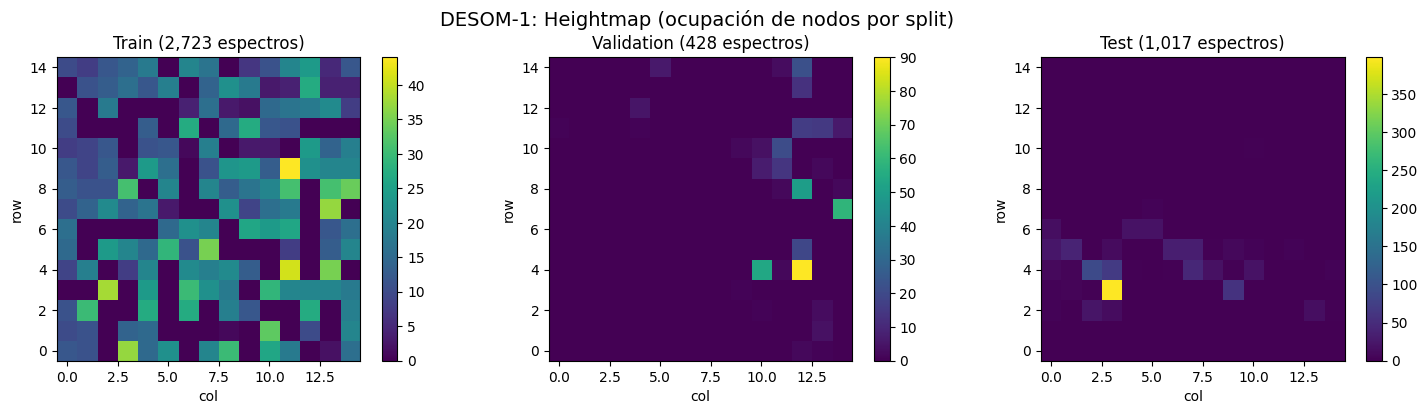

  ✓ desom1_heightmap.png

[2/5] Prototipos decodificados (grid 15x15)...


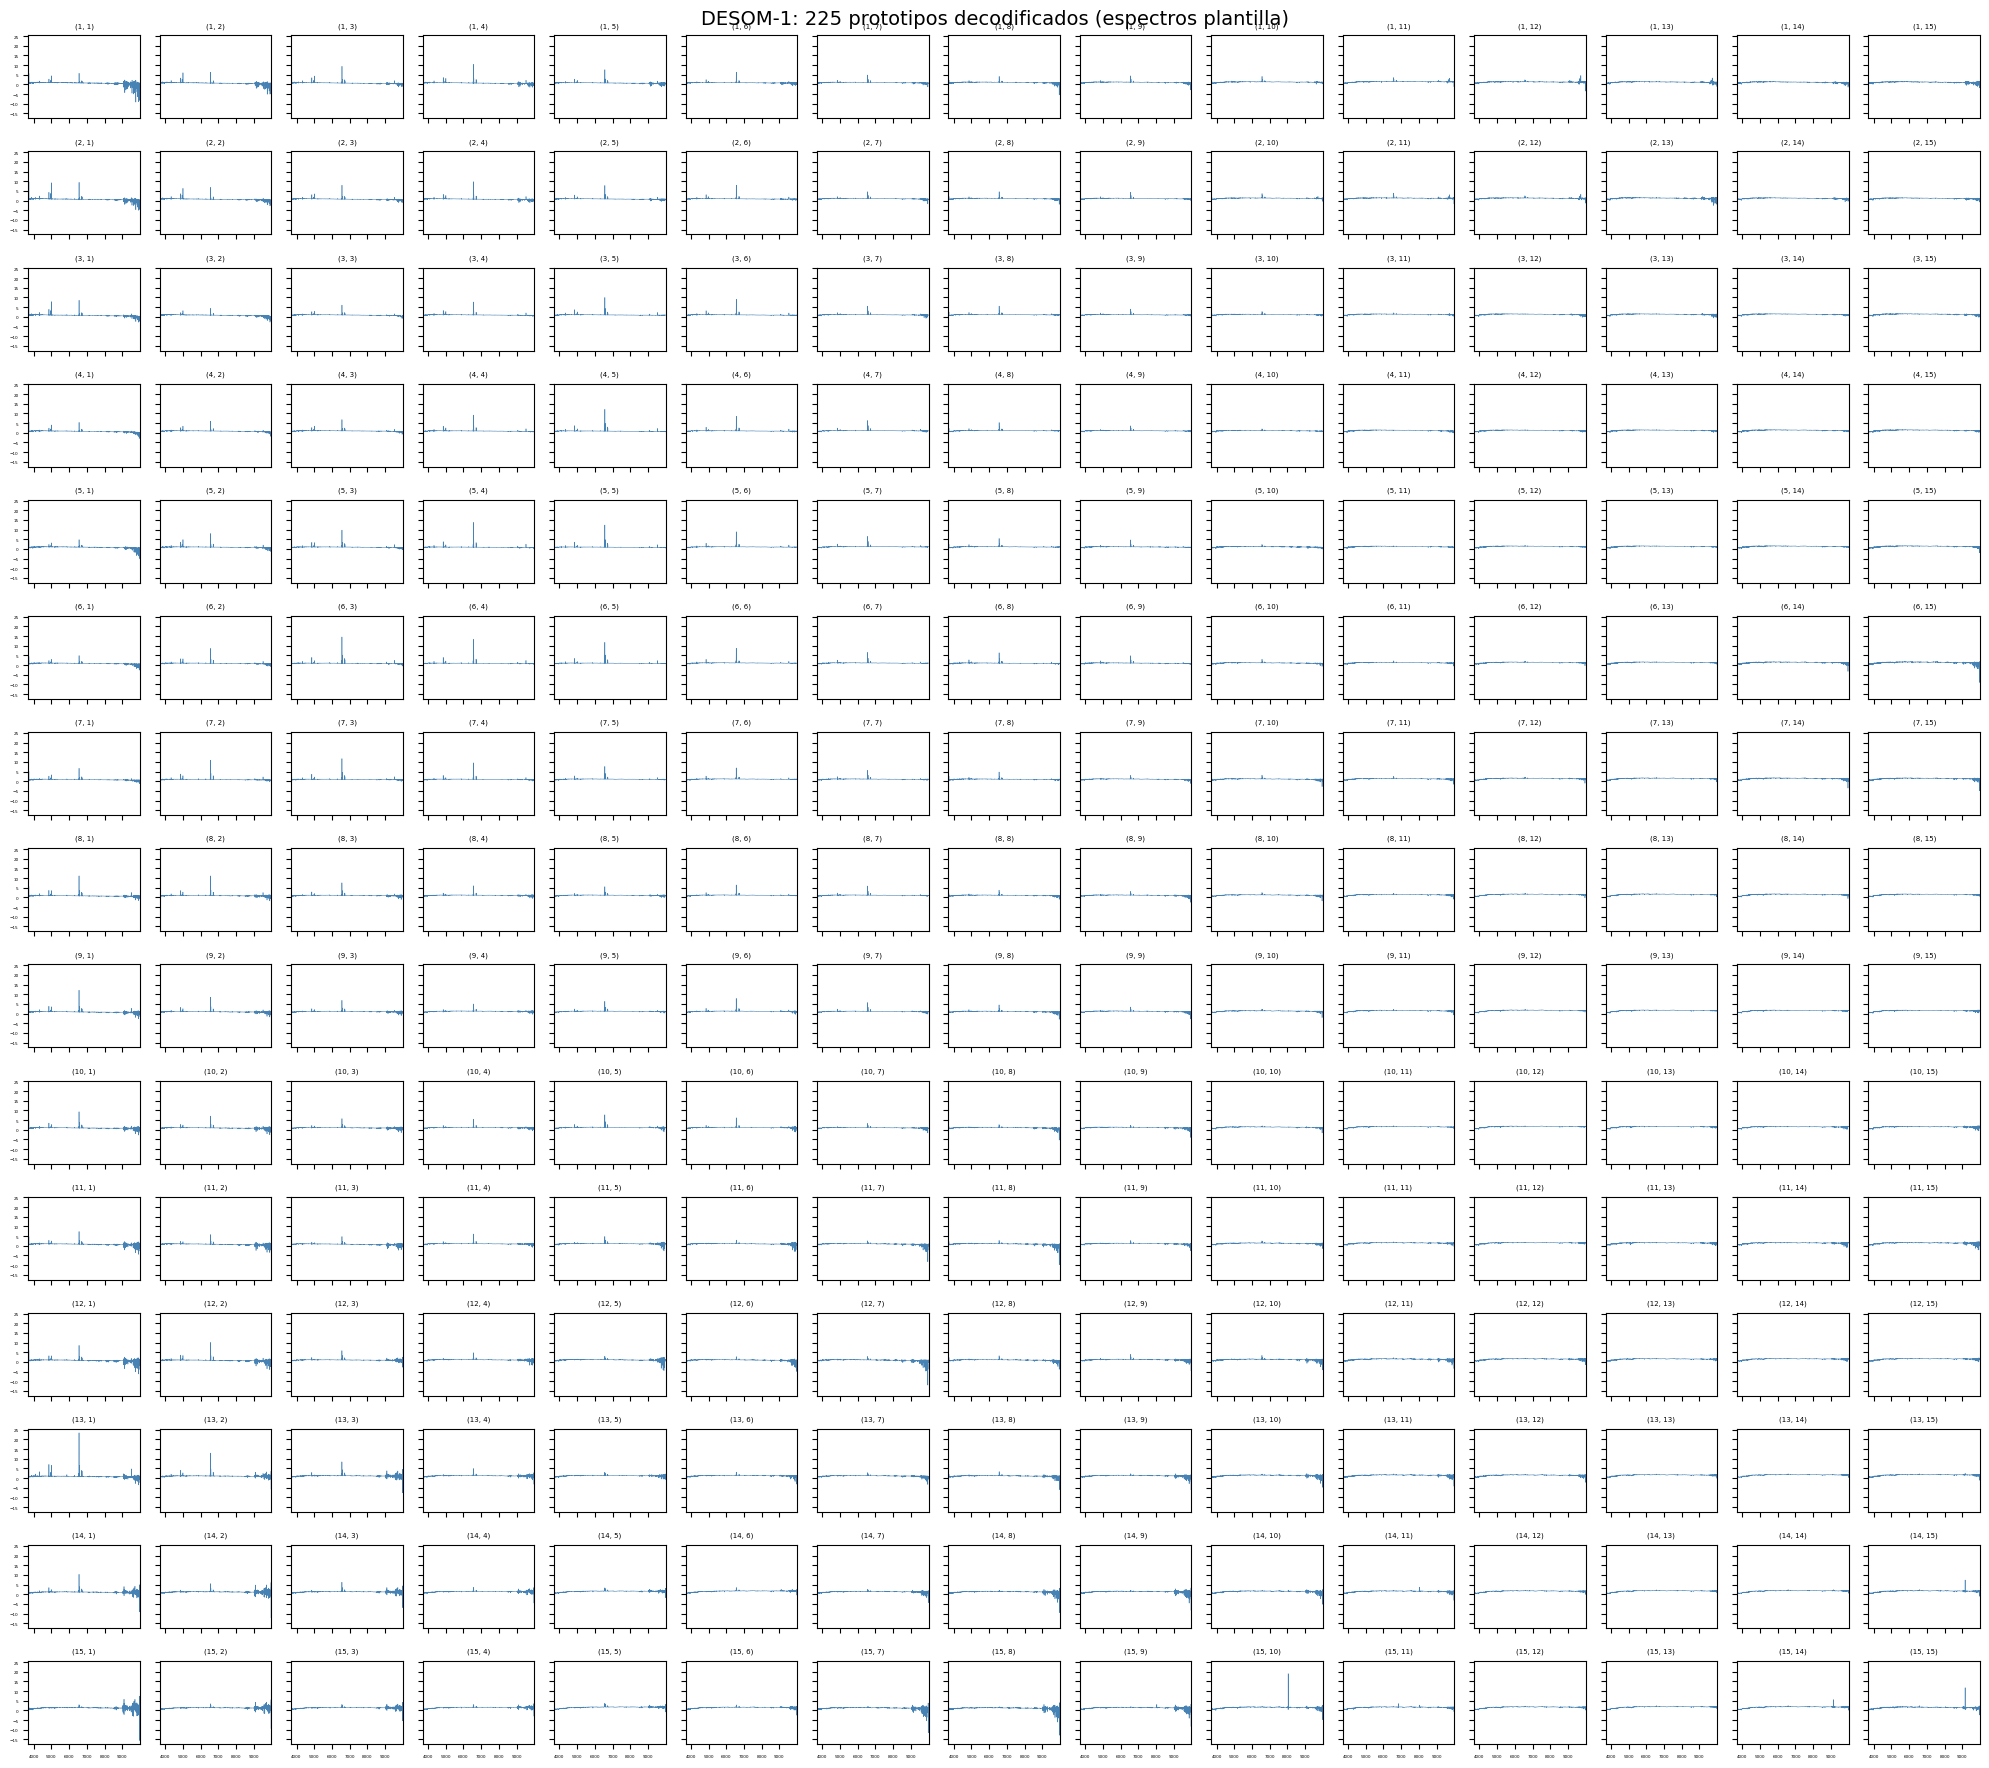

  ✓ desom1_templates.png

[3/5] Distribución BMU...


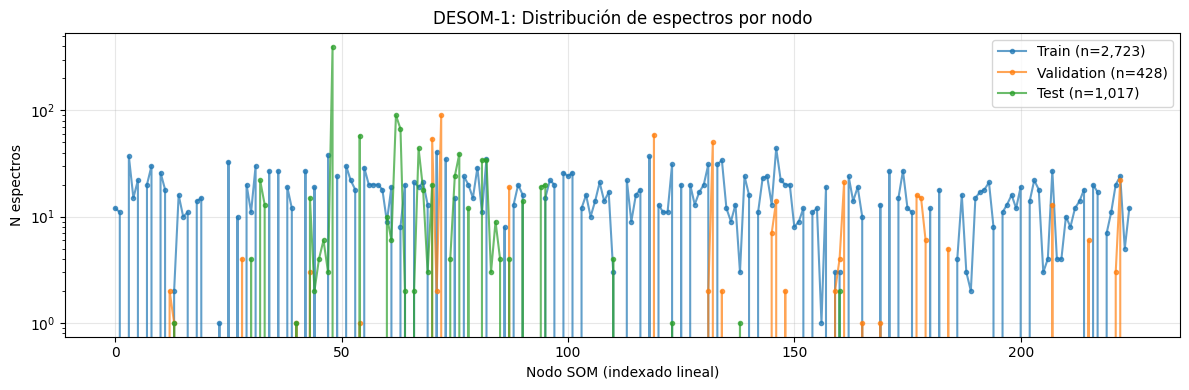

  ✓ desom1_bmu_distribution.png

[4/5] Curvas de aprendizaje...


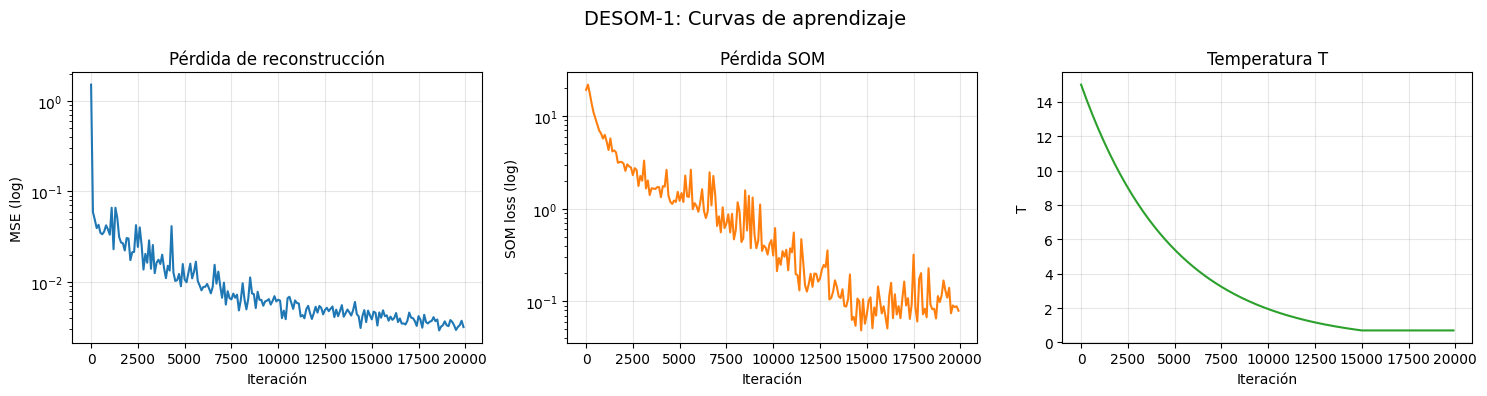

  ✓ desom1_learning_curves.png

[5/5] Ejemplos de fingerprints...


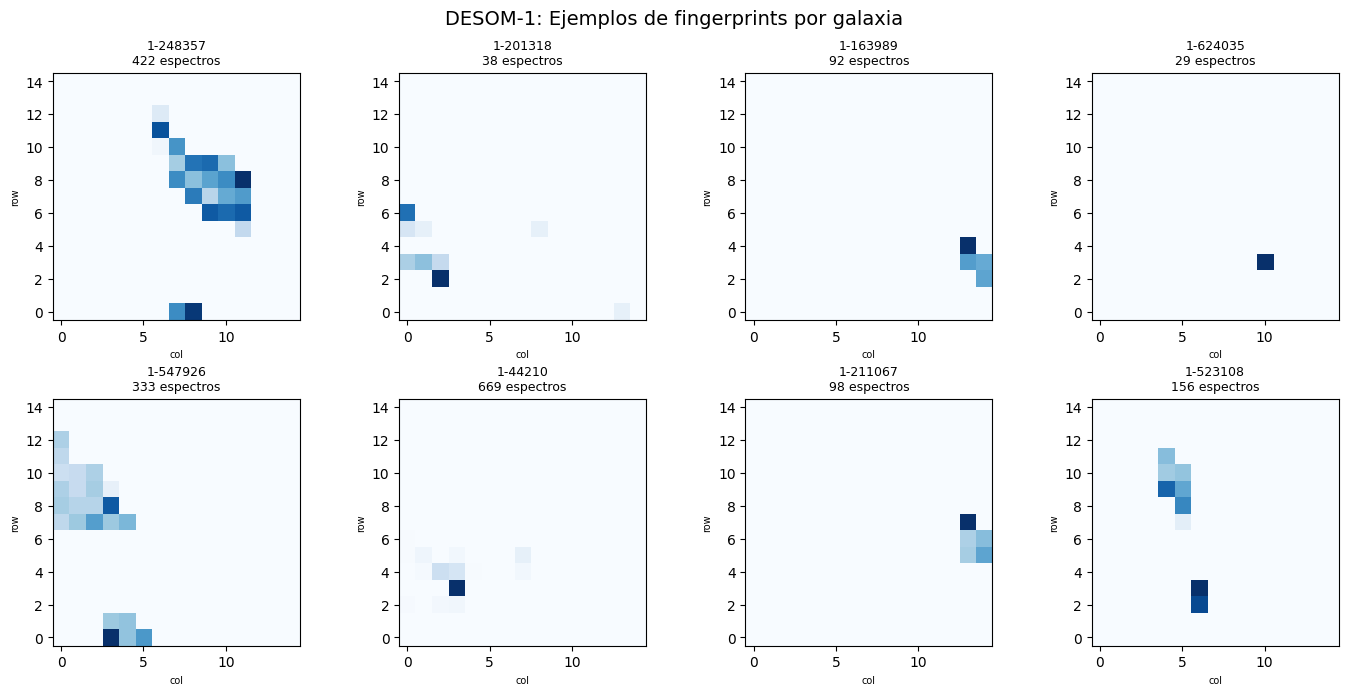

  ✓ desom1_fingerprint_examples.png

CELDA 3.6 COMPLETADA
  Figuras generadas: 5
    - desom1_bmu_distribution.png (118.7 KB)
    - desom1_fingerprint_examples.png (63.6 KB)
    - desom1_heightmap.png (65.5 KB)
    - desom1_learning_curves.png (105.3 KB)
    - desom1_templates.png (391.8 KB)

→ Continúa con la CELDA 3.7 (marcar Etapa 3 como completa).


In [22]:
# ============================================================================
# CELDA 3.6 — FIGURAS DE DIAGNÓSTICO DESOM-1
# ============================================================================
# Esta celda genera 5 figuras:
#   1. Heightmap (train/val/test)
#   2. Prototipos decodificados (grid 15x15)
#   3. Distribución BMU
#   4. Curvas de aprendizaje
#   5. Ejemplos de fingerprints
# ============================================================================

import matplotlib.pyplot as plt
import pandas as pd

print("=" * 70)
print("CELDA 3.6 — FIGURAS DE DIAGNÓSTICO")
print("=" * 70)

FIG_DIR = CTX.figures_dir
FIG_DIR.mkdir(exist_ok=True)

# --- Cargar productos necesarios ---
DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'
PROTO_PATH = CTX.desom1_dir / 'decoded_prototypes.npz'
BMU_CSV = CTX.fingerprints_dir / 'spectra_bmu.csv'
LOG_PATH = CTX.desom1_dir / 'desom_log.csv'

with np.load(DATASET_NPZ, allow_pickle=False) as z:
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)
    wave_rest = np.array(z['wave_rest'], dtype=np.float64)

bmu_df = pd.read_csv(BMU_CSV)
bmu_all = bmu_df['bmu'].values
split_all = bmu_df['split'].values

with np.load(FP_PATH, allow_pickle=False) as z:
    fingerprints = np.array(z['counts'], dtype=np.int32)
    gal_mangaIDs = np.array(z['mangaID'], dtype=str)

with np.load(PROTO_PATH, allow_pickle=False) as z:
    proto_decoded = np.array(z['spectra'], dtype=np.float32)

CFG_D1 = CTX.cfg['desom1']
map_size = tuple(CFG_D1['map_size'])
n_nodes = map_size[0] * map_size[1]

print(f"\nDatos cargados:")
print(f"  Espectros:    {len(bmu_all):,}")
print(f"  Fingerprints: {fingerprints.shape}")
print(f"  Prototipos:   {proto_decoded.shape}")


# ============================================================================
# Figura 1: Heightmap (ocupación por split)
# ============================================================================
print(f"\n[1/5] Heightmap...")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name, mask in [
    (axes[0], 'Train', split_all == 'train'),
    (axes[1], 'Validation', split_all == 'validation'),
    (axes[2], 'Test', split_all == 'test'),
]:
    counts = np.bincount(bmu_all[mask], minlength=n_nodes).reshape(map_size)
    im = ax.imshow(counts, origin='lower', cmap='viridis')
    ax.set_title(f'{name} ({mask.sum():,} espectros)')
    ax.set_xlabel('col')
    ax.set_ylabel('row')
    fig.colorbar(im, ax=ax)

fig.suptitle('DESOM-1: Heightmap (ocupación de nodos por split)', fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / 'desom1_heightmap.png', dpi=140, bbox_inches='tight')
plt.show()
print(f"  ✓ desom1_heightmap.png")


# ============================================================================
# Figura 2: Prototipos decodificados (grid 15x15)
# ============================================================================
print(f"\n[2/5] Prototipos decodificados (grid {map_size[0]}x{map_size[1]})...")

fig, axes = plt.subplots(map_size[0], map_size[1], figsize=(20, 18),
                         sharex=True, sharey=True)
for node in range(n_nodes):
    ax = axes[node // map_size[1], node % map_size[1]]
    ax.plot(wave_rest, proto_decoded[node], lw=0.4, color='steelblue')
    ax.set_title(f'({node // map_size[1] + 1}, {node % map_size[1] + 1})',
                 fontsize=5)
    ax.tick_params(labelsize=3)
    ax.set_xlim(wave_rest[0], wave_rest[-1])

fig.suptitle(f'DESOM-1: {n_nodes} prototipos decodificados (espectros plantilla)',
             fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / 'desom1_templates.png', dpi=140, bbox_inches='tight')
plt.show()
print(f"  ✓ desom1_templates.png")


# ============================================================================
# Figura 3: Distribución BMU (espectros por nodo)
# ============================================================================
print(f"\n[3/5] Distribución BMU...")

fig, ax = plt.subplots(figsize=(12, 4))
for name, mask, color in [
    ('Train', split_all == 'train', 'C0'),
    ('Validation', split_all == 'validation', 'C1'),
    ('Test', split_all == 'test', 'C2'),
]:
    counts = np.bincount(bmu_all[mask], minlength=n_nodes)
    ax.plot(counts, 'o-', label=f'{name} (n={mask.sum():,})',
            color=color, markersize=3, alpha=0.7)

ax.set_xlabel('Nodo SOM (indexado lineal)')
ax.set_ylabel('N espectros')
ax.set_title('DESOM-1: Distribución de espectros por nodo')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / 'desom1_bmu_distribution.png', dpi=140, bbox_inches='tight')
plt.show()
print(f"  ✓ desom1_bmu_distribution.png")


# ============================================================================
# Figura 4: Curvas de aprendizaje
# ============================================================================
print(f"\n[4/5] Curvas de aprendizaje...")

if LOG_PATH.exists():
    log_df = pd.read_csv(LOG_PATH)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Recon loss
    axes[0].semilogy(log_df['iter'], log_df['recon_loss'], label='Recon loss')
    axes[0].set_xlabel('Iteración')
    axes[0].set_ylabel('MSE (log)')
    axes[0].set_title('Pérdida de reconstrucción')
    axes[0].grid(alpha=0.3)

    # SOM loss
    axes[1].semilogy(log_df['iter'], log_df['som_loss'], label='SOM loss', color='C1')
    axes[1].set_xlabel('Iteración')
    axes[1].set_ylabel('SOM loss (log)')
    axes[1].set_title('Pérdida SOM')
    axes[1].grid(alpha=0.3)

    # Temperatura
    axes[2].plot(log_df['iter'], log_df['T'], color='C2')
    axes[2].set_xlabel('Iteración')
    axes[2].set_ylabel('T')
    axes[2].set_title('Temperatura T')
    axes[2].grid(alpha=0.3)

    fig.suptitle('DESOM-1: Curvas de aprendizaje', fontsize=14)
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'desom1_learning_curves.png', dpi=140, bbox_inches='tight')
    plt.show()
    print(f"  ✓ desom1_learning_curves.png")
else:
    print(f"  ⚠️  No se encontró {LOG_PATH.name}. Saltando.")


# ============================================================================
# Figura 5: Ejemplos de fingerprints
# ============================================================================
print(f"\n[5/5] Ejemplos de fingerprints...")

n_gal = len(fingerprints)
n_samples = min(8, n_gal)
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(n_gal, size=n_samples, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, gi in zip(axes.flat, sample_idx):
    fp = fingerprints[gi].reshape(map_size)
    im = ax.imshow(fp, origin='lower', cmap='Blues')
    n_esp = fingerprints[gi].sum()
    ax.set_title(f'{gal_mangaIDs[gi]}\n{n_esp} espectros', fontsize=9)
    ax.set_xlabel('col', fontsize=7)
    ax.set_ylabel('row', fontsize=7)

fig.suptitle('DESOM-1: Ejemplos de fingerprints por galaxia', fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / 'desom1_fingerprint_examples.png', dpi=140, bbox_inches='tight')
plt.show()
print(f"  ✓ desom1_fingerprint_examples.png")


# ============================================================================
# Resumen
# ============================================================================
figures = sorted([f.name for f in FIG_DIR.glob('desom1_*.png')])

print("\n" + "=" * 70)
print("CELDA 3.6 COMPLETADA")
print("=" * 70)
print(f"  Figuras generadas: {len(figures)}")
for fname in figures:
    fpath = FIG_DIR / fname
    print(f"    - {fname} ({fpath.stat().st_size/1024:.1f} KB)")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.7 (marcar Etapa 3 como completa).")

In [23]:
# ============================================================================
# CELDA 3.7 — MARCAR ETAPA 3 COMO COMPLETA
# ============================================================================
# Esta celda:
#   1. Verifica que todos los outputs de Etapa 3 existen.
#   2. Marca stage_03 = complete en el state.
#   3. Guarda el resumen final.
# ============================================================================

from pathlib import Path

print("=" * 70)
print("CELDA 3.7 — MARCAR ETAPA 3 COMO COMPLETA")
print("=" * 70)


# ============================================================================
# Verificar outputs
# ============================================================================
outputs_to_check = {
    'desom1_model': CTX.desom1_dir / 'DESOM_model_final.h5',
    'fingerprints': CTX.fingerprints_dir / 'fingerprints.npz',
    'spectra_bmu': CTX.fingerprints_dir / 'spectra_bmu.csv',
    'decoded_prototypes': CTX.desom1_dir / 'decoded_prototypes.npz',
    'bmu_metrics': CTX.desom1_dir / 'bmu_metrics.json',
    'training_metadata': CTX.desom1_dir / 'training_metadata.json',
}

print(f"\nVerificando outputs de Etapa 3:")
missing = []
for name, path in outputs_to_check.items():
    status = '✓' if path.exists() else '✗'
    if not path.exists():
        missing.append(name)
    size_str = f"{path.stat().st_size / 1024:.1f} KB" if path.exists() else "-"
    print(f"  {status} {name:22s} {size_str:>10s}")

require(len(missing) == 0, f'Faltan outputs: {missing}')


# ============================================================================
# Calcular hash del modelo principal
# ============================================================================
model_weights_path = CTX.desom1_dir / 'DESOM_model_final.h5'
output_sha = sha256_file(model_weights_path)

# Verificar hash del dataset (input)
dataset_npz = CTX.run_dir / 'desom1_dataset_ready.npz'
input_sha = sha256_file(dataset_npz)


# ============================================================================
# Actualizar state
# ============================================================================
training_metadata = json.loads(
    (CTX.desom1_dir / 'training_metadata.json').read_text()
)
bmu_metrics = json.loads(
    (CTX.desom1_dir / 'bmu_metrics.json').read_text()
)
fp_sha = sha256_file(CTX.fingerprints_dir / 'fingerprints.npz')

CTX.update_stage(
    'stage_03',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_03'),
    input_hash=input_sha,
    output_hash=output_sha,
    summary={
        'n_parameters': training_metadata['n_parameters'],
        'n_train': training_metadata['n_train'],
        'n_val': training_metadata['n_val'],
        'n_test': training_metadata['n_test'],
        'training_seconds': training_metadata['elapsed_seconds'],
        'n_checkpoints': training_metadata['n_checkpoints'],
        'mse_train': bmu_metrics['train']['mse'],
        'mse_val': bmu_metrics['validation']['mse'],
        'mse_test': bmu_metrics['test']['mse'],
        'n_occupied_nodes_train': bmu_metrics['train']['n_occupied_nodes'],
        'occupancy_train_percent': bmu_metrics['train']['occupancy_percent'],
        'fingerprints_sha256': fp_sha,
        'model_weights_sha256': output_sha,
    }
)

print(f"\n✓ stage_03 marcada como 'complete'")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN ETAPA 3 — DESOM-1")
print("=" * 70)
print(f"  Modelo DESOM-1:        DESOM_model_final.h5")
print(f"  Parámetros:            {training_metadata['n_parameters']:,}")
print(f"  Iteraciones:           {training_metadata['final_iteration']}")
print(f"  Tiempo de train:       {format_duration(training_metadata['elapsed_seconds'])}")
print(f"  Checkpoints:           {training_metadata['n_checkpoints']}")
print()
print(f"  MSE reconstrucción:")
print(f"    train:               {bmu_metrics['train']['mse']:.6f}")
print(f"    validation:          {bmu_metrics['validation']['mse']:.6f}")
print(f"    test:                {bmu_metrics['test']['mse']:.6f}")
print()
print(f"  Ocupación SOM (train): {bmu_metrics['train']['n_occupied_nodes']}/225 "
      f"({bmu_metrics['train']['occupancy_percent']:.1f}%)")
print()
print(f"  Fingerprints:")
print(f"    Galaxias:            {len(np.load(CTX.fingerprints_dir / 'fingerprints.npz', allow_pickle=False)['mangaID'])}")
print(f"    Fingerprints SHA:    {fp_sha[:32]}...")
print()
print(f"  Modelo final SHA:      {output_sha[:32]}...")
print("=" * 70)
print("CELDA 3.7 COMPLETADA")
print("=" * 70)
print("\n→ ETAPA 3 COMPLETA.")
print("→ Continúa con la SECCIÓN 4 (Etapa 4 — DESOM-2).")

CELDA 3.7 — MARCAR ETAPA 3 COMO COMPLETA

Verificando outputs de Etapa 3:
  ✓ desom1_model           37385.7 KB
  ✓ fingerprints               2.1 KB
  ✓ spectra_bmu              193.6 KB
  ✓ decoded_prototypes      3394.1 KB
  ✓ bmu_metrics                0.4 KB
  ✓ training_metadata          0.7 KB

✓ stage_03 marcada como 'complete'

RESUMEN ETAPA 3 — DESOM-1
  Modelo DESOM-1:        DESOM_model_final.h5
  Parámetros:            9,555,137
  Iteraciones:           20000
  Tiempo de train:       50m 18s
  Checkpoints:           40

  MSE reconstrucción:
    train:               0.003414
    validation:          0.014474
    test:                0.009411

  Ocupación SOM (train): 159/225 (70.7%)

  Fingerprints:
    Galaxias:            25
    Fingerprints SHA:    8c08deccd95b9a38c7a2b8a039c09676...

  Modelo final SHA:      2158a232f3e714bb361f41061f122cd3...
CELDA 3.7 COMPLETADA

→ ETAPA 3 COMPLETA.
→ Continúa con la SECCIÓN 4 (Etapa 4 — DESOM-2).


In [24]:
# ============================================================================
# CELDA 4.1 — VERIFICACIÓN DE ESTADO DE ETAPA 4 + AJUSTE DE HIPERPARÁMETROS
# ============================================================================
# Esta celda:
#   1. Diagnostica el estado de Etapa 4.
#   2. Si hay pocas galaxias, propone ajustar map_size.
#   3. Chequea si los hiperparámetros son razonables.
#   4. Pregunta interactivamente si actualizarlos.
#   5. Marca stage_04 como in_progress.
# ============================================================================

import copy
import json
from pathlib import Path

print("=" * 70)
print("CELDA 4.1 — VERIFICACIÓN DE ESTADO DE ETAPA 4")
print("=" * 70)


# ============================================================================
# 1. Diagnóstico de Etapa 4
# ============================================================================
STAGE_04 = 'stage_04'
STAGE_04_COMPLETE = False

DESOM2_MODEL = CTX.desom2_dir / 'DESOM2_model_final.h5'
ASSIGNMENTS_CSV = CTX.desom2_dir / 'galaxy_assignments.csv'

def diagnose_stage_04() -> dict:
    """Diagnóstico de Etapa 4."""
    s = CTX.get_stage(STAGE_04)

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not DESOM2_MODEL.exists():
        return {'status': 'inconsistent', 'reason': f'Falta {DESOM2_MODEL.name}'}
    if not ASSIGNMENTS_CSV.exists():
        return {'status': 'inconsistent', 'reason': f'Falta {ASSIGNMENTS_CSV.name}'}

    # config_hash
    expected_config = CTX.config_hash(STAGE_04)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # input_hash (fingerprints)
    fp_path = CTX.fingerprints_dir / 'fingerprints.npz'
    if not fp_path.exists():
        return {'status': 'inconsistent', 'reason': 'Input ya no existe'}
    actual_input_sha = sha256_file(fp_path)
    if s.get('input_hash') != actual_input_sha:
        return {'status': 'inconsistent', 'reason': 'Input cambió'}

    # output_hash
    actual_output_sha = sha256_file(DESOM2_MODEL)
    if s.get('output_hash') != actual_output_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado'}

    return {'status': 'complete', 'reason': 'OK'}


print(f"\n[1/4] Diagnosticando Etapa 4...")
diag = diagnose_stage_04()
print(f"  Estado: {diag['status']}")
print(f"  Razón:  {diag['reason']}")


# ============================================================================
# 2. CASO A: etapa completa → saltar
# ============================================================================
if diag['status'] == 'complete':
    STAGE_04_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 4 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_04).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ PIPELINE COMPLETO.")


# ============================================================================
# 3. CASO B: etapa no completa → chequeo de hiperparámetros
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 4")
    print("=" * 70)

    # Verificar input (fingerprints)
    fp_path = CTX.fingerprints_dir / 'fingerprints.npz'
    require(fp_path.exists(), f'Falta input: {fp_path}')

    with np.load(fp_path, allow_pickle=False) as z:
        n_galaxies = len(z['mangaID'])
        fp_shape = z['counts'].shape

    print(f"\n  Input: {fp_path.name}")
    print(f"  Galaxias: {n_galaxies}")
    print(f"  Fingerprints shape: {fp_shape}")

    # --- AVISO sobre tamaño de muestra ---
    print("\n" + "─" * 70)
    print("⚠️  ADVERTENCIA: MUESTRA MUY PEQUEÑA PARA DESOM-2")
    print("─" * 70)
    print(f"  Galaxias: {n_galaxies}")
    print(f"  El paper usa 4609 galaxias para DESOM-2.")
    print()
    print(f"  Con solo {n_galaxies} galaxias:")
    print(f"    - Un mapa 10x10 = 100 nodos tendrá muchos nodos vacíos.")
    print(f"    - El entrenamiento no generalizará bien.")
    print(f"    - Los prototipos decodificados serán poco interpretables.")
    print()
    print(f"  Este DESOM-2 servirá para VERIFICAR que el pipeline funciona,")
    print(f"  pero los resultados científicos serán limitados.")
    print()
    print(f"  Para resultados reales, considera un experimento con n_target=500.")
    print()

    # --- Sugerir map_size más pequeño ---
    d2 = CTX.cfg['desom2']
    map_size_current = tuple(d2['map_size'])
    n_nodes_current = map_size_current[0] * map_size_current[1]

    # Regla: al menos 5 galaxias por nodo
    min_gal_per_node = 5
    max_viable_nodes = max(4, n_galaxies // min_gal_per_node)
    recommended_map_side = max(2, int(max_viable_nodes ** 0.5))
    recommended_map_size = (recommended_map_side, recommended_map_side)
    n_nodes_recommended = recommended_map_size[0] * recommended_map_size[1]

    print("  Opciones:")
    print(f"    [1] Mantener map_size={map_size_current} ({n_nodes_current} nodos, "
          f"~{n_galaxies/n_nodes_current:.1f} gal/nodo)")
    print(f"    [2] Reducir a map_size={recommended_map_size} ({n_nodes_recommended} nodos, "
          f"~{n_galaxies/n_nodes_recommended:.1f} gal/nodo) — recomendado")
    print(f"    [3] Salir (crear experimento nuevo con más galaxias)")

    choice_map = input("\n  Elección [1/2/3]: ").strip()

    if choice_map == '3':
        raise SystemExit(
            "\n  ✓ Abortado. Considera crear un experimento con n_target=500:\n"
            "    1. Runtime → Restart runtime\n"
            "    2. Ejecuta Celdas 0.1 → 0.2 (elige [B] Crear nuevo, n_target=500)\n"
            "    3. Ejecuta todo el pipeline desde la Etapa 1"
        )

    # --- Chequeo de iteraciones ---
    MIN_RECOMMENDED_ITER = 20000
    MIN_RECOMMENDED_SOM_ITER = 15000

    iterations_current = d2['iterations']
    som_iterations_current = d2['som_iterations']
    need_update_iter = (
        iterations_current < MIN_RECOMMENDED_ITER or
        som_iterations_current < MIN_RECOMMENDED_SOM_ITER
    )

    if need_update_iter:
        print("\n" + "─" * 70)
        print("⚠️  HIPERPARÁMETROS DE ENTRENAMIENTO BAJOS")
        print("─" * 70)
        print(f"  Actual desom2.iterations:       {iterations_current}  (recomendado ≥ {MIN_RECOMMENDED_ITER})")
        print(f"  Actual desom2.som_iterations:   {som_iterations_current}  (recomendado ≥ {MIN_RECOMMENDED_SOM_ITER})")
        print()
        print("  Opciones:")
        print(f"    [1] Subir a {MIN_RECOMMENDED_ITER}/{MIN_RECOMMENDED_SOM_ITER} (recomendado)")
        print(f"    [2] Mantener los valores actuales ({iterations_current}/{som_iterations_current})")
        print(f"    [3] Valores del paper (40000/35000)")

        choice_iter = input("\n  Elección [1/2/3]: ").strip()
        if choice_iter == '1':
            new_iter = MIN_RECOMMENDED_ITER
            new_som = MIN_RECOMMENDED_SOM_ITER
        elif choice_iter == '2':
            new_iter = iterations_current
            new_som = som_iterations_current
        elif choice_iter == '3':
            new_iter = 40000
            new_som = 35000
        else:
            raise ValueError(f"Opción inválida: {choice_iter}")
    else:
        new_iter = iterations_current
        new_som = som_iterations_current

    # --- Aplicar cambios ---
    cfg_path = CTX.run_dir / 'pipeline_config_active.json'
    cfg_on_disk = json.loads(cfg_path.read_text())

    changes = []

    # map_size
    if choice_map == '2':
        cfg_on_disk['desom2']['map_size'] = list(recommended_map_size)
        CTX.cfg['desom2']['map_size'] = list(recommended_map_size)
        changes.append({
            'parameter': 'desom2.map_size',
            'old': list(map_size_current),
            'new': list(recommended_map_size),
            'reason': f'Sample size too small ({n_galaxies} galaxias) for 10x10 map',
        })
        print(f"\n  → map_size: {map_size_current} → {recommended_map_size}")

    # iterations
    if new_iter != iterations_current or new_som != som_iterations_current:
        cfg_on_disk['desom2']['iterations'] = new_iter
        cfg_on_disk['desom2']['som_iterations'] = new_som
        CTX.cfg['desom2']['iterations'] = new_iter
        CTX.cfg['desom2']['som_iterations'] = new_som
        changes.append({
            'parameter': 'desom2.iterations / desom2.som_iterations',
            'old': [iterations_current, som_iterations_current],
            'new': [new_iter, new_som],
            'reason': 'Below recommended minimum for this sample size',
        })
        print(f"  → iterations: {iterations_current}/{som_iterations_current} → {new_iter}/{new_som}")

    if changes:
        cfg_on_disk.setdefault('manual_overrides', []).extend([
            {'at': now_utc_iso(), **c} for c in changes
        ])
        atomic_write_json(cfg_path, cfg_on_disk)
        print(f"  ✓ pipeline_config_active.json actualizado")

    # --- Marcar stage_04 como in_progress ---
    CTX.update_stage(
        STAGE_04,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 4.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 4 completa:     {STAGE_04_COMPLETE}")
print(f"  desom2.map_size:      {CTX.cfg['desom2']['map_size']}")
print(f"  desom2.iterations:    {CTX.cfg['desom2']['iterations']}")
print(f"  desom2.som_iterations: {CTX.cfg['desom2']['som_iterations']}")
print("=" * 70)

if STAGE_04_COMPLETE:
    print("\n→ PIPELINE COMPLETO.")
else:
    print("\n→ Continúa con la CELDA 4.2 (carga y preprocesamiento de fingerprints).")

CELDA 4.1 — VERIFICACIÓN DE ESTADO DE ETAPA 4

[1/4] Diagnosticando Etapa 4...
  Estado: pending
  Razón:  No completada previamente

→ Preparando ejecución de Etapa 4

  Input: fingerprints.npz
  Galaxias: 25
  Fingerprints shape: (25, 225)

──────────────────────────────────────────────────────────────────────
⚠️  ADVERTENCIA: MUESTRA MUY PEQUEÑA PARA DESOM-2
──────────────────────────────────────────────────────────────────────
  Galaxias: 25
  El paper usa 4609 galaxias para DESOM-2.

  Con solo 25 galaxias:
    - Un mapa 10x10 = 100 nodos tendrá muchos nodos vacíos.
    - El entrenamiento no generalizará bien.
    - Los prototipos decodificados serán poco interpretables.

  Este DESOM-2 servirá para VERIFICAR que el pipeline funciona,
  pero los resultados científicos serán limitados.

  Para resultados reales, considera un experimento con n_target=500.

  Opciones:
    [1] Mantener map_size=(10, 10) (100 nodos, ~0.2 gal/nodo)
    [2] Reducir a map_size=(2, 2) (4 nodos, ~6.2 gal/n

In [26]:
# ============================================================================
# CELDA 4.2 — CARGA DE FINGERPRINTS Y PREPROCESAMIENTO
# ============================================================================
# Esta celda:
#   1. Carga fingerprints.npz (N x 225 features).
#   2. Clipping percentil 99.9 por nodo.
#   3. MinMaxScaler por nodo (columnas).
#   4. MinMaxScaler por fingerprint (filas).
#   5. Reshape a (N, 15, 15, 1).
#   6. Split 90/5/5 (train/val/test).
#   7. Guarda inputs_and_split.npz.
# ============================================================================

import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from pathlib import Path

print("=" * 70)
print("CELDA 4.2 — CARGA Y PREPROCESAMIENTO DE FINGERPRINTS")
print("=" * 70)


# ============================================================================
# 1. Cargar fingerprints
# ============================================================================
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'
require(FP_PATH.exists(), f'Falta: {FP_PATH}')

print(f"\n[1/4] Cargando fingerprints...")
with np.load(FP_PATH, allow_pickle=False) as z:
    gal_mangaID = np.array(z['mangaID'], dtype=str)
    gal_plateifu = np.array(z['plateifu'], dtype=str)
    F = np.array(z['counts'], dtype=np.float64)
    n_spectra_per_gal = np.array(z['n_spectra'], dtype=np.int32)
    map_size_desom1 = tuple(z['map_size'])

n_galaxies = F.shape[0]
n_features = F.shape[1]
print(f"  Galaxias:  {n_galaxies}")
print(f"  Features:  {n_features}")
print(f"  Mapa D1:   {map_size_desom1}")


# ============================================================================
# 2. Clipping percentil 99.9 por nodo
# ============================================================================
print(f"\n[2/4] Clipping percentil 99.9 por nodo...")

clipping_percentile = CTX.cfg['desom2']['clipping_percentile']  # 99.9
percentile_vector = np.percentile(F, clipping_percentile, axis=0)

# Aplicar clipping
F_clipped = np.clip(F, 0, percentile_vector)
n_clipped = int((F > percentile_vector).sum())
print(f"  Umbrales calculados (percentil {clipping_percentile})")
print(f"  Valores clipeados: {n_clipped} / {F.size}")


# ============================================================================
# 3. MinMaxScaler por nodo (columnas)
# ============================================================================
print(f"\n[3/4] Normalización doble MinMaxScaler...")

scaler_nodes = MinMaxScaler()
F_scaled_nodes = scaler_nodes.fit_transform(F_clipped)
print(f"  Scaler por nodo:      [{F_scaled_nodes.min():.3f}, {F_scaled_nodes.max():.3f}]")


# ============================================================================
# 4. MinMaxScaler por fingerprint (filas)
# ============================================================================
scaler_rows = MinMaxScaler()
F_scaled_both = scaler_rows.fit_transform(F_scaled_nodes.T).T
print(f"  Scaler por fingerprint: [{F_scaled_both.min():.3f}, {F_scaled_both.max():.3f}]")


# ============================================================================
# 5. Reshape a (N, 15, 15, 1)
# ============================================================================
F_reshaped = F_scaled_both.reshape(-1, map_size_desom1[0], map_size_desom1[1], 1).astype(np.float32)
print(f"\n  Shape final: {F_reshaped.shape}")
print(f"  Rango:       [{F_reshaped.min():.4f}, {F_reshaped.max():.4f}]")


# ============================================================================
# 6. Split 90/5/5
# ============================================================================
print(f"\n[4/4] Split 90/5/5...")

ids_all = np.arange(n_galaxies)
ids_train, ids_temp = train_test_split(
    ids_all, train_size=0.9, random_state=SEED
)
ids_test, ids_val = train_test_split(
    ids_temp, train_size=0.5, random_state=SEED
)

print(f"  Train: {len(ids_train)} galaxias")
print(f"  Val:   {len(ids_val)} galaxias")
print(f"  Test:  {len(ids_test)} galaxias")

# Guardar split en un array 'split_desom2'
split_desom2 = np.full(n_galaxies, '', dtype='U10')
split_desom2[ids_train] = 'train'
split_desom2[ids_val] = 'validation'
split_desom2[ids_test] = 'test'


# ============================================================================
# 7. Guardar productos
# ============================================================================
print(f"\nGuardando inputs...")

INPUTS_PATH = CTX.desom2_dir / 'inputs_and_split.npz'
np.savez_compressed(
    INPUTS_PATH,
    X=F_reshaped,
    mangaID=gal_mangaID,
    plateifu=gal_plateifu,
    n_spectra=n_spectra_per_gal,
    split=split_desom2,
    train_idx=ids_train,
    validation_idx=ids_val,
    test_idx=ids_test,
    # Parámetros de preprocessing (para reproducibilidad)
    clipping_thresholds=percentile_vector,
    node_scale=scaler_nodes.scale_,
    node_min=scaler_nodes.min_,
    row_scale=scaler_rows.scale_,
    row_min=scaler_rows.min_,
    map_size_desom1=np.array(map_size_desom1),
)

input_sha = sha256_file(INPUTS_PATH)
print(f"  {INPUTS_PATH.name} ({INPUTS_PATH.stat().st_size/1e3:.1f} KB)")
print(f"    SHA-256: {input_sha[:32]}...")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN CELDA 4.2 — PREPROCESAMIENTO")
print("=" * 70)
print(f"  Galaxias:               {n_galaxies}")
print(f"  Features (fingerprint): {n_features}")
print(f"  Shape final X:          {F_reshaped.shape}")
print(f"  Rango:                  [{F_reshaped.min():.4f}, {F_reshaped.max():.4f}]")
print()
print(f"  Split:")
print(f"    train:      {len(ids_train):2d} galaxias")
print(f"    validation: {len(ids_val):2d} galaxias")
print(f"    test:       {len(ids_test):2d} galaxias")
print()
print(f"  Preprocessing:")
print(f"    Clipping:   percentil {clipping_percentile}")
print(f"    Normalizacion: MinMaxScaler por nodo + por fingerprint")
print()
print(f"  Input SHA:              {input_sha[:32]}...")
print("=" * 70)
print("CELDA 4.2 COMPLETADA")
print("=" * 70)
print("\n-> Continua con la CELDA 4.3 (entrenamiento DESOM-2).")

CELDA 4.2 — CARGA Y PREPROCESAMIENTO DE FINGERPRINTS

[1/4] Cargando fingerprints...
  Galaxias:  25
  Features:  225
  Mapa D1:   (np.int64(15), np.int64(15))

[2/4] Clipping percentil 99.9 por nodo...
  Umbrales calculados (percentil 99.9)
  Valores clipeados: 183 / 5625

[3/4] Normalización doble MinMaxScaler...
  Scaler por nodo:      [0.000, 1.000]
  Scaler por fingerprint: [0.000, 1.000]

  Shape final: (25, 15, 15, 1)
  Rango:       [0.0000, 1.0000]

[4/4] Split 90/5/5...
  Train: 22 galaxias
  Val:   2 galaxias
  Test:  1 galaxias

Guardando inputs...
  inputs_and_split.npz (5.5 KB)
    SHA-256: 614055228e79b1bba7092b2c108d8f3d...

RESUMEN CELDA 4.2 — PREPROCESAMIENTO
  Galaxias:               25
  Features (fingerprint): 225
  Shape final X:          (25, 15, 15, 1)
  Rango:                  [0.0000, 1.0000]

  Split:
    train:      22 galaxias
    validation:  2 galaxias
    test:        1 galaxias

  Preprocessing:
    Clipping:   percentil 99.9
    Normalizacion: MinMaxSca

In [27]:
# ============================================================================
# CELDA 4.3 — ENTRENAMIENTO DESOM-2
# ============================================================================
# Esta celda:
#   1. Carga inputs_and_split.npz.
#   2. Construye el modelo DESOM-2 (CNN 2D sobre fingerprints 15x15).
#   3. Inicializa el SOM con muestras del train set.
#   4. Entrena (con log en CSV).
#   5. Guarda el modelo final y metadata.
# ============================================================================

import time as _time
import pandas as pd
from pathlib import Path

print("=" * 70)
print("CELDA 4.3 — ENTRENAMIENTO DESOM-2")
print("=" * 70)


# ============================================================================
# 1. Cargar inputs
# ============================================================================
INPUTS_PATH = CTX.desom2_dir / 'inputs_and_split.npz'
require(INPUTS_PATH.exists(), f'Falta: {INPUTS_PATH}')

print(f"\n[1/3] Cargando inputs...")
with np.load(INPUTS_PATH, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    gal_mangaID = np.array(z['mangaID'], dtype=str)
    gal_plateifu = np.array(z['plateifu'], dtype=str)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)
    map_size_desom1 = tuple(int(v) for v in z['map_size_desom1'])

X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

print(f"  X_train: {X_train.shape}")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")


# ============================================================================
# 2. Construir modelo
# ============================================================================
CFG_D2 = CTX.cfg['desom2']
input_dims = (map_size_desom1[0], map_size_desom1[1], 1)
map_size = tuple(CFG_D2['map_size'])
latent_dims = CFG_D2['latent_dims']
gamma = CFG_D2['gamma']
lr = CFG_D2['lr']
iterations = CFG_D2['iterations']
som_iterations = CFG_D2['som_iterations']
batch_size = CFG_D2['batch_size']
if isinstance(batch_size, str) or batch_size == 'auto':
    # Resolver 'auto': con 22 galaxias de train, batch=16 o 22
    batch_size = min(16, len(X_train))
    print(f"  batch_size='auto' resuelto a {batch_size}")
Tmax, Tmin = CFG_D2['Tmax'], CFG_D2['Tmin']

print(f"\n[2/3] Construyendo modelo...")
print(f"  input_dims:       {input_dims}")
print(f"  map_size:         {map_size} ({map_size[0]*map_size[1]} nodos)")
print(f"  latent_dims:      {latent_dims}")
print(f"  gamma:            {gamma}")
print(f"  lr:               {lr}")
print(f"  iterations:       {iterations}")
print(f"  som_iterations:   {som_iterations}")
print(f"  batch_size:       {batch_size}")
print(f"  Tmax / Tmin:      {Tmax} / {Tmin}")

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_d2 = DESOM2(
    input_dims=input_dims,
    map_size=map_size,
    latent_dims=latent_dims,
)
model_d2.initialize()
model_d2.compile(gamma, keras.optimizers.Adam(learning_rate=lr))

n_params = model_d2.model.count_params()
print(f"  Parámetros:       {n_params:,}")

# Inicializar SOM
print(f"\n  Inicializando SOM...")
np.random.seed(SEED)
if len(X_train) < model_d2.n_prototypes:
    chosen = np.random.choice(len(X_train), size=model_d2.n_prototypes, replace=True)
    model_d2.model.get_layer(name='SOM').set_weights([model_d2.encode(X_train[chosen])])
    print(f"  Inicialización con reemplazo ({len(X_train)} < {model_d2.n_prototypes})")
else:
    model_d2.init_som_weights(X_train)
    print(f"  Inicialización sin reemplazo")


# ============================================================================
# 3. Entrenar (versión adaptada del fit del repo, con log)
# ============================================================================
print(f"\n[3/3] Entrenando DESOM-2...")
print(f"{'='*70}")

# --- Preparar log CSV ---
LOG_PATH = CTX.desom2_dir / f'desom2_log_{latent_dims}.csv'

# --- Bucle de entrenamiento (replica de DESOM2_architectures.DESOM.fit) ---
started = _time.time()

with LOG_PATH.open('w') as logfile:
    fieldnames = ['iter', 'T', 'loss', 'recon_loss', 'som_loss',
                  'val_loss', 'val_recon', 'val_som', 'elapsed']
    writer = csv.DictWriter(logfile, fieldnames=fieldnames)
    writer.writeheader()

    index = 0
    rng = np.random.default_rng(SEED)

    for ite in range(iterations):
        # --- Siguiente batch ---
        if (index + 1) * batch_size >= len(X_train):
            X_batch = X_train[index * batch_size:]
            index = 0
        else:
            X_batch = X_train[index * batch_size:(index + 1) * batch_size]
            index += 1

        if len(X_batch) == 0:
            continue

        # --- Asignaciones SOM ---
        _, d = model_d2.model.predict(X_batch, verbose=0)
        y_pred = d.argmin(axis=1)

        # --- Temperatura ---
        if ite < som_iterations:
            T = Tmax * (Tmin / Tmax) ** (ite / max(som_iterations - 1, 1))
        else:
            T = Tmin

        # --- Neighborhood weights ---
        w_batch = model_d2.neighborhood_function(model_d2.map_dist(y_pred), T)

        # --- Train step ---
        loss = model_d2.model.train_on_batch(X_batch, [X_batch, w_batch])
        loss = np.asarray(loss)

        # --- Log cada 25 iteraciones ---
        if ite % 25 == 0:
            elapsed = _time.time() - started
            val_loss_arr = None
            if len(X_val) > 0:
                _, d_val = model_d2.model.predict(X_val, verbose=0)
                y_val_pred = d_val.argmin(axis=1)
                w_val = model_d2.neighborhood_function(model_d2.map_dist(y_val_pred), T)
                val_loss_arr = np.asarray(model_d2.model.test_on_batch(X_val, [X_val, w_val]))
            else:
                val_loss_arr = [np.nan, np.nan, np.nan]

            writer.writerow({
                'iter': ite,
                'T': float(T),
                'loss': float(loss[0]),
                'recon_loss': float(loss[1]),
                'som_loss': float(loss[2]),
                'val_loss': float(val_loss_arr[0]),
                'val_recon': float(val_loss_arr[1]),
                'val_som': float(val_loss_arr[2]),
                'elapsed': float(elapsed),
            })
            logfile.flush()

            print(f"  iter {ite:5d} | T={T:5.2f} | "
                  f"loss={loss[0]:.5f} | recon={loss[1]:.5f} | "
                  f"som={loss[2]:.4f} | {format_duration(elapsed)}")

elapsed = _time.time() - started
print(f"\nEntrenamiento completado: {format_duration(elapsed)}")


# ============================================================================
# 4. Guardar modelo final
# ============================================================================
FINAL_WEIGHTS = CTX.desom2_dir / 'DESOM2_model_final.h5'
model_d2.model.save_weights(str(FINAL_WEIGHTS))
weights_sha = sha256_file(FINAL_WEIGHTS)

metadata = {
    'config': CFG_D2,
    'n_parameters': int(n_params),
    'n_train': int(len(X_train)),
    'n_val': int(len(X_val)),
    'n_test': int(len(X_test)),
    'elapsed_seconds': float(elapsed),
    'weights_path': str(FINAL_WEIGHTS.relative_to(CTX.run_dir)),
    'weights_sha256': weights_sha,
    'completed_at': now_utc_iso(),
    'seed': SEED,
    'map_size': list(map_size),
    'input_dims': list(input_dims),
}
atomic_write_json(CTX.desom2_dir / 'training_metadata.json', metadata)

print(f"\nModelo final: {FINAL_WEIGHTS.name} ({FINAL_WEIGHTS.stat().st_size / 1e6:.2f} MB)")
print(f"SHA-256: {weights_sha[:32]}...")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 4.3 COMPLETADA")
print("=" * 70)
print(f"  Iteraciones:  {iterations}")
print(f"  Tiempo total: {format_duration(elapsed)}")
print(f"  Modelo final: {FINAL_WEIGHTS.name}")
print(f"  SHA-256:      {weights_sha[:32]}...")
print("=" * 70)
print("\n-> Continua con la CELDA 4.4 (BMU de galaxias y figuras).")

CELDA 4.3 — ENTRENAMIENTO DESOM-2

[1/3] Cargando inputs...
  X_train: (22, 15, 15, 1)
  X_val:   (2, 15, 15, 1)
  X_test:  (1, 15, 15, 1)

[2/3] Construyendo modelo...
  input_dims:       (15, 15, 1)
  map_size:         (2, 2) (4 nodos)
  latent_dims:      128
  gamma:            8e-06
  lr:               0.0001
  iterations:       434
  som_iterations:   380
  batch_size:       16
  Tmax / Tmin:      15.0 / 0.5
cnn final (16 filters) 
  Parámetros:       928,337

  Inicializando SOM...
1/1 [==============================] - 0s 75ms/step
  Inicialización sin reemplazo

[3/3] Entrenando DESOM-2...
  iter     0 | T=15.00 | loss=0.03502 | recon=0.03499 | som=3.6947 | 2s
  iter    25 | T=11.99 | loss=0.03934 | recon=0.03929 | som=5.7196 | 5s
  iter    50 | T= 9.58 | loss=0.02016 | recon=0.02010 | som=8.3610 | 7s
  iter    75 | T= 7.65 | loss=0.00590 | recon=0.00570 | som=26.1392 | 9s
  iter   100 | T= 6.11 | loss=0.00779 | recon=0.00765 | som=17.1390 | 11s
  iter   125 | T= 4.89 | loss=0.

CELDA 4.4 — BMU DE GALAXIAS Y FIGURAS

[1/4] Cargando datos y modelo...
cnn final (16 filters) 
  Galaxias: 25
  Nodos:    4 (2x2)

[2/4] Calculando BMU y reconstrucción...
  Reconstrucción: (25, 15, 15, 1)

[3/4] Calculando métricas...
  train       : MSE=0.000044, nodos=4/4, topo_err=0.0000
  validation  : MSE=0.013779, nodos=1/4, topo_err=0.0000
  test        : MSE=0.040733, nodos=1/4, topo_err=0.0000

[4/4] Guardando assignments...
  galaxy_assignments.csv

  Distribución por nodo:
    nodo 0 (row 0, col 0): 1 galaxias
    nodo 1 (row 0, col 1): 6 galaxias
    nodo 2 (row 1, col 0): 2 galaxias
    nodo 3 (row 1, col 1): 16 galaxias

Calculando prototipos decodificados...
1/1 [==============================] - 0s 92ms/step
  decoded_prototypes.npz (4.0 KB)

Generando figuras...


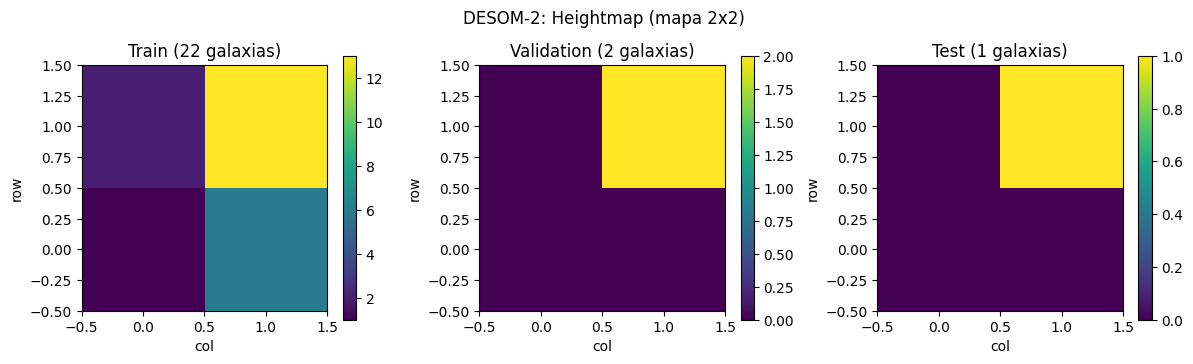

  desom2_heightmap.png


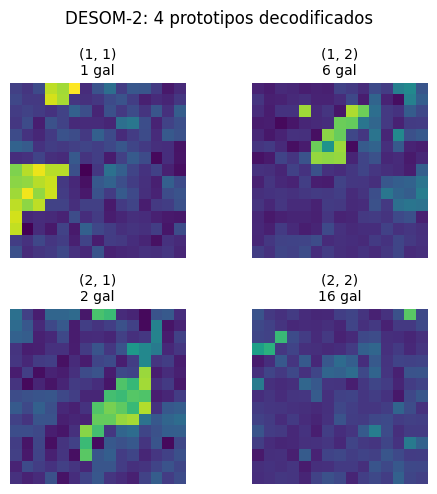

  desom2_templates.png


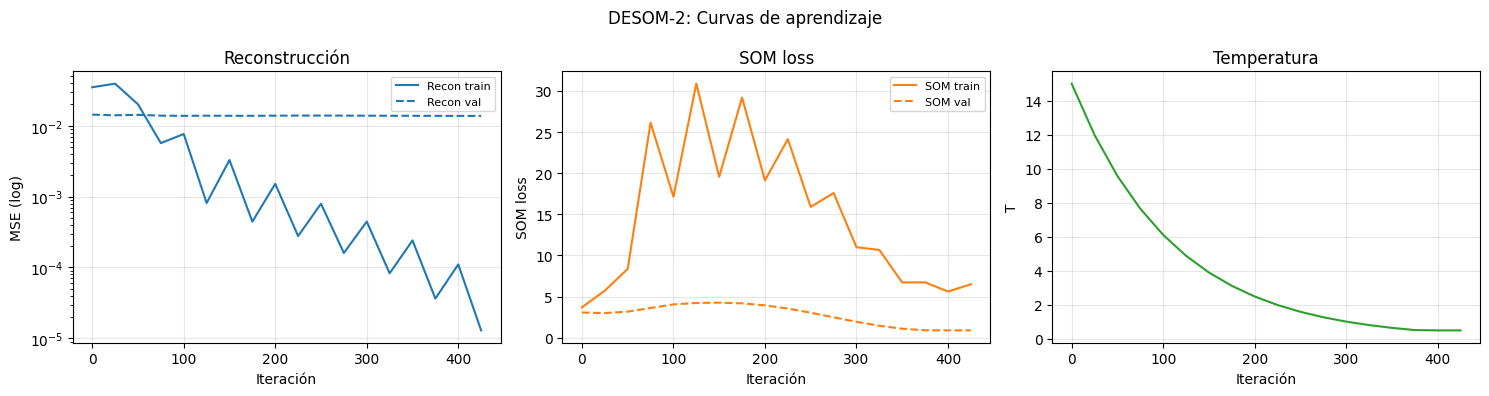

  desom2_learning_curves.png

RESUMEN CELDA 4.4 — BMU Y FIGURAS
  Galaxias:    16
  Nodos:       4

  train       : MSE=0.000044, nodos=4/4, topo_err=0.0000
  validation  : MSE=0.013779, nodos=1/4, topo_err=0.0000
  test        : MSE=0.040733, nodos=1/4, topo_err=0.0000

  Assignments: galaxy_assignments.csv
  Prototipos:  decoded_prototypes.npz
CELDA 4.4 COMPLETADA

-> Continua con la CELDA 4.5 (marcar Etapa 4 como completa).


In [28]:
# ============================================================================
# CELDA 4.4 — BMU DE GALAXIAS Y FIGURAS
# ============================================================================
# Esta celda:
#   1. Carga el modelo DESOM-2 entrenado.
#   2. Calcula BMU para cada galaxia.
#   3. Calcula métricas (MSE, ocupación, topographic error).
#   4. Guarda galaxy_assignments.csv.
#   5. Genera figuras de diagnóstico.
# ============================================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 70)
print("CELDA 4.4 — BMU DE GALAXIAS Y FIGURAS")
print("=" * 70)


# ============================================================================
# 1. Cargar inputs y modelo
# ============================================================================
INPUTS_PATH = CTX.desom2_dir / 'inputs_and_split.npz'
WEIGHTS_PATH = CTX.desom2_dir / 'DESOM2_model_final.h5'

require(INPUTS_PATH.exists(), f'Falta: {INPUTS_PATH}')
require(WEIGHTS_PATH.exists(), f'Falta: {WEIGHTS_PATH}')

print(f"\n[1/4] Cargando datos y modelo...")

with np.load(INPUTS_PATH, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    gal_mangaID = np.array(z['mangaID'], dtype=str)
    gal_plateifu = np.array(z['plateifu'], dtype=str)
    n_spectra = np.array(z['n_spectra'], dtype=np.int32)
    split = np.array(z['split'], dtype=str)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)
    map_size_desom1 = tuple(int(v) for v in z['map_size_desom1'])

# Reconstruir modelo
CFG_D2 = CTX.cfg['desom2']
input_dims = (map_size_desom1[0], map_size_desom1[1], 1)
map_size = tuple(CFG_D2['map_size'])

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_d2 = DESOM2(
    input_dims=input_dims,
    map_size=map_size,
    latent_dims=CFG_D2['latent_dims'],
)
model_d2.initialize()
model_d2.model.load_weights(str(WEIGHTS_PATH))

n_gal = len(X)
n_nodes = map_size[0] * map_size[1]
print(f"  Galaxias: {n_gal}")
print(f"  Nodos:    {n_nodes} ({map_size[0]}x{map_size[1]})")


# ============================================================================
# 2. Calcular BMU y reconstrucción
# ============================================================================
print(f"\n[2/4] Calculando BMU y reconstrucción...")

recon_all, dist_all = model_d2.model.predict(X, verbose=0)
bmu_all = dist_all.argmin(axis=1)

require(np.isfinite(recon_all).all(), 'NaN en reconstrucción')
require(np.isfinite(dist_all).all(), 'NaN en distancias')

print(f"  Reconstrucción: {recon_all.shape}")


# ============================================================================
# 3. Métricas
# ============================================================================
print(f"\n[3/4] Calculando métricas...")

def topographic_error(dists, map_size):
    """Fracción de galaxias cuyos 2 mejores nodos no son adyacentes."""
    h, w = map_size
    def is_adjacent(k, l):
        return (abs(k // w - l // w) == 1 and k % w == l % w) or \
               (abs(k // w - l // w) == 0 and abs(k % w - l % w) == 1)
    n = len(dists)
    if n == 0:
        return np.nan
    bt = np.argsort(dists, axis=1)[:, :2]
    return float(1.0 - np.mean([is_adjacent(bt[i, 0], bt[i, 1]) for i in range(n)]))

metrics = {}
for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    if len(idx) == 0:
        continue
    mse = float(np.mean(np.square(recon_all[idx].astype(np.float64) - X[idx])))
    n_occ = len(np.unique(bmu_all[idx]))
    topo_err = topographic_error(dist_all[idx], map_size)
    metrics[name] = {
        'n_galaxies': int(len(idx)),
        'mse': mse,
        'n_occupied_nodes': int(n_occ),
        'occupancy_percent': float(n_occ / n_nodes * 100),
        'topographic_error': topo_err,
    }
    print(f"  {name:12s}: MSE={mse:.6f}, nodos={n_occ}/{n_nodes}, topo_err={topo_err:.4f}")

atomic_write_json(CTX.desom2_dir / 'metrics.json', metrics)


# ============================================================================
# 4. Guardar assignments
# ============================================================================
print(f"\n[4/4] Guardando assignments...")

# Convertir bmu lineal a (row, col) en el mapa 2x2 (o el tamaño actual)
def bmu_to_rc(bmu, map_size):
    return bmu // map_size[1], bmu % map_size[1]

rows, cols = bmu_to_rc(bmu_all, map_size)

ASSIGNMENTS_PATH = CTX.desom2_dir / 'galaxy_assignments.csv'
pd.DataFrame({
    'mangaID': gal_mangaID,
    'plateifu': gal_plateifu,
    'split_desom2': split,
    'bmu': bmu_all,
    'row': rows,
    'col': cols,
    'n_spectra': n_spectra,
}).to_csv(ASSIGNMENTS_PATH, index=False)
print(f"  {ASSIGNMENTS_PATH.name}")

# --- Distribución de galaxias por nodo ---
print(f"\n  Distribución por nodo:")
for node in range(n_nodes):
    mask = bmu_all == node
    n = int(mask.sum())
    if n > 0:
        print(f"    nodo {node} (row {node // map_size[1]}, col {node % map_size[1]}): "
              f"{n} galaxias")
    else:
        print(f"    nodo {node} (row {node // map_size[1]}, col {node % map_size[1]}): "
              f"VACÍO")


# ============================================================================
# 5. Prototipos decodificados
# ============================================================================
print(f"\nCalculando prototipos decodificados...")
proto_decoded = model_d2.decode(model_d2.prototypes)  # (n_nodes, 15, 15, 1)
PROTO_PATH = CTX.desom2_dir / 'decoded_prototypes.npz'
np.savez_compressed(
    PROTO_PATH,
    fingerprints=proto_decoded,
    map_size=np.array(map_size),
    map_size_desom1=np.array(map_size_desom1),
)
print(f"  {PROTO_PATH.name} ({PROTO_PATH.stat().st_size/1e3:.1f} KB)")


# ============================================================================
# 6. Figuras
# ============================================================================
print(f"\nGenerando figuras...")
FIG_DIR = CTX.figures_dir


# --- Figura 1: Heightmap DESOM-2 (train/val/test) ---
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, name, idx in [
    (axes[0], 'Train', train_idx),
    (axes[1], 'Validation', val_idx),
    (axes[2], 'Test', test_idx),
]:
    if len(idx) == 0:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(f'{name} (0 galaxias)')
        continue
    counts = np.bincount(bmu_all[idx], minlength=n_nodes).reshape(map_size)
    im = ax.imshow(counts, origin='lower', cmap='viridis')
    ax.set_title(f'{name} ({len(idx)} galaxias)')
    ax.set_xlabel('col')
    ax.set_ylabel('row')
    fig.colorbar(im, ax=ax)

fig.suptitle(f'DESOM-2: Heightmap (mapa {map_size[0]}x{map_size[1]})')
fig.tight_layout()
fig.savefig(FIG_DIR / 'desom2_heightmap.png', dpi=140, bbox_inches='tight')
plt.show()
print(f"  desom2_heightmap.png")


# --- Figura 2: Prototipos decodificados (grid) ---
n_side = map_size[0]
fig, axes = plt.subplots(n_side, n_side, figsize=(2.5 * n_side, 2.5 * n_side))
if n_side == 1:
    axes = np.array([[axes]])
for node in range(n_nodes):
    ax = axes[node // n_side, node % n_side]
    fp = proto_decoded[node, :, :, 0]
    im = ax.imshow(fp, cmap='viridis', vmin=float(proto_decoded.min()),
                   vmax=float(proto_decoded.max()))
    n_gal = int((bmu_all == node).sum())
    ax.set_title(f'({node // n_side + 1}, {node % n_side + 1})\n{n_gal} gal',
                 fontsize=10)
    ax.axis('off')
fig.suptitle(f'DESOM-2: {n_nodes} prototipos decodificados')
fig.tight_layout()
fig.savefig(FIG_DIR / 'desom2_templates.png', dpi=140, bbox_inches='tight')
plt.show()
print(f"  desom2_templates.png")


# --- Figura 3: Curvas de aprendizaje ---
LOG_PATH = CTX.desom2_dir / f'desom2_log_{CFG_D2["latent_dims"]}.csv'
if LOG_PATH.exists():
    log_df = pd.read_csv(LOG_PATH)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].semilogy(log_df['iter'], log_df['recon_loss'].clip(lower=1e-7),
                     label='Recon train', color='C0')
    if 'val_recon' in log_df.columns:
        axes[0].semilogy(log_df['iter'], log_df['val_recon'].clip(lower=1e-7),
                         label='Recon val', color='C0', linestyle='--')
    axes[0].set_xlabel('Iteración')
    axes[0].set_ylabel('MSE (log)')
    axes[0].set_title('Reconstrucción')
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    axes[1].plot(log_df['iter'], log_df['som_loss'], label='SOM train', color='C1')
    if 'val_som' in log_df.columns:
        axes[1].plot(log_df['iter'], log_df['val_som'], label='SOM val',
                     color='C1', linestyle='--')
    axes[1].set_xlabel('Iteración')
    axes[1].set_ylabel('SOM loss')
    axes[1].set_title('SOM loss')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    axes[2].plot(log_df['iter'], log_df['T'], color='C2')
    axes[2].set_xlabel('Iteración')
    axes[2].set_ylabel('T')
    axes[2].set_title('Temperatura')
    axes[2].grid(alpha=0.3)

    fig.suptitle('DESOM-2: Curvas de aprendizaje')
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'desom2_learning_curves.png', dpi=140, bbox_inches='tight')
    plt.show()
    print(f"  desom2_learning_curves.png")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN CELDA 4.4 — BMU Y FIGURAS")
print("=" * 70)
print(f"  Galaxias:    {n_gal}")
print(f"  Nodos:       {n_nodes}")
print()
for name in ['train', 'validation', 'test']:
    if name in metrics:
        m = metrics[name]
        print(f"  {name:12s}: MSE={m['mse']:.6f}, "
              f"nodos={m['n_occupied_nodes']}/{n_nodes}, "
              f"topo_err={m['topographic_error']:.4f}")
print()
print(f"  Assignments: {ASSIGNMENTS_PATH.name}")
print(f"  Prototipos:  {PROTO_PATH.name}")
print("=" * 70)
print("CELDA 4.4 COMPLETADA")
print("=" * 70)
print("\n-> Continua con la CELDA 4.5 (marcar Etapa 4 como completa).")

In [29]:
# ============================================================================
# CELDA 4.5 — MARCAR ETAPA 4 COMO COMPLETA Y RESUMEN DEL PIPELINE
# ============================================================================
# Esta celda:
#   1. Verifica outputs de Etapa 4.
#   2. Marca stage_04 = complete.
#   3. Verifica que las 4 etapas están completas.
#   4. Imprime resumen ejecutivo del experimento.
# ============================================================================

from pathlib import Path

print("=" * 70)
print("CELDA 4.5 — MARCAR ETAPA 4 COMO COMPLETA")
print("=" * 70)


# ============================================================================
# 1. Verificar outputs de Etapa 4
# ============================================================================
outputs_to_check = {
    'desom2_model': CTX.desom2_dir / 'DESOM2_model_final.h5',
    'inputs_and_split': CTX.desom2_dir / 'inputs_and_split.npz',
    'assignments': CTX.desom2_dir / 'galaxy_assignments.csv',
    'decoded_prototypes': CTX.desom2_dir / 'decoded_prototypes.npz',
    'metrics': CTX.desom2_dir / 'metrics.json',
    'training_metadata': CTX.desom2_dir / 'training_metadata.json',
}

print(f"\nVerificando outputs de Etapa 4:")
missing = []
for name, path in outputs_to_check.items():
    status = '✓' if path.exists() else '✗'
    if not path.exists():
        missing.append(name)
    size_str = f"{path.stat().st_size / 1024:.1f} KB" if path.exists() else "-"
    print(f"  {status} {name:22s} {size_str:>10s}")

require(len(missing) == 0, f'Faltan outputs: {missing}')


# ============================================================================
# 2. Calcular hashes
# ============================================================================
model_weights_path = CTX.desom2_dir / 'DESOM2_model_final.h5'
output_sha = sha256_file(model_weights_path)

fp_path = CTX.fingerprints_dir / 'fingerprints.npz'
input_sha = sha256_file(fp_path)


# ============================================================================
# 3. Actualizar state
# ============================================================================
training_metadata = json.loads(
    (CTX.desom2_dir / 'training_metadata.json').read_text()
)
metrics = json.loads(
    (CTX.desom2_dir / 'metrics.json').read_text()
)

CTX.update_stage(
    'stage_04',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_04'),
    input_hash=input_sha,
    output_hash=output_sha,
    summary={
        'n_parameters': training_metadata['n_parameters'],
        'n_train': training_metadata['n_train'],
        'n_val': training_metadata['n_val'],
        'n_test': training_metadata['n_test'],
        'training_seconds': training_metadata['elapsed_seconds'],
        'map_size': training_metadata['map_size'],
        'mse_train': metrics['train']['mse'],
        'mse_val': metrics['validation']['mse'],
        'mse_test': metrics['test']['mse'],
        'n_occupied_nodes_train': metrics['train']['n_occupied_nodes'],
        'model_weights_sha256': output_sha,
    }
)

print(f"\n✓ stage_04 marcada como 'complete'")


# ============================================================================
# 4. Verificar estado global del pipeline
# ============================================================================
print(f"\nVerificando estado global del pipeline...")
all_stages = CTX.state['stages']
all_complete = all(
    all_stages[sn]['status'] == 'complete'
    for sn in ['stage_01', 'stage_02', 'stage_03', 'stage_04']
)

if all_complete:
    print(f"  ✓ Las 4 etapas están completas")
else:
    pending = [sn for sn in ['stage_01', 'stage_02', 'stage_03', 'stage_04']
               if all_stages[sn]['status'] != 'complete']
    print(f"  ⚠️  Etapas no completas: {pending}")


# ============================================================================
# 5. Resumen ejecutivo del pipeline
# ============================================================================
print("\n" + "=" * 70)
print("🎉 PIPELINE COMPLETO 🎉")
print("=" * 70)

# --- Config ---
print(f"\nEXPERIMENTO:")
print(f"  Run ID:      {CTX.run_id}")
print(f"  n_target:    {CTX.cfg['n_target']}")
print(f"  Modo:        {CTX.cfg['config_mode']}")
print(f"  Seed:        {CTX.cfg['seed']}")

# --- Tiempos ---
print(f"\nTIEMPOS:")
total_seconds = 0
for sn in ['stage_01', 'stage_02', 'stage_03', 'stage_04']:
    stage = all_stages[sn]
    if stage['status'] == 'complete' and stage.get('completed_at') and stage.get('started_at'):
        try:
            t0 = datetime.fromisoformat(stage['started_at'].replace('Z', '+00:00'))
            t1 = datetime.fromisoformat(stage['completed_at'].replace('Z', '+00:00'))
            elapsed = (t1 - t0).total_seconds()
            total_seconds += elapsed
            print(f"  {stage['name']:<45s} {format_duration(elapsed):>10s}")
        except Exception:
            print(f"  {stage['name']:<45s} {'?':>10s}")
print(f"  {'─' * 55}")
print(f"  {'TOTAL':<45s} {format_duration(total_seconds):>10s}")

# --- Resultados por etapa ---
print(f"\nRESULTADOS:")

# Etapa 1
s1 = all_stages['stage_01'].get('summary', {})
print(f"  Etapa 1 - Extracción:")
print(f"    Galaxias procesadas:    {s1.get('n_galaxies', '?')}")
print(f"    Espectros candidatos:   {s1.get('n_spectra', '?')}")
print(f"    Espectros S/N ≥ 20:     {s1.get('n_spectra_sn20', '?')}")

# Etapa 2
s2 = all_stages['stage_02'].get('summary', {})
print(f"  Etapa 2 - Consolidación:")
print(f"    Espectros:              {s2.get('n_spectra', '?')}")
print(f"    Split:                  train={s2.get('n_train', '?')} / "
      f"val={s2.get('n_validation', '?')} / test={s2.get('n_test', '?')}")

# Etapa 3
s3 = all_stages['stage_03'].get('summary', {})
print(f"  Etapa 3 - DESOM-1:")
print(f"    Parámetros:             {s3.get('n_parameters', 0):,}")
print(f"    MSE train/val/test:     {s3.get('mse_train', 0):.6f} / "
      f"{s3.get('mse_val', 0):.6f} / {s3.get('mse_test', 0):.6f}")
print(f"    Ocupación de nodos:     {s3.get('n_occupied_nodes_train', '?')}/225")
print(f"    Fingerprints:           {s3.get('fingerprints_path', '?')}")

# Etapa 4
s4 = all_stages['stage_04'].get('summary', {})
print(f"  Etapa 4 - DESOM-2:")
print(f"    Parámetros:             {s4.get('n_parameters', 0):,}")
print(f"    Mapa:                   {s4.get('map_size', '?')}")
print(f"    MSE train/val/test:     {s4.get('mse_train', 0):.6f} / "
      f"{s4.get('mse_val', 0):.6f} / {s4.get('mse_test', 0):.6f}")
print(f"    Nodos ocupados:         {s4.get('n_occupied_nodes_train', '?')}")

# --- Archivos finales ---
print(f"\nARCHIVOS FINALES:")
print(f"  Fingerprints:  {CTX.fingerprints_dir / 'fingerprints.npz'}")
print(f"  Assignments:   {CTX.desom2_dir / 'galaxy_assignments.csv'}")
print(f"  Figuras:       {CTX.figures_dir} ({len(list(CTX.figures_dir.glob('*.png')))} archivos)")
print(f"  Checkpoints:   {CTX.desom1_dir / 'checkpoints'}")

# --- Nota sobre el tamaño de muestra ---
print(f"\nNOTA:")
if CTX.cfg['n_target'] < 100:
    print(f"  Este experimento usó n_target={CTX.cfg['n_target']} (muy pequeño).")
    print(f"  Los resultados científicos son limitados. Para resultados")
    print(f"  significativos, considera crear un experimento con n_target=500.")
elif CTX.cfg['n_target'] < 1000:
    print(f"  Este experimento usó n_target={CTX.cfg['n_target']}.")
    print(f"  Los resultados son razonables, aunque el paper usó 4609.")
else:
    print(f"  Este experimento usó n_target={CTX.cfg['n_target']}, comparable al paper.")

print("\n" + "=" * 70)
print("CELDA 4.5 COMPLETADA")
print("=" * 70)
print("\n🎉 ¡EL PIPELINE ESTÁ COMPLETO! 🎉")
print(f"\nTodos los productos están en: {CTX.run_dir}")

CELDA 4.5 — MARCAR ETAPA 4 COMO COMPLETA

Verificando outputs de Etapa 4:
  ✓ desom2_model            3652.0 KB
  ✓ inputs_and_split           5.3 KB
  ✓ assignments                0.9 KB
  ✓ decoded_prototypes         3.9 KB
  ✓ metrics                    0.5 KB
  ✓ training_metadata          0.7 KB

✓ stage_04 marcada como 'complete'

Verificando estado global del pipeline...
  ✓ Las 4 etapas están completas

🎉 PIPELINE COMPLETO 🎉

EXPERIMENTO:
  Run ID:      exp_50_scaled_v20_prueba_1
  n_target:    50
  Modo:        scaled
  Seed:        20261002

TIEMPOS:
  Etapa 1 - Extracción y preprocesamiento           2h 08m
  Etapa 2 - Consolidación y split                  13m 57s
  Etapa 3 - DESOM-1                                 2h 44m
  Etapa 4 - DESOM-2                                 8m 12s
  ───────────────────────────────────────────────────────
  TOTAL                                             5h 14m

RESULTADOS:
  Etapa 1 - Extracción:
    Galaxias procesadas:    25
    Espectro